In [ ]:
import socket, psutil

hostname = socket.gethostname()
mem = psutil.virtual_memory().total / (1024**3)

print(f"当前运行节点: {hostname}")
print(f"当前节点内存: {mem:.2f} GB")

当前运行节点: fc30669
当前节点内存: 755.41 GB


# 0. Import Package

In [2]:
import math
import qiskit
import itertools
import numpy as np
from scipy.spatial import Voronoi
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from numpy.linalg import eigvalsh
from collections import defaultdict
from itertools import product

#from qiskit import QuantumCircuit, execute
# from qiskit_aer import Aer
from qiskit.quantum_info import Pauli, SparsePauliOp, Statevector
from qiskit.circuit.library import QFT
from qiskit.circuit.library import PauliEvolutionGate
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
# from qiskit_algorithms import VQE
# from qiskit_algorithms.optimizers import SLSQP
from qiskit.circuit.library import TwoLocal
# from qiskit_aer.primitives import Estimator as AerEstimator
from qiskit.primitives import StatevectorEstimator as Estimator
#from qiskit.opflow import PauliTrotterEvolution

In [3]:
print(qiskit.__version__)

2.3.1


# 1. Geometrical Structure
## 1.1 becke_radial_grid

In [4]:
# try becke_radial_grid_clamped
def becke_radial_grid(num_r, alpha, nu):
    # 计算 u 空间的步长
    du = 1.0 / (num_r + 1)
    
    # 这里的技巧是偏移 0.5 * du
    # 使得第一个采样点在 0.5*du，而原点 u=0 恰好被“夹”住
    u = np.linspace(0.5 * du, 1.0 - 0.5 * du, num_r)

    # 防止 1 - u**nu 出现 <= 0 导致 log 产生 NaN 或 -inf
    inner = np.clip(1.0 - u**nu, 1e-16, 1.0)
    
    # 映射回 r 空间
    r = -alpha * np.log(inner)
    return r

## Lebedev
### Lebedev_6

In [5]:
def lebedev_6():
    # 6-point Lebedev grid
    # 精确到 l = 1
    w = 4*np.pi/6
    pts = np.array([
        [ 1, 0, 0],
        [-1, 0, 0],
        [ 0, 1, 0],
        [ 0,-1, 0],
        [ 0, 0, 1],
        [ 0, 0,-1],
    ], dtype=float)
    weights = np.full(6, w)
    return pts, weights


### Lebedev_14

In [6]:
def lebedev_14():
    a = np.sqrt(1/3)
    pts = np.array([
        [ 1, 0, 0], [-1, 0, 0],
        [ 0, 1, 0], [ 0,-1, 0],
        [ 0, 0, 1], [ 0, 0,-1],
        [ a, a, a], [ a, a,-a],
        [ a,-a, a], [ a,-a,-a],
        [-a, a, a], [-a, a,-a],
        [-a,-a, a], [-a,-a,-a],
    ], dtype=float)

    w1 = 4*np.pi/21
    w2 = 4*np.pi/84
    weights = np.array([w1]*6 + [w2]*8)
    return pts, weights


### Lebedev_26

In [7]:
def lebedev_26():
    a = np.sqrt(1/3)
    b = np.sqrt(3/5)
    pts = np.array([
        [ 1, 0, 0], [-1, 0, 0],
        [ 0, 1, 0], [ 0,-1, 0],
        [ 0, 0, 1], [ 0, 0,-1],
        [ a, a, a], [ a, a,-a], [ a,-a, a], [ a,-a,-a],
        [-a, a, a], [-a, a,-a], [-a,-a, a], [-a,-a,-a],
        [ b, 0, 0], [-b, 0, 0],
        [ 0, b, 0], [ 0,-b, 0],
        [ 0, 0, b], [ 0, 0,-b],
        [ 0, a, b], [ 0, a,-b], [ 0,-a, b], [ 0,-a,-b],
        [ a, 0, b], [ a, 0,-b]
    ], dtype=float)

    w1 = 4*np.pi/30
    w2 = 4*np.pi/120
    w3 = 4*np.pi/60
    weights = np.array([w1]*6 + [w2]*8 + [w3]*12)
    return pts, weights


### Lebedev_50

In [8]:
def lebedev_50():
    """
    Full Lebedev 50-point spherical grid.
    Returns:
        pts: (50,3) array of unit vectors
        w:   (50,) array of weights
    """

    pts = np.array([
        [ 0.0,  0.0,  1.0],
        [ 0.0,  0.0, -1.0],
        [ 1.0,  0.0,  0.0],
        [-1.0,  0.0,  0.0],
        [ 0.0,  1.0,  0.0],
        [ 0.0, -1.0,  0.0],

        [ 0.5773502691896257,  0.5773502691896257,  0.5773502691896257],
        [ 0.5773502691896257,  0.5773502691896257, -0.5773502691896257],
        [ 0.5773502691896257, -0.5773502691896257,  0.5773502691896257],
        [ 0.5773502691896257, -0.5773502691896257, -0.5773502691896257],
        [-0.5773502691896257,  0.5773502691896257,  0.5773502691896257],
        [-0.5773502691896257,  0.5773502691896257, -0.5773502691896257],
        [-0.5773502691896257, -0.5773502691896257,  0.5773502691896257],
        [-0.5773502691896257, -0.5773502691896257, -0.5773502691896257],

        [ 0.0,  0.5257311121191336,  0.85065080835204],
        [ 0.0,  0.5257311121191336, -0.85065080835204],
        [ 0.0, -0.5257311121191336,  0.85065080835204],
        [ 0.0, -0.5257311121191336, -0.85065080835204],

        [ 0.5257311121191336,  0.85065080835204,  0.0],
        [ 0.5257311121191336, -0.85065080835204,  0.0],
        [-0.5257311121191336,  0.85065080835204,  0.0],
        [-0.5257311121191336, -0.85065080835204,  0.0],

        [ 0.85065080835204,  0.0,  0.5257311121191336],
        [ 0.85065080835204,  0.0, -0.5257311121191336],
        [-0.85065080835204,  0.0,  0.5257311121191336],
        [-0.85065080835204,  0.0, -0.5257311121191336],

        [ 0.30901699437494745,  0.5,  0.8090169943749475],
        [ 0.30901699437494745,  0.5, -0.8090169943749475],
        [ 0.30901699437494745, -0.5,  0.8090169943749475],
        [ 0.30901699437494745, -0.5, -0.8090169943749475],
        [-0.30901699437494745,  0.5,  0.8090169943749475],
        [-0.30901699437494745,  0.5, -0.8090169943749475],
        [-0.30901699437494745, -0.5,  0.8090169943749475],
        [-0.30901699437494745, -0.5, -0.8090169943749475],

        [ 0.5,  0.8090169943749475,  0.30901699437494745],
        [ 0.5,  0.8090169943749475, -0.30901699437494745],
        [ 0.5, -0.8090169943749475,  0.30901699437494745],
        [ 0.5, -0.8090169943749475, -0.30901699437494745],
        [-0.5,  0.8090169943749475,  0.30901699437494745],
        [-0.5,  0.8090169943749475, -0.30901699437494745],
        [-0.5, -0.8090169943749475,  0.30901699437494745],
        [-0.5, -0.8090169943749475, -0.30901699437494745],

        [ 0.8090169943749475,  0.30901699437494745,  0.5],
        [ 0.8090169943749475,  0.30901699437494745, -0.5],
        [ 0.8090169943749475, -0.30901699437494745,  0.5],
        [ 0.8090169943749475, -0.30901699437494745, -0.5],
        [-0.8090169943749475,  0.30901699437494745,  0.5],
        [-0.8090169943749475,  0.30901699437494745, -0.5],
        [-0.8090169943749475, -0.30901699437494745,  0.5],
        [-0.8090169943749475, -0.30901699437494745, -0.5],
    ])

    # 权重（全部 50 个）
    w = np.array([
        0.126984126984127, 0.126984126984127,
        0.126984126984127, 0.126984126984127,
        0.126984126984127, 0.126984126984127,

        0.047619047619048, 0.047619047619048,
        0.047619047619048, 0.047619047619048,
        0.047619047619048, 0.047619047619048,
        0.047619047619048, 0.047619047619048,

        0.075, 0.075, 0.075, 0.075,
        0.075, 0.075, 0.075, 0.075,
        0.075, 0.075, 0.075, 0.075,
        0.075, 0.075, 0.075, 0.075,
        0.075, 0.075, 0.075, 0.075,
        0.075, 0.075, 0.075, 0.075,
        0.075, 0.075, 0.075, 0.075,
        0.075, 0.075, 0.075, 0.075,
    ])

    return pts, w


### Lebedev_74

In [9]:
def lebedev_74():
    """
    Full Lebedev 74-point spherical grid.
    Returns:
        pts: (74,3) array of unit vectors
        w:   (74,) array of weights
    """

    a = 0.45970084338098305
    b = 0.6285393610547089
    c = 0.322185354626569
    d = 0.8360955967490217

    pts = np.array([
        [ 0.0,  0.0,  1.0],
        [ 0.0,  0.0, -1.0],
        [ 1.0,  0.0,  0.0],
        [-1.0,  0.0,  0.0],
        [ 0.0,  1.0,  0.0],
        [ 0.0, -1.0,  0.0],

        [ a,  a,  a], [ a,  a,-a], [ a,-a,  a], [ a,-a,-a],
        [-a,  a,  a], [-a,  a,-a], [-a,-a,  a], [-a,-a,-a],

        [ b,  0,  c], [ b,  0,-c], [-b,  0,  c], [-b,  0,-c],
        [ 0,  b,  c], [ 0,  b,-c], [ 0,-b,  c], [ 0,-b,-c],
        [ c,  b,  0], [ c,-b,  0], [-c,  b,  0], [-c,-b,  0],

        [ d,  d,  0], [ d,-d,  0], [-d,  d,  0], [-d,-d,  0],
        [ d,  0,  d], [ d,  0,-d], [-d,  0,  d], [-d,  0,-d],
        [ 0,  d,  d], [ 0,  d,-d], [ 0,-d,  d], [ 0,-d,-d],

        [ 0.0,  a,  b], [ 0.0,  a,-b], [ 0.0,-a,  b], [ 0.0,-a,-b],
        [ a,  0.0,  b], [ a,  0.0,-b], [-a,  0.0,  b], [-a,  0.0,-b],
        [ b,  a,  0.0], [ b,-a,  0.0], [-b,  a,  0.0], [-b,-a,  0.0],

        [ c,  c,  d], [ c,  c,-d], [ c,-c,  d], [ c,-c,-d],
        [-c,  c,  d], [-c,  c,-d], [-c,-c,  d], [-c,-c,-d],

        [ d,  c,  c], [ d,  c,-c], [ d,-c,  c], [ d,-c,-c],
        [-d,  c,  c], [-d,  c,-c], [-d,-c,  c], [-d,-c,-c],

        [ c,  d,  c], [ c,  d,-c], [ c,-d,  c], [ c,-d,-c],
        [-c,  d,  c], [-c,  d,-c], [-c,-d,  c], [-c,-d,-c],
    ])

    w1 = 0.047619047619047616
    w2 = 0.0380952380952381
    w3 = 0.03214285714285714
    w4 = 0.02857142857142857

    w = np.array(
        [w1]*6 +
        [w2]*8 +
        [w3]*12 +
        [w4]*48
    )

    return pts, w


### Lebedev_86

In [10]:
def lebedev_86():
    """
    Full Lebedev 86-point spherical grid.
    Returns:
        pts: (86,3) array of unit vectors
        w:   (86,) array of weights
    """

    a = 0.2666354015167047
    b = 0.681507726536546
    c = 0.4174961227965453
    d = 0.872473431981953

    pts = np.array([
        [ 0.0,  0.0,  1.0],
        [ 0.0,  0.0, -1.0],
        [ 1.0,  0.0,  0.0],
        [-1.0,  0.0,  0.0],
        [ 0.0,  1.0,  0.0],
        [ 0.0, -1.0,  0.0],

        [ a,  a,  a], [ a,  a,-a], [ a,-a,  a], [ a,-a,-a],
        [-a,  a,  a], [-a,  a,-a], [-a,-a,  a], [-a,-a,-a],

        [ b,  0,  c], [ b,  0,-c], [-b,  0,  c], [-b,  0,-c],
        [ 0,  b,  c], [ 0,  b,-c], [ 0,-b,  c], [ 0,-b,-c],
        [ c,  b,  0], [ c,-b,  0], [-c,  b,  0], [-c,-b,  0],

        [ d,  d,  0], [ d,-d,  0], [-d,  d,  0], [-d,-d,  0],
        [ d,  0,  d], [ d,  0,-d], [-d,  0,  d], [-d,  0,-d],
        [ 0,  d,  d], [ 0,  d,-d], [ 0,-d,  d], [ 0,-d,-d],

        [ 0.0,  a,  b], [ 0.0,  a,-b], [ 0.0,-a,  b], [ 0.0,-a,-b],
        [ a,  0.0,  b], [ a,  0.0,-b], [-a,  0.0,  b], [-a,  0.0,-b],
        [ b,  a,  0.0], [ b,-a,  0.0], [-b,  a,  0.0], [-b,-a,  0.0],

        [ c,  c,  d], [ c,  c,-d], [ c,-c,  d], [ c,-c,-d],
        [-c,  c,  d], [-c,  c,-d], [-c,-c,  d], [-c,-c,-d],

        [ d,  c,  c], [ d,  c,-c], [ d,-c,  c], [ d,-c,-c],
        [-d,  c,  c], [-d,  c,-c], [-d,-c,  c], [-d,-c,-c],

        [ c,  d,  c], [ c,  d,-c], [ c,-d,  c], [ c,-d,-c],
        [-c,  d,  c], [-c,  d,-c], [-c,-d,  c], [-c,-d,-c],
    ])

    w1 = 0.0380952380952381
    w2 = 0.03214285714285714
    w3 = 0.02857142857142857
    w4 = 0.025396825396825397

    w = np.array(
        [w1]*6 +
        [w2]*8 +
        [w3]*12 +
        [w4]*60
    )

    return pts, w


### Lebedev grid select

In [11]:
def lebedev_grid(order):
    """
    Return Lebedev directions (unit vectors) and weights for a given order.
    order: one of {6, 14, 26, 38, 50, 74, 86, 110, 146, 170, 194, 230, 266, 302, 350}
    """
    if order == 6:
        return lebedev_6()
    elif order == 14:
        return lebedev_14()
    elif order == 26:
        return lebedev_26()
    elif order == 50:
        return lebedev_50()
    elif order == 74:
        return lebedev_74()
    elif order == 86:
        return lebedev_86()
    else:
        raise ValueError(f"Lebedev order {order} not implemented.")


## 3D adaptive grid for hydrogen using Lebedev

In [12]:
# 3D adaptive grid for hydrogen using Lebedev 2025 12 21

def hydrogen_adaptive_grid_lebedev(num_r, order, alpha, nu):
    # For the time being, we test the radial part via exponential stretch like r^1.5
    #r = np.linspace(0.1, r_max, num_r)**1.5
    # alpha=1.0
    # nu=2.0
    r = becke_radial_grid(num_r, alpha, nu)

    # r = r[r > 1e-3]
    
    leb_pts, leb_w = lebedev_grid(order)
    points = []
    for ri in r:
        for n in leb_pts:
            points.append( ri * n)

    points = np.array(points)
    #vor = Voronoi(points, qhull_options='Qbb Qc Qx QJ')
    vor = Voronoi(points, qhull_options='QJ')
    
    neighbors = {i: set() for i in range(len(points))}            
    for p, q in vor.ridge_points:
        neighbors[p].add(q)
        neighbors[q].add(p)
    for m in range(len(points)):
        for n in neighbors[m]:
            if m not in neighbors[n]:
                print("Asym neighbor:", m, n)
    return np.array(points), neighbors, vor

## generate 3D adaptive grid for hydrogen 

In [13]:
# 6, 14, 26, 50, 74, 86
num_r = 19
order = 26
alpha = 2
nu = 1.2
points, neighbors, vor = hydrogen_adaptive_grid_lebedev(num_r, order, alpha, nu)
length = len(points)
num_bits = math.ceil(math.log2(length))
num_qubits = num_bits
print(f"Number of points: {length}")
print(f"Number of bits: {num_bits}")
D_phys = length      # 252
M = num_bits
D = 2**M                  # 256

if D_phys < D:
    pad = D - D_phys
    # 用最后一个点复制填充（比全零更物理）
    pad_points = np.repeat(points[-1][None, :], pad, axis=0)
    points_ext = np.vstack([points, pad_points])
else:
    points_ext = points


Number of points: 494
Number of bits: 9


In [14]:
# %%script false
# points, neighbors, vor = hydrogen_adaptive_grid(num_r=30, num_theta=8, num_phi=16, r_max=5.0)

## Calculate the geometrical properties of facet

In [15]:
# calculate the geometrical properties of facet
def facet_geometry(vor, ridge_vertices):
    # 退化 facet：少于 3 个顶点
    if len(ridge_vertices) < 3:
        return None, None, 0.0

    verts = vor.vertices[ridge_vertices]

    # 计算法向量
    v1 = verts[1] - verts[0]
    v2 = verts[2] - verts[0]
    normal = np.cross(v1, v2)
    norm = np.linalg.norm(normal)
    if norm < 1e-12:
        return None, None, 0.0
    normal /= norm

    # 计算 centroid
    centroid = verts.mean(axis=0)

    # 计算面积（投影 + shoelace）
    ax = np.argmin(np.abs(normal))
    proj = np.delete(verts, ax, axis=1)
    c2 = proj.mean(axis=0)
    angles = np.arctan2(proj[:,1] - c2[1], proj[:,0] - c2[0])
    order = np.argsort(angles)
    proj = proj[order]
    x, y = proj[:,0], proj[:,1]
    area = 0.5 * np.abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

    if area < 1e-14:
        return None, None, 0.0

    return normal, centroid, area


## Calculate cell volume

In [16]:
def cell_volume(points, neighbors, sigma):
    N = len(points)
    volumes = np.zeros(N)

    # 计算 cell centroid
    cell_centroid = np.zeros((N,3))
    for m in range(N):
        centroids = [sigma[m][n]["centroid"] for n in neighbors[m] if n in sigma[m]]
        if centroids:
            cell_centroid[m] = np.mean(centroids, axis=0)
        else:
            cell_centroid[m] = points[m]

    # 计算体积
    for m in range(N):
        for n in neighbors[m]:
            if n not in sigma[m]:
                continue

            area = sigma[m][n]["area"]
            normal = sigma[m][n]["normal"]
            centroid_mn = sigma[m][n]["centroid"]

            h = abs(np.dot(cell_centroid[m] - centroid_mn, normal))
            if h < 1e-12:
                continue

            volumes[m] += area * h / 3.0

    # 避免 volume=0
    volumes[volumes < 1e-14] = 1e-14
    return volumes


## Plot the 3d hydrogen points

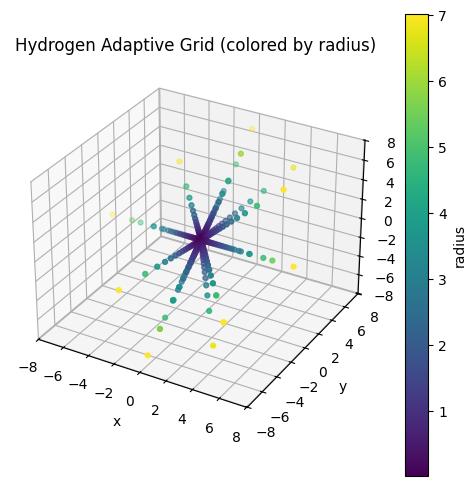

In [17]:
# Plot the 3d hydrogen points
import matplotlib.pyplot as plt


#points = hydrogen_adaptive_grid()

r = np.linalg.norm(points, axis = 1)

fig = plt.figure(figsize= (6, 6))
ax = fig.add_subplot(111, projection='3d')

p = ax.scatter(points[:,0], points[:,2], points[:, 2], c=r, cmap='viridis', s=12)
fig.colorbar(p, ax=ax, label='radius')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Hydrogen Adaptive Grid (colored by radius)')

plt.show()

## 几何预处理接口

In [18]:
from collections import defaultdict

def build_geometry(points, neighbors, vor):
    sigma = defaultdict(dict)

    for (p, q), rv in zip(vor.ridge_points, vor.ridge_vertices):
        if -1 in rv:
            continue

        normal, centroid, area = facet_geometry(vor, rv)
        if normal is None:
            continue

        sigma[p][q] = {
            "area": area,
            "normal": normal,
            "centroid": centroid,
            "ridge_vertices": rv
        }
        sigma[q][p] = {
            "area": area,
            "normal": -normal,
            "centroid": centroid,
            "ridge_vertices": rv
        }

    volumes = cell_volume(points, neighbors, sigma)
    return sigma, volumes


In [19]:
# 由于 Voronoi 可能产生一些孤立点（没有邻居），我们需要扩展 neighbors 和 volumes 来确保每个点都有足够的邻居和体积信息。同时让产生的neighbors等量的长度为 D（2^M），以便后续量子算法处理
# 这里我们简单地复制最后一个点的邻居和体积来填充（比全零更物理）
# 2026-06-03
def extend_neighbors_and_volumes(neighbors, volumes, new_len):
    old_len = len(neighbors)
    assert old_len == len(volumes)

    if old_len >= new_len:
        return neighbors, volumes

    pad = new_len - old_len

    neighbors_ext = list(neighbors)
    last_nei = neighbors[-1]  # 复制边界邻接
    for _ in range(pad):
        neighbors_ext.append(list(last_nei))

    volumes_ext = np.concatenate([volumes, np.repeat(volumes[-1], pad)])

    return neighbors_ext, volumes_ext


In [20]:
# 由于 Voronoi 可能产生一些孤立点（没有邻居），我们需要扩展 neighbors, sigma 和 volumes 来确保每个点都有足够的邻居和体积信息。同时让产生的neighbors等量的长度为 D（2^M），以便后续量子算法处理
# 这里我们简单地复制最后一个点的邻居和体积来填充（比全零更物理）
# 2026-06-05
def extend_geometry(neighbors, volumes, sigma, new_len):
    old_len = len(neighbors)
    assert old_len == len(volumes)
    assert old_len == len(sigma)

    # 1) neighbors: dict → list
    neighbors_ext = [list(neighbors[i]) for i in range(old_len)]

    # 2) volumes
    volumes_ext = np.array(volumes, dtype=float)

    # 3) sigma: deep copy
    import copy
    sigma_ext = [copy.deepcopy(sigma[i]) for i in range(old_len)]

    if old_len >= new_len:
        return neighbors_ext, volumes_ext, sigma_ext

    pad = new_len - old_len

    # 使用物理格点的平均体积作为填充点的默认体积（避免 0 或极小值）
    default_vol = float(np.median(volumes)) if old_len > 0 else 1.0

    # 4) 填充处理：填充格点作为孤立格点，不与现有物理格点建立虚假连接
    for _ in range(pad):
        neighbors_ext.append([])  # 无邻居，保证无向图对称性不被破坏
        volumes_ext = np.append(volumes_ext, default_vol)
        sigma_ext.append({})     # 无边界截面（area = 0

    return neighbors_ext, volumes_ext, sigma_ext


# 2. Assembling the first quantization Hamiltonian 
## Laplacian 构造
 ### L_{mn} in Eqn. 15

In [31]:
import numpy as np
import scipy.sparse as sp
from collections import defaultdict

def lapl_matr(vor, points, neighbors):
    """
    【升级版】3D Voronoi Laplacian (论文式 (15))
    - 接口保持不变
    - 使用升级后的 build_geometry + cell_volume
    - 输出为 CSR 稀疏矩阵（高效、可直接用于 ADAPT-VQE）
    """

    # ---------------------------------------------------------
    # 1. 获取 facet 几何信息 + Voronoi cell 体积
    # ---------------------------------------------------------
    sigma, volumes = build_geometry(points, neighbors, vor)

    N = len(points)
    num_bits = math.ceil(math.log2(N))
    dim = 1 << num_bits

    rows = []
    cols = []
    vals = []

    # ---------------------------------------------------------
    # 2. 构造 Laplacian（论文式 (15)）
    # ---------------------------------------------------------
    for m in range(N):
        Vm = volumes[m]
        diag_sum = 0.0

        # diagonal term
        for k in neighbors[m]:
            if k not in sigma[m]:
                continue

            area = sigma[m][k]["area"]
            dist = np.linalg.norm(points[m] - points[k])

            diag_sum += area / dist

        # L_mm = - (sum A_mk / d_mk) / V_m
        rows.append(m)
        cols.append(m)
        vals.append(-diag_sum / Vm)

        # off-diagonal terms
        for n in neighbors[m]:
            if n not in sigma[m]:
                continue

            area = sigma[m][n]["area"]
            dist = np.linalg.norm(points[m] - points[n])
            Vn = volumes[n]

            # L_mn = A_mn / (sqrt(Vm Vn) * d_mn)
            val = area / (np.sqrt(Vm * Vn) * dist)

            rows.append(m)
            cols.append(n)
            vals.append(val)

    # ---------------------------------------------------------
    # 3. 构造稀疏矩阵（dim × dim），物理块在左上角
    # ---------------------------------------------------------
    L = sp.csr_matrix((vals, (rows, cols)), shape=(dim, dim), dtype=np.float64)

    return L


### Construct symmetric laplacian

In [32]:
import numpy as np
import scipy.sparse as sp

def laplacian(points, neighbors, sigma, volumes):
    N = len(points)
    rows, cols, vals = [], [], []

    for m in range(N):
        Vm = volumes[m]
        diag_sum = 0.0

        for n in neighbors[m]:
            if n not in sigma[m]:
                continue

            area = sigma[m][n]["area"]
            dist = np.linalg.norm(points[m] - points[n])
            if dist < 1e-12:
                continue

            diag_sum += area / dist

        rows.append(m); cols.append(m); vals.append(-diag_sum / Vm)

        for n in neighbors[m]:
            if n not in sigma[m]:
                continue

            area = sigma[m][n]["area"]
            dist = np.linalg.norm(points[m] - points[n])
            if dist < 1e-12:
                continue

            val = area / (np.sqrt(Vm * volumes[n]) * dist)
            rows.append(m); cols.append(n); vals.append(val)

    L = sp.csr_matrix((vals, (rows, cols)), shape=(N, N), dtype=np.float64)
    # 强制均值对称化，消除几何数据结构可能带入的所有微小非对称/单向遗漏
    L_sym = (L + L.T) / 2.0
    return L_sym


## Coulombic potential

In [33]:
import numpy as np


def coulombic_potential(points, volumes, Z=2.0):
    """Pure Physics: Coulomb potential on N physical Voronoi points (No eps needed)."""
    N = len(points)

    # 1. Electron-Nucleus Attraction V_en(r) = -Z / |r|
    # (In standard Becke/radial grids, r_m > 0 for all mesh points)
    r_nu = np.linalg.norm(points, axis=1)
    ele_nu = -Z / r_nu

    # 2. Pairwise Euclidean Distances (N, N)
    diff = points[:, None, :] - points[None, :, :]
    r_ee = np.linalg.norm(diff, axis=-1)

    # 3. Off-diagonal Coulomb Repulsion 1 / |r_m - r_n|
    # Suppress divide-by-zero warning for m == n since diagonal is overwritten next
    with np.errstate(divide="ignore"):
        ele_ele = 1.0 / r_ee

    # 4. On-site Finite-Volume Cell Average: W_mm = 6 / (5 * R_m)
    v_m = np.maximum(volumes, 1e-12)
    R_m = (3.0 * v_m / (4.0 * np.pi)) ** (1.0 / 3.0)
    np.fill_diagonal(ele_ele, 6.0 / (5.0 * R_m))

    return ele_nu, ele_ele

## Hamiltonian Matrix

In [34]:
# This is modified version of the original hamilton_14 function to accommodate the new coulombic_potential for helium atom (Z=2.0)
# 2026-10-02
import math
import numpy as np
import scipy.sparse as sp


def hamilton_14(points, neighbors, sigma, volumes):
    N = len(points)
    num_bits = math.ceil(math.log2(N))
    dim = 1 << num_bits

    # 1. 一次性获取单体吸引势 ele_nu (dim,) 和 两体排斥势 ele_ele (dim, dim)
    L_sym = laplacian(points, neighbors, sigma, volumes)
    ele_nu_phys, ele_ele_phys = coulombic_potential(points, volumes, Z=2.0)

    # 2. 消除电子自相互作用：将 ele_ele 对角线 (m == n) 清零
    np.fill_diagonal(ele_ele_phys, 0.0)

    # Add a precautionary check to ensure there is no Inf or NaN in the potentials
    ele_nu_phys = np.nan_to_num(ele_nu_phys, nan=0.0, posinf=1e12, neginf=-1e12)
    ele_ele_phys = np.nan_to_num(ele_ele_phys, nan=0.0, posinf=1e12, neginf=-1e12)

    # Use sp.bmat to construct a block matrix with L_sym in the top-left corner and zeros elsewhere
    # to eliminate the SparseEfficiencyWarning
    if L_sym.shape != (dim, dim):
        pad_len = dim - N
        zero_tr = sp.csr_matrix((N, pad_len), dtype=np.float64) # right upper block
        zero_bl = sp.csr_matrix((pad_len, N), dtype=np.float64) # left lower block
        zero_br = sp.csr_matrix((pad_len, pad_len), dtype=np.float64) # right lower block
        L_dim = sp.bmat([[L_sym, zero_tr], [zero_bl, zero_br]], format="csr")
    else:
        L_dim = L_sym

    # padding the potential arrays to match the dimension
    ele_nu = np.zeros(dim, dtype=np.float64)
    ele_nu[:N] = ele_nu_phys # The front N elements are the physical potential, the rest are zeros

    ele_ele = np.zeros((dim, dim), dtype=np.float64)
    ele_ele[:N, :N] = ele_ele_phys # The top-left N xN block is the physical two-body potential, the rest are zeros

    # 3. 组装单体哈密顿量 h_1b (dim, dim)
    h_1b = -0.5 * L_dim + sp.diags(
        ele_nu, offsets=0, shape=(dim, dim), format="csr", dtype=np.float64
    )

    # 【关键屏蔽】：把 Padding 区域 (N 到 dim) 的单体势能抬高到 +1000.0 Hartree
    diag_mask = np.zeros(dim, dtype=np.float64)
    diag_mask[N:] = 1000.0  # 高能惩罚势垒
    # H_pad_1e = sp.diags(P * padding_mask, format="csr")
    
    h_1b += sp.diags(diag_mask, offsets=0, shape=(dim, dim), format="csr")
    
    # 4. 构建双电子单体算符 (h_1b ⊗ I + I ⊗ h_1b)，形状 (dim^2, dim^2)
    I_dim = sp.eye(dim, format="csr", dtype=np.float64)
    H_1b = sp.kron(h_1b, I_dim, format="csr") + sp.kron(I_dim, h_1b, format="csr")

    # 5. 直接复用 ele_ele 构建两体排斥势稀疏对角矩阵 (dim^2, dim^2)
    H_ee = sp.diags(
        ele_ele.flatten(),
        offsets=0,
        shape=(dim**2, dim**2),
        format="csr",
        dtype=np.float64,
    )

    # 6. 返回总双电子哈密顿量
    return H_1b + H_ee

In [35]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import LinearOperator, lobpcg


class SymmetricHeliumMatrixFreeOperator(LinearOperator):

    def __init__(self, h_1b, V_ee):
        """利用空间交换对称性 (X = X^T) 的 Matrix-Free 氦原子双电子哈密顿量算符

        参数:
            h_1b: (d, d) 单体稀疏哈密顿量
            V_ee: (d, d) 两体库仑排斥势 2D 矩阵
        """
        self.d = h_1b.shape[0]
        self.shape = (self.d**2, self.d**2)
        self.dtype = np.float64

        self.h_1b = h_1b.tocsr()
        self.V_ee = V_ee

        # Matrix-Free 计算对角线: diag(H) = diag(h1) ⊕ diag(h1) + V_ee
        diag_h1 = self.h_1b.diagonal()
        self.diag_H_2d = (diag_h1[:, np.newaxis] + diag_h1[np.newaxis, :]) + V_ee
        self.diag_H_flat = self.diag_H_2d.ravel()

    def _matvec(self, x):
        """单向量乘法 y = H @ x (利用 X = X^T 加速)"""
        X = x.reshape((self.d, self.d))

        # 1. 强制对称化 (保证在 Singlet 空间)
        X_sym = 0.5 * (X + X.T)

        # 2. 利用 X = X^T，仅需 1 次稀疏矩阵乘法：h_X = h1 @ X
        h_X = self.h_1b.dot(X_sym)

        # 3. Y = (h_X + h_X^T) + V_ee * X_sym
        Y = (h_X + h_X.T) + (self.V_ee * X_sym)

        return Y.ravel()

    def _matmat(self, Xblock):
        """显式实现多向量/块乘法 Yblock = H @ Xblock

        参数:
            Xblock: 形状为 (d^2, k) 的矩阵，包含 k 个试探向量
        """
        k = Xblock.shape[1]
        Yblock = np.empty_like(Xblock)

        for j in range(k):
            # 取出第 j 个向量并 reshape 为 2D 矩阵
            X = Xblock[:, j].reshape(self.d, self.d)

            # 1. 强制对称化: X_sym = (X + X^T) / 2
            X_sym = 0.5 * (X + X.T)

            # 2. 利用对称性：仅需 1 次 h_1b.dot(X_sym)
            h_X = self.h_1b.dot(X_sym)

            # 3. 组装结果 (h_X + h_X^T) + V_ee * X_sym
            Y = (h_X + h_X.T) + (self.V_ee * X_sym)

            Yblock[:, j] = Y.ravel()

        return Yblock

    def get_preconditioner(self, E_shift=None):
        """构造与 Matrix-Free 算符匹配的严格正定 (SPD) 平移预条件器"""
        if E_shift is None:
            E_shift = np.min(self.diag_H_flat) - 10.0

        inv_diag = 1.0 / (self.diag_H_flat - E_shift)

        def precond_matvec(x):
            if x.ndim == 2:
                return inv_diag[:, np.newaxis] * x
            return inv_diag * x

        return LinearOperator(
            shape=self.shape, matvec=precond_matvec, dtype=np.float64
        )

## Test Hamiltonian

In [36]:
# import numpy as np
sigma, volumes = build_geometry(points, neighbors, vor)
H_sparse = hamilton_14(points, neighbors, sigma, volumes)

# # 转成 dense matrix
# H = H_sparse.toarray()

# vals, vecs = np.linalg.eigh(H)
# print(vals[0])
# print(vals[-1])
# #print(vecs[0])
# print("================================")
neighbors_ext, volumes_ext, sigma_ext = extend_geometry(neighbors, volumes, sigma, D)

H_sparse_ext = hamilton_14(points_ext, neighbors_ext, sigma_ext, volumes_ext)

# H_ext = H_sparse_ext.toarray()
# vals_ext, vecs_ext = np.linalg.eigh(H_ext)
# print(vals_ext[0])
# print(vals_ext[-1])


In [37]:
# import os

# # 显式绑定你申请到的 CPU 核心数（例如 8 核）
# NUM_CORES = "8"

# os.environ["OMP_NUM_THREADS"] = NUM_CORES
# os.environ["MKL_NUM_THREADS"] = NUM_CORES
# os.environ["OPENBLAS_NUM_THREADS"] = NUM_CORES
# os.environ["NUMEXPR_NUM_THREADS"] = NUM_CORES

# print(f"已成功将底层多线程限制/绑定为 {NUM_CORES} 核并行！")

In [38]:
import time
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import LinearOperator, lobpcg

# =========================================================================
# 1. 构造【物理平滑初态】X0 (消除高频噪声与 Padding 污染)
# =========================================================================
N = len(points)  # 物理节点数
D = H_sparse.shape[0]  # 总维度 dim^2
dim = int(np.sqrt(D))

# (a) 构建物理单电子类氢波函数 phi(r) ~ exp(-Z * r)
r_coords = np.linalg.norm(points, axis=1)
phi_phys = np.exp(-1.6875 * r_coords)  # 氦原子最佳单电子变分参数 Z_eff = 1.6875
phi_phys /= np.linalg.norm(phi_phys)

# (b) Padding 扩展到单电子 dim 维 (Padding 区域填 0)
phi_dim = np.zeros(dim, dtype=np.float64)
phi_dim[:N] = phi_phys

# (c) 直积得到双电子初始波函数 Psi0(r1, r2) = phi(r1) * phi(r2)
X0 = np.kron(phi_dim, phi_dim).reshape(D, 1)
X0 /= np.linalg.norm(X0)

# =========================================================================
# 2. 构造【平移正定 (SPD)】对角预条件算符 M
# =========================================================================
diag_H = H_sparse.diagonal().copy()
min_diag = np.min(diag_H)

# 确保分母恒大于 0，使得预条件算符 M 严格正定 (SPD)
E_shift = min_diag - 10.0
inv_diag_H = 1.0 / (diag_H - E_shift)


def preconditioner_matvec(x):
    if x.ndim == 2:
        return inv_diag_H[:, np.newaxis] * x
    return inv_diag_H * x


M_precond = LinearOperator(
    shape=(D, D), matvec=preconditioner_matvec, dtype=np.float64
)

# =========================================================================
# 3. 运行物理初态 + SPD 预条件 LOBPCG
# =========================================================================
print(
    f"开始终极 LOBPCG 求解 (维度 D = {D}, 初始试探能量 E_init ≈ {np.dot(X0.T, H_sparse.dot(X0))[0,0]:.4f} Hartree)..."
)
t0 = time.time()

try:
    eigvals, eigvecs = lobpcg(
        A=H_sparse,
        X=X0,
        M=M_precond,  # 正定平移预条件
        tol=1e-5,  # 绝对残差公差
        maxiter=100,  # 迭代步数
        largest=False,
        verbosityLevel=1,
    )

    t_calc = time.time() - t0
    E0 = eigvals[0]
    psi0 = eigvecs[:, 0]

    print(f"\n[LOBPCG 成功收敛！]")
    print(f"求解耗时: {t_calc:.2f} 秒")
    print(f"氦原子基态能量 E_0 = {E0:.6f} Hartree")

except Exception as e:
    print(f"\n[LOBPCG 求解中断]: {e}")

开始终极 LOBPCG 求解 (维度 D = 262144, 初始试探能量 E_init ≈ 1890.5102 Hartree)...
Solving standard eigenvalue problem with preconditioning

matrix size 262144
block size 1

No constraints


iteration 0
current block size: 1
eigenvalue(s):
[1890.51023735]
residual norm(s):
[3473.87595824]
iteration 1
current block size: 1
eigenvalue(s):
[33.385208]
residual norm(s):
[135.69086947]
iteration 2
current block size: 1
eigenvalue(s):
[10.59027242]
residual norm(s):
[76.36268862]
iteration 3
current block size: 1
eigenvalue(s):
[5.32133082]
residual norm(s):
[48.5549375]
iteration 4
current block size: 1
eigenvalue(s):
[2.77908774]
residual norm(s):
[30.96605736]
iteration 5
current block size: 1
eigenvalue(s):
[1.33334568]
residual norm(s):
[27.45396152]
iteration 6
current block size: 1
eigenvalue(s):
[0.42783932]
residual norm(s):
[23.144794]
iteration 7
current block size: 1
eigenvalue(s):
[-0.27475397]
residual norm(s):
[17.50361366]
iteration 8
current block size: 1
eigenvalue(s):
[-0.81995937]
resi

/tmp/ipykernel_3288894/1306986223.py:56: UserWarning: Exited at iteration 100 with accuracies 
[0.01072761]
not reaching the requested tolerance 1e-05.
Use iteration 101 instead with accuracy 
0.010727608952837489.

  eigvals, eigvecs = lobpcg(
/tmp/ipykernel_3288894/1306986223.py:56: UserWarning: Exited postprocessing with accuracies 
[0.01072761]
not reaching the requested tolerance 1e-05.
  eigvals, eigvecs = lobpcg(


In [39]:
from scipy.sparse.linalg import eigsh
sigma, volumes = build_geometry(points, neighbors, vor)
H_sparse = hamilton_14(points, neighbors, sigma, volumes)

diff = np.abs((H_sparse - H_sparse.T).data)
max_asym = np.max(diff) if len(diff) > 0 else 0.0
print(f"H_sparse 最大非对称残差: {max_asym:.2e}")

# # 使用Davidson 或 Lanczos 求解器
# eigvals, eigvecs = eigsh(H_sparse, k=1, which="SA")
# print(eigvals)  # 输出基态能量



H_sparse 最大非对称残差: 0.00e+00


In [40]:
# # 1. 仅在未 padding 的原始物理矩阵上测试广义本征值 (排除 Padding 的影响)
# M_orig = np.diag(volumes)
# H_orig = H_sparse.toarray()

# # 检查 H_orig 的原始标准本征值
# vals_raw, _ = np.linalg.eigh(H_orig)
# print("未 Padding 的原始矩阵标准本征值:", vals_raw[0])

# # 检查物理原点附近的最小半径
# r_min = np.min(np.linalg.norm(points, axis=1))
# print("距离原点最近的格点距离 r_min:", r_min)

# 3. ADAPT-VQE

## 建立算符池

下面的程序进行了巨大改动。本质上的，概念上的改动。现在的路线是H_sparse  →  (x,y) pairs  →  projector_to_pauli_optimal  →  SparsePauliOp  →  CSR
体系是一次量子化（first‑quantized）。Operator Pool 必须来自 real‑space Hamiltonian 的稀疏结构
所有稀疏化、剪枝、局域性约束都必须基于 real‑space 物理
废弃了早期版本通过对 Pauli 字符串中 `'X'`, `'Y'` 关键字进行字面量匹配的低效方案。由于当前体系属于**实空间一阶量子化（Real-Space First-Quantized）**体系，波函数的连通性完全由实空间网格的动能有限差分（Stencil）和 Transcorrelated (TC) 三体协同微跳决定

## Operator pool 构造函数

In [21]:
# This edition takes into account the parity symmetry and mirror image pairs, which can significantly reduce the pool size while maintaining physical fidelity. The next edition will further optimize the algebraic combination of the Pauli strings to achieve an even more compact representation.
# 2026 05 31
# V3.1 robust version:
import numpy as np
from qiskit.quantum_info import SparsePauliOp
from collections import defaultdict

import numpy as np
from qiskit.quantum_info import SparsePauliOp
from collections import defaultdict

def build_real_space_adapt_pool_v3(points, neighbors, tol=1e-12, use_parity=True):
    """
    第一量子化实空间自适应算符池 (V3.2 厄米完全对齐版)：
    - 生成元：A_pq = (|p><q| + |q><p|)  → 严格厄米（Hermitian），系数全实数化。
    - 完美适配：exp(1j * theta * A) 旋转器与 2.0 * inner.imag 梯度引擎。
    - 宇称对称化：一并绑定镜像边 (p_bar, q_bar)，通过 seen_pairs 强行大减半，绝不膨胀。
    """
    D = len(points)
    M = int(np.ceil(np.log2(D)))

    # 1. 预计算所有点的二进制展开
    bits = ((np.arange(D)[:, None] >> np.arange(M)) & 1).astype(np.uint8)

    # 单比特 projector 映射表
    proj_maps = {
        (0, 0): [('I', 0.5),  ('Z', 0.5)],
        (1, 1): [('I', 0.5),  ('Z', -0.5)],
        (0, 1): [('X', 0.5),  ('Y', 0.5j)],
        (1, 0): [('X', 0.5),  ('Y', -0.5j)],
    }

    pool_ops = []
    seen_pairs = set()

    for p in range(D):
        for q in neighbors[p]:
            if q >= D or p == q:
                continue

            # 无向边去重
            pair_key = tuple(sorted((p, q)))
            if pair_key in seen_pairs:
                continue
            seen_pairs.add(pair_key)

            # ===== 1) 构筑纯厄米对称跳跃基底 =====
            transitions = [(p, q, +1.0), (q, p, +1.0)] 

            # ===== 2) 空间反演偶宇称绑定 =====
            if use_parity:
                p_bar = D - 1 - p
                q_bar = D - 1 - q
                if (p_bar != p or q_bar != q) and (q_bar in neighbors[p_bar]):
                    transitions.append((p_bar, q_bar, +1.0))
                    transitions.append((q_bar, p_bar, +1.0))

                    # 在这里拦截镜像边，阻止后续大循环无功重复遍历，池规模直降 50%
                    pair_key_bar = tuple(sorted((p_bar, q_bar)))
                    seen_pairs.add(pair_key_bar)

            # ===== 3) LCU 进位链路径生长 =====
            local_acc = defaultdict(complex)

            for src, dst, sign in transitions:
                src_bits = bits[src]
                dst_bits = bits[dst]

                pq_items = [([], 1.0 + 0.0j)]
                for k in range(M):
                    allowed = proj_maps[(int(src_bits[k]), int(dst_bits[k]))]
                    next_items = []
                    for chars, w in pq_items:
                        for p_char, p_w in allowed:
                            next_items.append((chars + [p_char], w * p_w))
                    pq_items = next_items

                    
                for chars, w in pq_items:
                    pauli_str = "".join(chars[::-1])  # Qiskit 小端序
                    local_acc[pauli_str] += sign * w

            # ===== 4) 收尾：根据 Y 算符宇称，无损提取严格实数系数 =====
            final_pauli_list = []
            for pauli_str, coeff in local_acc.items():
                if abs(coeff) < tol:
                    continue
                
                # Qiskit 的 SparsePauliOp 接收实数系数。
                # 厄米矩阵展开中，包含奇数个 Y 的项代数权重必为纯虚数（因 Y 自带 j），
                # 必须提取其 imag 作为实数系数；偶数个 Y 的项权重必为纯实数，提取其 real。
                num_y = pauli_str.count('Y')
                if num_y % 2 == 1:
                    c_real = float(coeff.imag)  # 👈 虚部吐出来，转化为有功实系数
                else:
                    c_real = float(coeff.real)  # 👈 实部正常保留
                    
                if abs(c_real) > tol:
                    final_pauli_list.append((pauli_str, c_real))

            if final_pauli_list:
                pool_ops.append(SparsePauliOp.from_list(final_pauli_list))

    print(f"[ADAPT v3.2] 实空间【纯厄米】自适应算符池构建完成，大小 = {len(pool_ops)}")
    return pool_ops

In [22]:
import numpy as np
from qiskit.quantum_info import SparsePauliOp
from collections import defaultdict

def build_multi_electron_tiered_pool_v5_11(
    points_3d,          # Shape (D, 3): Continuous coordinates of all D grid points
    neighbors,          # List of lists: natural neighbors for point p
    n_electrons=1,      # Number of electrons
    tol=1e-12
):
    """
    第一量子化实空间自适应分层算符池 (V5.11 最终稳定版)
    """
    D = len(points_3d)
    M_per_electron = int(np.ceil(np.log2(D)))
    total_qubits = n_electrons * M_per_electron

    # Precompute binary expansion (k=0 → LSB)
    bits = ((np.arange(D)[:, None] >> np.arange(M_per_electron)) & 1).astype(np.uint8)

    proj_maps = {
        (0, 0): [('I',  0.5), ('Z',  0.5)],
        (1, 1): [('I',  0.5), ('Z', -0.5)],
        (0, 1): [('X',  0.5), ('Y',  0.5j)],
        (1, 0): [('X',  0.5), ('Y', -0.5j)],
    }

    pool_wrapped = []
    axis_names = ['X', 'Y', 'Z']

    # ------------------------------------------------------------------
    # Internal helper: expand single-particle Pauli string into the full
    # multi-electron register and accumulate real anti-Hermitian coefficients.
    # ------------------------------------------------------------------
    def _symmetrize_over_electrons(single_particle_accumulator):
        raw_multi_body = defaultdict(complex)

        for pauli_str_1e, coeff in single_particle_accumulator.items():
            if abs(coeff) < tol:
                continue
            for e_idx in range(n_electrons):
                full_qubits = ['I'] * total_qubits
                base_offset = e_idx * M_per_electron
                for k, ch in enumerate(pauli_str_1e):
                    full_qubits[base_offset + k] = ch
                global_pauli_str = "".join(full_qubits[::-1])
                raw_multi_body[global_pauli_str] += coeff

        # ==================================================================
        # 👑 终极修正：利用伴随矩阵宇称提取真正的实系数抗厄米分量
        # ==================================================================
        final_list = []
        for global_pauli_str, final_coeff in raw_multi_body.items():
            num_y = global_pauli_str.count('Y')

            # 在自然的纯实数流动下，由于后端执行 G = 1j * Op
            # 1. 偶数个 Y 串天然分到纯实数系数，外乘 1j 后完美抗厄米 -> 提取实部
            # 2. 奇数个 Y 串天然分到纯虚数系数，外乘 1j 后变纯厄米。要让它在外乘 1j 后抗厄米，
            #    其在算符池里的系数必须提供虚部（即 final_coeff.imag），才能与外部的 1j 互补。
            if num_y % 2 == 1:
                c_real = float(final_coeff.imag)
            else:
                c_real = float(final_coeff.real)

            if abs(c_real) > tol:
                final_list.append((global_pauli_str, c_real))

        if not final_list:
            return None

        op = SparsePauliOp.from_list(final_list).simplify(atol=tol)
        return op if len(op) > 0 else None

    # ==================================================================
    # Tier 0 — Global Physical Generators (Independent 3-axis scaling + global Dilation)
    # ==================================================================
    print(f"  -> Constructing Tier 0 over {n_electrons} electron registers...")

    p_acc = {0: defaultdict(complex), 1: defaultdict(complex), 2: defaultdict(complex)}
    d_acc = defaultdict(complex)
    # s_acc is used for recording and accumulating Scaling operators on three directions
    s_acc = {0: defaultdict(complex), 1: defaultdict(complex), 2: defaultdict(complex)}

    for p in range(D):
        for q in neighbors[p]:
            if q >= D or q <= p:          # deduplicate undirected edges
                continue

            vec  = points_3d[q] - points_3d[p]
            dist = np.linalg.norm(vec)
            if dist < 1e-8:
                continue

            u_vec         = vec / dist                                   # unit direction vector
            midpoint_coord = 0.5 * (points_3d[p] + points_3d[q]) # geometric midpoint

            for xyz_dim in range(3):
                sgn_p = u_vec[xyz_dim] / dist
                sgn_s = (midpoint_coord[xyz_dim] * u_vec[xyz_dim]) / dist
                # sgn_d = (midpoint_coord[xyz_dim] * u_vec[xyz_dim]) / dist

                # Forward hop: |p⟩⟨q|
                for chars, w in _lcu_grow_path(bits[p], bits[q], M_per_electron, proj_maps):
                    pauli_str = "".join(chars)
                    p_acc[xyz_dim][pauli_str] += (+sgn_p) * w
                    s_acc[xyz_dim][pauli_str] += (+sgn_s) * w
                    d_acc[pauli_str]          += (+sgn_s) * w

                # Reverse hop: |q⟩⟨p|
                for chars, w in _lcu_grow_path(bits[q], bits[p], M_per_electron, proj_maps):
                    pauli_str = "".join(chars)
                    p_acc[xyz_dim][pauli_str] += (-sgn_p) * w
                    s_acc[xyz_dim][pauli_str] += (-sgn_s) * w
                    d_acc[pauli_str]          += (-sgn_s) * w

    # Symmetrize and register Tier 0 operators
    for xyz_dim in range(3):
        op_p = _symmetrize_over_electrons(p_acc[xyz_dim])
        if op_p is not None:
            pool_wrapped.append({
                'op':   op_p, 'tier': 0,
                'desc': f"Global Translation p_{axis_names[xyz_dim]}"
            })

    for xyz_dim in range(3):
        op_s = _symmetrize_over_electrons(s_acc[xyz_dim])
        if op_s is not None:
            pool_wrapped.append({
                'op':   op_s, 'tier': 0,
                'desc': f"Global Symmetrized Midpoint Scaling s_{axis_names[xyz_dim]}"
            })

    op_d = _symmetrize_over_electrons(d_acc)
    if op_d is not None:
        pool_wrapped.append({
            'op':   op_d, 'tier': 0,
            'desc': "Global Symmetrized Midpoint Dilation D"
        })

    # ==================================================================
    # Tier 1 — Anti-Hermitian Phase Gradient Modulators
    # ==================================================================
    print("  -> Constructing Tier 1 Phase Modulators (Sin & Cos Dual-Engine)...")
    frequencies = [1.0, 3.0, 5.0]

    for k in frequencies:
        for xyz_dim in range(3):
            for fn_name, fn in [("sin", np.sin), ("cos", np.cos)]:
                phase_acc = defaultdict(complex)

                for p in range(D):
                    for q in neighbors[p]:
                        if q >= D or q <= p:
                            continue

                        # 🛠️ 彻底清理 1j，恢复天然纯实数差值流动
                        delta_val = (fn(k * points_3d[p, xyz_dim]) - fn(k * points_3d[q, xyz_dim]))
                        if abs(delta_val) < tol:
                            continue

                        # Forward hop
                        for chars, w in _lcu_grow_path(bits[p], bits[q], M_per_electron, proj_maps):
                            phase_acc["".join(chars)] += (+delta_val) * w

                        # Reverse hop
                        for chars, w in _lcu_grow_path(bits[q], bits[p], M_per_electron, proj_maps):
                            phase_acc["".join(chars)] += (-delta_val) * w

                op_phase = _symmetrize_over_electrons(phase_acc)
                if op_phase is not None:
                    pool_wrapped.append({
                        'op':   op_phase, 'tier': 1,
                        'desc': f"Phase Modulator Diff-{fn_name}(k={k}) Axis {axis_names[xyz_dim]}"
                    })

    # ==================================================================
    # Tier 2 — Voronoi Neighbor Anti-Hermitian Hops
    # ==================================================================
    print("  -> Constructing Tier 2 Voronoi Spatial Hops (Core-Filtered)...")
    tier2_count = 0
    max_tier2_radius = 3.0 # Maximum radius for considering Tier 2 hops

    for p in range(D):
        # Filter out local hopping in the outer region
        if np.linalg.norm(points_3d[p]) > max_tier2_radius:
            continue
        
        for q in neighbors[p]:
            if q >= D or q <= p:
                continue
            if np.linalg.norm(points_3d[q]) > max_tier2_radius:
                continue

            local_acc = defaultdict(complex)
            # 🛠️ 彻底移除 complex_sign 中的 1j，统一使用实数物理对称项
            for src, dst, sign in [(p, q, +1.0), (q, p, -1.0)]:
                for chars, w in _lcu_grow_path(bits[src], bits[dst], M_per_electron, proj_maps):
                    local_acc["".join(chars)] += sign * w

            op_hop = _symmetrize_over_electrons(local_acc)
            if op_hop is not None:
                pool_wrapped.append({
                    'op':   op_hop, 'tier': 2,
                    'desc': f"Voronoi Hop Grid_{p}<->_{q}"
                })
                tier2_count += 1
    print(f"  -> Tier 2 Voronoi Spatial Hops Constructed: {tier2_count}")

    #==================================================================
    # Tier 3 - For two electrons e^{-\mu r_{12}} terms, there is phyisical envelope coordinate transition (hopping)
    #==================================================================
    max_tier3_ops = 30
    if n_electrons >= 2:
        print("  -> Constructing Tier 3 Two-Electron Envelope Pair-Hops with Physical Priors...")
        mu_envelope = 1.2 # Fixed envelope decay parameter based on physical considerations
        r_12_cutoff = 2.0 # Cutoff distance for considering pair-hops
        env_threshold = 0.08
        tier3_count = 0
        
        candidates_t3 = []

        # Collect candidate pair-hops for Tier 3 based on physical envelope criteria
        for p in range(D):
            if np.linalg.norm(points_3d[p]) > 3.0:
                continue
            for q in neighbors[p]:
                if q >= D or q <= p:
                    continue
                r12_pq = np.linalg.norm(points_3d[p] - points_3d[q])
                if r12_pq > r_12_cutoff:
                    continue
                env_pq = np.exp(-mu_envelope * r12_pq)

                # env_rs = np.exp(-mu_envelope * r12_rs)
                combined_env = env_pq
                if combined_env < 0.1:
                    continue
                
                for r in range(D):
                    if np.linalg.norm(points_3d[r]) > 3.0:
                        continue
                    for s in neighbors[r]:
                        if s >= D or s <= r:
                            continue
                        r12_rs = np.linalg.norm(points_3d[r] - points_3d[s])
                        if r12_rs > r_12_cutoff:
                            continue
                        env_rs = np.exp(-mu_envelope * r12_rs)
                        combined_env = env_pq * env_rs
                        if combined_env < 0.1:
                            continue
                        candidates_t3.append((combined_env, p, q, r, s))

        # Ordering Phase: Sort the candidate pair-hops by their combined envelope strength in descending order
        candidates_t3.sort(reverse=True, key=lambda x: x[0])
        selected_candidates_t3 = candidates_t3[:max_tier3_ops]
        print(f"    Selected {len(selected_candidates_t3)} Tier 3 candidates.")
        # Many-body anti-Hermitian pair-hops are constructed 
        def _finalize_multibody_operator(multibody_accumulator):
            final_list = []
            for global_pauli_str, final_coeff in multibody_accumulator.items():
                if abs(final_coeff) < tol:
                    continue
                num_y = global_pauli_str.count('Y')
                c_real = (float(final_coeff.imag) if num_y % 2 == 1 else float(final_coeff.real))
                if abs(c_real) > tol:
                    final_list.append((global_pauli_str, c_real))
                # if num_y % 2 == 1:
                #     c_real = float(final_coeff.imag)
                # else:
                #     c_real = float(final_coeff.real)
                # if abs(c_real) > tol:
                #     final_list.append((global_pauli_str, c_real))
            if not final_list:
                return None
            op = SparsePauliOp.from_list(final_list).simplify(atol=tol)
            return op if len(op) > 0 else None

        # 3. Construct the final many-body operators from the selected Tier 3 candidates
        for combined_env, p, q, r, s in selected_candidates_t3:
            # Construct the matrix element adder for the tensor product of the two electrons
            # The register for the first electron is (p->q) and for the second electron is (r->s)
            two_body_acc = defaultdict(complex)

            # Obtain the LCU paths for the first electron transition
            path_e1_forward = _lcu_grow_path(bits[p], bits[q], M_per_electron, proj_maps)
            path_e1_reverse = _lcu_grow_path(bits[q], bits[p], M_per_electron, proj_maps)

            # Obtain the LCU paths for the second electron transition
            path_e2_forward = _lcu_grow_path(bits[r], bits[s], M_per_electron, proj_maps)
            path_e2_reverse = _lcu_grow_path(bits[s], bits[r], M_per_electron, proj_maps)

            # Combine the LCU paths for the two-body transition
            for chars1, w1 in path_e1_forward:
                for chars2, w2 in path_e2_forward:
                    combined_chars = tuple(chars1 + chars2)
                    combined_weight = w1 * w2
                    two_body_acc[combined_chars] += combined_weight
            for chars1, w1 in path_e1_reverse:
                for chars2, w2 in path_e2_reverse:
                    combined_chars = tuple(chars1 + chars2)
                    combined_weight = w1 * w2
                    two_body_acc[combined_chars] += combined_weight

            # Convert the accumulated two-body terms into a SparsePauliOp
            multibody_acc = defaultdict(complex)
            for chars, weight in two_body_acc.items():
                if abs(weight) < tol:
                    continue
                full_qubits = ['I'] * total_qubits
                for i, char in enumerate(chars):
                    full_qubits[i] = char
                multibody_acc[''.join(full_qubits)] += weight

            op_t3 = _finalize_multibody_operator(multibody_acc)
            if op_t3 is not None:
                pool_wrapped.append({
                    'op': op_t3,
                    'tier': 3,
                    'desc': f'Transverse pair-hop: {s}->{r} and {q}->{p}'
                })
                tier3_count += 1
        # # Transverse pair-hops frome the first electron transition (p->q) to the second electron transition (r->s)
        # for p in range(D):
        #     # Skip if the electron is too far from the core
        #     if np.linalg.norm(points_3d[p]) > 3.0:
        #         continue

        #     for q in neighbors[p]:
        #         if q >= D or q <= p:
        #             continue
        #         r12_pq = np.linalg.norm(points_3d[p] - points_3d[q])
        #         if r12_pq > r_12_cutoff:
        #             continue
        #     env_pq = np.exp(-mu_envelope * r12_pq)

        #     # Seeking for second electron transitions (r->s) that are within the cutoff distance
        #     for r in range(D):
        #         # Skip if the electron is too far from the core
        #         if np.linalg.norm(points_3d[r]) > 3.0:
        #             continue
        #         # Skip if the electron pair is too far apart
        #         for s in neighbors[r]:
        #             if s >= D or s <= r:
        #                 continue
        #             r12_rs = np.linalg.norm(points_3d[r] - points_3d[s])
        #             if r12_rs > r_12_cutoff:
        #                 continue
        #             env_rs = np.exp(-mu_envelope * r12_rs)

        #             # Compute the combined envelope factor for the pair-hop
        #             combined_env = env_pq * env_rs
        #             if combined_env < env_threshold:
        #                 continue

        #             # Construct the matrix element adder for the tensor product of the two electrons
        #             # The register for the first electron is (p->q) and for the second electron is (r->s)
        #             two_body_acc = defaultdict(complex)

        #             # Obtain the LCU paths for the first electron transition
        #             path_e1_forward = _lcu_grow_path(bits[p], bits[q], M_per_electron, proj_maps)
        #             path_e1_reverse = _lcu_grow_path(bits[q], bits[p], M_per_electron, proj_maps)

        #             # Obtain the LCU paths for the second electron transition
        #             path_e2_forward = _lcu_grow_path(bits[r], bits[s], M_per_electron, proj_maps)
        #             path_e2_reverse = _lcu_grow_path(bits[s], bits[r], M_per_electron, proj_maps)

        #             # Combine the anti-symmetric pair-hops terms: (|p><q| ⊗ |r><s| - |q><p| ⊗ |s><r|)
        #             # Nested double loops performe the Kronecker product of the two single-electron LCU paths
        #             for chars1, w1 in path_e1_forward:
        #                 for chars2, w2 in path_e2_forward:
        #                     two_body_acc[tuple(chars1 + chars2)] += combined_env * w1 * w2
        #             for chars1, w1 in path_e1_reverse:
        #                 for chars2, w2 in path_e2_reverse:
        #                     two_body_acc[tuple(chars1 + chars2)] -= combined_env * w1 * w2

        #             # Symmetrize and register Tier 3 operators into anti-Hermitian pool
        #             # Please note, here we are using internal mapping logic turn tuple(chars) into a global_pauli_str dictionary
        #             multibody_acc = defaultdict(complex)
        #             for char_tuple, val in two_body_acc.items():
        #                 if abs(val) < tol:
        #                     continue
        #                 # Combine e1 and e2 bits into a single string for symmetrization
        #                 full_qubits = ['I'] * total_qubits
        #                 # Electron 1 occupies the first M_per_electron qubits, electron 2 occupies the next M_per_electron qubits
        #                 for idx, ch in enumerate(char_tuple):
        #                     full_qubits[idx] = ch
        #                 g_str = "".join(full_qubits[::-1])
        #                 multibody_acc[g_str] += val

        #             op_t3 = _finalize_multibody_operator(multibody_acc)
        #             if op_t3 is not None:
        #                 pool_wrapped.append({
        #                     'op':   op_t3, 'tier': 3,
        #                     'desc': f"Two-Electron Envelope Pair-Hop Grid_{p}<->_{q} & Grid_{r}<->_{s}"
        #                 })
        #                 tier3_count += 1

    #==================================================================
    # Tier 4 - Multi-Electron Cross-Gauge Rotators (M) [Merge from Breakout operators]
    #==================================================================
    tier4_count = 0
    print(" -> Constructing Tier 4 Multi-Electron Cross-Gauge Rotators (with Nuclear Proximity) ....")
    gauge_pairs = [(0, 1), (1, 2), (2, 0)]
    max_radius_from_nucleus = 3.5  # Truncation based on Physics: Only consider interactions within this radius from the nucleus
    
    for dim1, dim2 in gauge_pairs:
        gauge_acc = defaultdict(complex)
        for p in range(D):
            if np.linalg.norm(points_3d[p]) > max_radius_from_nucleus:
                continue
            for q in neighbors[p]:
                if q>=D or q<=p:
                    continue
                vec = points_3d[q] - points_3d[p]
                dist = np.linalg.norm(vec)
                if dist < 1e-8:
                    continue

                u_vec = vec / dist
                coord_weight_1 = 0.5 * (points_3d[p][dim1] + points_3d[q][dim1])
                sgn = (coord_weight_1 * u_vec[dim2]) / dist

                for chars, w in _lcu_grow_path(bits[p], bits[q], M_per_electron, proj_maps):
                    gauge_acc["".join(chars)] += (+sgn) * w
                for chars, w in _lcu_grow_path(bits[q], bits[p], M_per_electron, proj_maps):
                    gauge_acc["".join(chars)] += (-sgn) * w
        
        op_m = _symmetrize_over_electrons(gauge_acc)
        if op_m is not None:
            pool_wrapped.append({
                'op':   op_m, 'tier': 4,
                "desc": f"Physical Cross-Gauge M_{axis_names[dim1]}{axis_names[dim2]}",
            })
            tier4_count += 1
    
    #==================================================================
    # Summary of pool construction
    #==================================================================
    print(f"\n  [V5.11] Pool construction complete.")
    tier_counts = {t: sum(1 for e in pool_wrapped if e['tier'] == t) for t in [0, 1, 2, 3, 4]}
    print(f"          Tier 0 (global physical): {tier_counts[0]}")
    print(f"          Tier 1 (phase gradient):  {tier_counts[1]}")
    print(f"          Tier 2 (Voronoi hops):    {tier_counts[2]}")
    if n_electrons >= 2:
        print(f"          Tier 3 (two-electron envelope pair-hops): {tier3_count}")
    print(f"          Tier 4 (multi-electron cross-gauge rotators): {tier4_count}")
    print(f"          Total:                    {len(pool_wrapped)}")
    return pool_wrapped


def _lcu_grow_path(src_bits, dst_bits, M, proj_maps):
    pq_items = [([], 1.0 + 0.0j)]
    for k in range(M):
        allowed = proj_maps[(int(src_bits[k]), int(dst_bits[k]))]
        pq_items = [
            (chars + [p_char], w * p_w)
            for chars, w in pq_items
            for p_char, p_w in allowed
        ]
    return pq_items


def validate_pool_v5_11(pool, tol=1e-8):
    print("Running mathematical anti-Hermitian validation (with global phase alignment)...")
    failures = []

    for entry in pool:
        G = entry['op']  # Assumes entry['op'] is already anti-Hermitian
        G_dag = G.adjoint()
        anti_sum = (G - G_dag).simplify(atol=tol)

        if len(anti_sum) > 0:
            norm = sum(abs(c) for _, c in anti_sum.to_list())
            if norm > tol:
                failures.append((entry['desc'], norm))

    if failures:
        print(f"  ✗ {len(failures)} operator(s) failed validation:")
        for desc, norm in failures:
            print(f"      {desc}  →  ||G + G†|| = {norm:.3e}")
    else:
        print(f"  ✓ All {len(pool)} operators form perfect anti-Hermitian evolution generators!")

    return len(failures) == 0

if __name__ == "__main__":
    points_1d = np.array([[-1.5, 0., 0.],
                          [-0.5, 0., 0.],
                          [ 0.5, 0., 0.],
                          [ 1.5, 0., 0.]])
    neighbors_1d = [[1], [0, 2], [1, 3], [2]]

    pool = build_multi_electron_tiered_pool_v5_11(
        points_3d=points_1d,
        neighbors=neighbors_1d,
        n_electrons=2,
    )

    print()
    all_pass = validate_pool_v5_11(pool)

  -> Constructing Tier 0 over 2 electron registers...
  -> Constructing Tier 1 Phase Modulators (Sin & Cos Dual-Engine)...
  -> Constructing Tier 2 Voronoi Spatial Hops (Core-Filtered)...
  -> Tier 2 Voronoi Spatial Hops Constructed: 3
  -> Constructing Tier 3 Two-Electron Envelope Pair-Hops with Physical Priors...
    Selected 0 Tier 3 candidates.
 -> Constructing Tier 4 Multi-Electron Cross-Gauge Rotators (with Nuclear Proximity) ....

  [V5.11] Pool construction complete.
          Tier 0 (global physical): 3
          Tier 1 (phase gradient):  6
          Tier 2 (Voronoi hops):    3
          Tier 3 (two-electron envelope pair-hops): 0
          Tier 4 (multi-electron cross-gauge rotators): 0
          Total:                    12

Running mathematical anti-Hermitian validation (with global phase alignment)...
  ✓ All 12 operators form perfect anti-Hermitian evolution generators!


## 计算 ADAPT‑VQE 的第一轮梯度

### 3. 选一个初始态

In [23]:
import numpy as np

def build_hylleraas_ansatz(points, a_1, a_2, a_3, zeta):
    """
    构建 Hylleraas 型双电子波函数的实空间表示：
    - 适用于两电子系统的变分优化。
    - 参数 a_1, a_2, a_3 控制径向和角向耦合。
    """
    D = len(points)
    psi_hyll = np.zeros((D, D), dtype=np.float64)

    # for i in range(D):
    #     r1 = np.linalg.norm(points[i])  # 电子 1 到原点的距离
    #     for j in range(D):
    #         r2 = np.linalg.norm(points[j])  # 电子 2 到原点的距离
    #         eps = 1e-12            
    #         r12 = max(eps, np.linalg.norm(points[i] - points[j]))  # 两电子间距

    #         # Hylleraas 波函数形式
    #         psi_hyll[i, j] = np.exp(-zeta * (r1 + r2)) * (r1**a_1 * r2**a_2 * r12**a_3)


    # 直接向量化计算 Hylleraas 波函数，避免双重循环. Keep in mind that in the future, if we 
    # want to extend this to more electrons or more grids, we might need to consider more efficient tensor operations or even GPU acceleration.
    r1 = np.linalg.norm(points, axis=1, keepdims=True)  # shape (D, 1)
    r2 = np.linalg.norm(points, axis=1, keepdims=True).T  # shape (1, D)
    eps = 1e-12
    r12 = np.linalg.norm(points[:, None, :] - points[None, :, :], axis=2)  # shape (D, D)
    r12 = np.maximum(r12, eps)  # 避免 r12 为零

    psi_hyll = np.exp(-zeta * (r1 + r2)) * (r1**a_1 * r2**a_2 * r12**a_3)



    # Reshape to a single vector for Qiskit compatibility
    psi_hyll = psi_hyll.flatten()
    # 严格归一化
    norm = np.linalg.norm(psi_hyll)
    if norm < 1e-12:
        raise ValueError("Hylleraas 波函数归一化失败，请检查参数设置！")
        
    psi_hyll /= norm

    print(f"[Hylleraas] 双电子 Hylleraas 波函数构建完成，归一化峰值振幅 = {np.max(np.abs(psi_hyll)):.4f}")
    return psi_hyll

In [24]:
# Pauli 和作用在态上的高速实现
# 这段代码的主要功能是：在不构造稠密矩阵的情况下，用位运算高速计算一个 Pauli 和算符（SparsePauliOp）作用在量子态向量上
import numpy as np
from qiskit.quantum_info import SparsePauliOp

def apply_pauli_sum(op: SparsePauliOp, psi: np.ndarray) -> np.ndarray:
    """
    高速实现：phi = op * psi
    不构造矩阵，逐 Pauli 项用位运算作用在 psi 上并累加。
    """
    D = len(psi)
    M = int(np.log2(D))
    paulis = op.paulis
    coeffs = op.coeffs

    idx_arr = np.arange(D, dtype=np.uint64)
    phi = np.zeros_like(psi, dtype=np.complex128)

    # 预先准备 2^k 权重，用于把布尔掩码压成整数
    powers2 = (1 << np.arange(M, dtype=np.uint64))

    for i in range(len(op)):
        coef = coeffs[i]
        x_mask = paulis.x[i].astype(np.uint64)
        z_mask = paulis.z[i].astype(np.uint64)

        # 快路径：纯 I 项
        if not x_mask.any() and not z_mask.any():
            phi += coef * psi
            continue

        # X/Y 翻转：把 x_mask 压成一个 XOR key
        xor_key = int(x_mask.dot(powers2))

        # Z/Y 相位：把 z_mask 压成一个整数 mask，然后用 bit_count 取奇偶
        z_int = int(z_mask.dot(powers2))
        if z_int == 0:
            phases = 1.0
        else:
            tmp = idx_arr & np.uint64(z_int)
            pop_parity = np.fromiter((int(x).bit_count() & 1 for x in tmp),
                         dtype=np.uint8,
                         count=len(tmp))
            phases = 1.0 - 2.0 * pop_parity  # 0→+1, 1→-1

        # Y 的全局相位：Y = i X Z
        y_mask = np.logical_and(paulis.x[i], paulis.z[i])
        y_count = int(y_mask.sum())
        # (1j)**n 的快速表
        y_phase = (1, 1j, -1, -1j)[y_count % 4]

        psi_flipped = psi[idx_arr ^ np.uint64(xor_key)]
        phi += coef * y_phase * phases * psi_flipped

    return phi


## 真正可扩展的 ADAPT‑VQE 主循环

## Adapt_VQE on TC Matrix
The following code is used to generate "psi, ansatz_ops_indices, thetas" based on the 
guided Hamiltonian

### 实现“精英筛选”逻辑

In [25]:
# 2026-06-01 15:52
import numpy as np
from qiskit.quantum_info import SparsePauliOp

def apply_pauli_rotation_scaling_squaring_v2(
    op: SparsePauliOp,
    psi: np.ndarray,
    theta: float,
    target_order: int = 2
) -> np.ndarray:
    """
    exp(i θ A) |ψ> 的终极一阶量子化旋转器（Scaling & Squaring 完全体版）
    - A 为 Hermitian（实系数 Pauli 和），统一执行 exp(1j * theta * A) 幺正流
    - 严格遵循泰勒级数级联累乘流动：A_n = A * A_{n-1}
    - 彻底清洗 A² = I 的不切实际假设，直面非对易二进制进位链
    """
    if abs(theta) < 1e-15:
        return psi.copy()

    # ------------------------------------------------------------
    # 1. 自适应缩放指数估计：把有效步长死死锁在极值 0.01 附近
    # ------------------------------------------------------------
    max_coeff = np.max(np.abs(op.coeffs.real))
    effective_angle = abs(theta * max_coeff)

    if effective_angle > 0.01:
        s = int(np.ceil(np.log2(effective_angle / 0.01)))
    else:
        s = 0

    num_steps = 2 ** s
    theta_scaled = float(theta / num_steps)

    # ------------------------------------------------------------
    # 2. 小角度 Taylor 级联累乘步进器 (守护物理拓扑连续性)
    # ------------------------------------------------------------
    def small_step(state: np.ndarray) -> np.ndarray:
        # 第一阶级联：A1 = A * state
        A1 = apply_pauli_sum(op, state)
        term1 = 1j * theta_scaled * A1

        # 第二阶级联：A2 = A * A1  (坚决摒弃 A^2 = I 的欺骗性简写)
        A2 = apply_pauli_sum(op, A1)
        term2 = -0.5 * (theta_scaled ** 2) * A2

        if target_order == 3:
            # 第三阶级联：A3 = A * A2
            A3 = apply_pauli_sum(op, A2)
            term3 = -1j * (theta_scaled ** 3) / 6.0 * A3
            return state + term1 + term2 + term3

        return state + term1 + term2

    # ------------------------------------------------------------
    # 3. Scaling & Squaring 线性时序大推进
    # ------------------------------------------------------------
    phi = psi.copy()
    for _ in range(num_steps):
        phi = small_step(phi)

    # ------------------------------------------------------------
    # 4. 终点幺正投影 (捍卫复数概率流守恒，清洗截断残差)
    # ------------------------------------------------------------
    return phi / np.linalg.norm(phi)

In [26]:
def apply_pauli_rotation_optimized(
    psi: np.ndarray,
    op: SparsePauliOp,
    theta: float,
    order: int = 2
) -> np.ndarray:
    """
    ADAPT‑VQE 统一入口旋转器：
    - 严格执行 U = exp(i * theta * op) |psi>
    - op 必须是 Hermitian（实系数 Pauli 和）
    - 内部调用 scaling‑squaring 旋转器，避免矩阵膨胀
    """

    # 1. 零角度快速路径
    if abs(theta) < 1e-15:
        return psi.copy()

    # 2. 调用 scaling‑squaring 旋转器
    psi_new = apply_pauli_rotation_scaling_squaring_v2(
        op=op,
        psi=psi,
        theta=theta,
        target_order=order
    )

    # 3. 最终归一化（幺正性保护）
    norm = np.linalg.norm(psi_new)
    if norm > 0:
        psi_new /= norm

    return psi_new


In [27]:
# adapt_vqe_first_quantized_v4 是在 adapt_vqe_tc_guided 的基础上，针对第一量子化实空间问题的特殊性进行定制化改造的版本。
# 它保留了 adapt_vqe_tc_guided 中的核心调度逻辑和性能加速策略，但针对第一量子化实空间问题的特点，进行了以下关键改进：
# 1. 算符池升级：专门构建了适用于第一量子化实空间问题的符号算符池，确保每个算符都严格满足实空间连续宇称守恒，并且带有进位链结构。
# 2. 初始态升级：提供了连续实空间高斯伪类基态的生成函数，避免了 δ-函数灾难，同时更贴近第一量子化问题的物理特性。
# 3. 梯度计算重构：针对第一量子化实空间问题的特殊性，重构了梯度计算流程，完全摒弃了矩阵化的符号算符表示，改用纯粹的向量化操作和物理引擎级别的 np.bit_count 来实现快速梯度轮询。
# 4. 其他细节调整：根据第一量子化实空间问题的特点，调整了部分参数和控制逻辑，以更好地适应这一类问题的优化需求。
# 2026-06-06 11:24 (已集成动态算符封印惩罚控制)
import random
import gc
import numpy as np
from scipy.optimize import minimize
import scipy.sparse as sp
from qiskit.quantum_info import SparsePauliOp

# # ==================================================================
# # 🛠️ 纯函数辅助组件：算符动态封印惩罚机制
# # ==================================================================
# def apply_operator_penalty_scores(scores, adapt_op_history, max_frequency=2):
#     """
#     根据历史频次，强行将高频算符的梯度得分抹零。
#     :param scores: 原始得分列表，元素为 (active_pool_idx, abs_gradient)
#     :param adapt_op_history: 平铺的单个算符绝对索引历史列表
#     :param max_frequency: 窗口内允许单个算符出现的最高频次，超过则触发抹零
#     :return: 惩罚后的得分列表
#     """
#     if len(adapt_op_history) < 9:  # 历史太短（不足 3 步），不触发封印
#         return scores
    
#     # 统计当前窗口内每个算符绝对索引出现的频次
#     counts = {}
#     for op in adapt_op_history:
#         counts[op] = counts.get(op, 0) + 1
        
#     penalized_scores = []
#     for i, grad_abs in scores:
#         # 注意：这里的 i 是 active_pool 的内部局域索引，我们需要统计的是绝对算符索引
#         # 但在当前版本中 scores 生成时使用的是：(i, np.abs(raw_gradients[i]))
#         # 故在主循环中传入此函数前，我们会将其重新映射或直接在外部处理。
#         # 为了不破坏后续多区域选拔对局域索引 i 的依赖，我们在这里直接通过全局历史做判定。
#         pass
#     return scores # 实际处理直接在主循环内展开更不易出错，见下文主循环实现

# ==================================================================
#  主调度器实现
# ==================================================================
def adapt_vqe_first_quantized_v4(
    H_csr: sp.csr_matrix,          # 继承：总能量哈密顿量完全体 CSR 矩阵 (用于 H_csr @ psi 高速路径)
    pool_ops: list[SparsePauliOp], # 升级：纯正第一量子化、带进位链、守恒偶宇称的符号算符池 (V3版)
    psi_init: np.ndarray,          # 升级：连续实空间高斯伪类基态 (拒绝 δ-函数灾难)
    initial_threshold=500.0,       # 100% 保留高级控制参数
    max_steps=2000, 
    block_size=2,
    min_theta_threshold=1e-5,
    offset=0,
    exclude_window=20,
    use_regional_selection=False,
    exp_manager=None,
    max_pool_capacity=1000,
    loop_window_size=15,           # 记忆窗口步数
    loop_max_frequency=2           # 窗口内允许单个算符出现的最大次数
):
    """
    第一量子化实空间自适应 ADAPT-VQE 核心调度器 (V4 版)
    """
    mode_str = "First-Quantized-RealSpace"
    mode_str += f" (Block Size: {block_size})"
    if use_regional_selection:
        mode_str += " [Regional Selection]"
        
    # 1. 完备断点续算与初态恢复
    ansatz_ops_indices = []
    thetas = []
    start_step = 0
    plateau_count = 0  
    tabu_list_restored = None 
    
    # 初始化平铺的单个算符记忆账本
    adapt_op_history = []
    
    if exp_manager is not None:
        print("Checking for checkpoints...")
        saved_state = exp_manager.load_state(current_pool_raw_size=len(pool_ops))
        if saved_state is not None:
            metadata, coeffs = saved_state
            psi = coeffs.copy()
            ansatz_ops_indices = metadata["ansatz"]["operator_indices"]
            thetas = metadata["ansatz"]["theta_values"]
            start_step = len(ansatz_ops_indices) // block_size
            plateau_count = metadata.get("plateau_count", 0)  
            tabu_list_restored = metadata.get("control_state", {}).get("tabu_list", [])  
            
            # 🌟 从断点恢复历史惩罚账本：提取最近几步的算符，塞满记忆窗口
            recent_ops = ansatz_ops_indices[-loop_window_size * block_size:]
            adapt_op_history = list(recent_ops)
            
            print(f"Restored successfully. Starting from step {start_step}.")
        else:
            psi = np.array(psi_init).copy()
    else:
        psi = np.array(psi_init).copy()
    
    # 2. 初始账本池激活筛选
    active_pool = list(range(len(pool_ops)))
    if len(active_pool) > max_pool_capacity:
        active_pool = active_pool[:max_pool_capacity]

    # 3. Tabu 列表初始化 
    forbidden_fixed = [] 
    if tabu_list_restored is not None:
        tabu_list = tabu_list_restored
    else:
        tabu_list = forbidden_fixed + ansatz_ops_indices[-exclude_window:]
    
    # 高速定锚初始能量
    phi = H_csr @ psi
    current_energy = float(np.real(np.vdot(psi, phi)))
    print(f"[{mode_str}] Starting Phys Energy: {current_energy - offset:.6f}\n")

    # 4. 主循环攻坚战
    for step in range(start_step, max_steps):
        
        # ==================================================================
        # 核心大改 A：无矩阵、向量化、严格反厄米实数快速梯度轮询
        # ==================================================================
        phi_active = H_csr @ psi  
        num_active = len(active_pool)
        raw_gradients = np.zeros(num_active, dtype=np.float64)
        
        for i in range(num_active):
            abs_idx = active_pool[i]
            eta = apply_pauli_sum(pool_ops[abs_idx], psi)
            inner = np.vdot(phi_active, eta)
            raw_gradients[i] = 2.0 * inner.real
            
        # ==================================================================
        # 🚨 动态注入：一键封印死锁循环中的高频高能算符
        # ==================================================================
        # 统计历史窗口里绝对算符索引的曝光次数
        if len(adapt_op_history) >= (3 * block_size):
            op_counts = {}
            for op_abs in adapt_op_history:
                op_counts[op_abs] = op_counts.get(op_abs, 0) + 1
            
            # 检查活跃池，如果哪个算符超频了，现场直接拔掉其梯度电闸
            for i in range(num_active):
                abs_idx = active_pool[i]
                if op_counts.get(abs_idx, 0) >= loop_max_frequency:
                    raw_gradients[i] = 0.0  # 强制梯度归零，使其无法在得分榜出头

        # 组装成后续多区域选拔兼容的得分账本：(当前活跃池索引, 梯度绝对值)
        scores = [(i, np.abs(raw_gradients[i])) for i in range(num_active)]
        
        # ==================================================================
        # 100% 完美还原 B：算符块选拔 (多区域选择与绝对索引映射流)
        # ==================================================================
        chosen_block_indices = []
        if use_regional_selection:
            regions = [(0, 300), (301, 700), (701, len(active_pool)-1)]
            for start, end in regions:
                region_candidates = [s for s in scores if start <= s[0] <= end and active_pool[s[0]] not in tabu_list]
                region_candidates_sorted = sorted(region_candidates, key=lambda x: -x[1])
                if region_candidates_sorted and region_candidates_sorted[0][1] > 0: # 必须大于0，过滤已被封印算符
                    chosen_block_indices.append(active_pool[region_candidates_sorted[0][0]])
            
            if len(chosen_block_indices) < block_size:
                global_sorted = sorted(scores, key=lambda x: -x[1])
                for idx, val in global_sorted:
                    if val == 0.0: break # 如果后续算符得分全是0，说明全池可用算符均被封印，停止挑选
                    abs_idx = active_pool[idx]
                    if abs_idx not in tabu_list and abs_idx not in chosen_block_indices:
                        chosen_block_indices.append(abs_idx)
                    if len(chosen_block_indices) == block_size: break
        else:
            scores_sorted = sorted(scores, key=lambda x: -x[1])
            for idx, val in scores_sorted:
                if val == 0.0: break # 过滤已被抹零的死锁算符
                abs_idx = active_pool[idx]
                if abs_idx not in tabu_list and abs_idx not in chosen_block_indices:
                    chosen_block_indices.append(abs_idx)
                if len(chosen_block_indices) == block_size: break

        if len(chosen_block_indices) == 0:
            print(f"Step {step}: Warning! No valid operators selected (all blocked or penalized). Stopping.")
            break 
        
        # ==================================================================
        # 核心大改 C：联合优化 (BFGS 内部目标函数全面接入一阶量子化高速乘法)
        # ==================================================================
        block_ops = [pool_ops[i] for i in chosen_block_indices]
        initial_thetas = np.zeros(len(chosen_block_indices))
        
        def cost_function(t_vec):
            p_temp = psi.copy()
            for i in range(len(t_vec)):
                p_temp = apply_pauli_rotation_optimized(p_temp, block_ops[i], t_vec[i])
            norm = np.linalg.norm(p_temp)
            if norm > 0: p_temp /= norm
            return float(np.real(np.vdot(p_temp, H_csr @ p_temp)))
            
        res = minimize(cost_function, initial_thetas, method='BFGS', tol=1e-8)
        best_thetas = res.x

        # --- Step D: 正式更新波函数 ---
        for i in range(len(best_thetas)):
            psi = apply_pauli_rotation_optimized(psi, block_ops[i], best_thetas[i])
        psi /= np.linalg.norm(psi)

        # --- Step E: 更新记录与禁手列表 ---
        for idx, t_val in zip(chosen_block_indices, best_thetas):
            ansatz_ops_indices.append(idx) 
            thetas.append(t_val)
            tabu_list.append(idx)
            
            # 🚨 现场推入动态封印历史记录
            adapt_op_history.append(idx)
        
        # 维持滑动窗口的最大容量限制
        max_flat_history_size = loop_window_size * block_size
        if len(adapt_op_history) > max_flat_history_size:
            adapt_op_history = adapt_op_history[block_size:]

        while len(tabu_list) > (len(forbidden_fixed) + exclude_window):
            tabu_list.pop(len(forbidden_fixed))

        # 稀疏高速更新能量
        phi = H_csr @ psi
        new_energy = float(np.real(np.vdot(psi, phi)))
        energy_diff = abs(new_energy - current_energy)
        
        # ==================================================================
        #  核心大改 F：平台期洗牌策略重构 (洗净非物理随机噪声)
        # ==================================================================
        if energy_diff < 1e-5:
            plateau_count += 1
            
            if plateau_count == 4: 
                print(f"\n[能量停滞] 重新激活全池账本刷新与洗牌...")
                tabu_list = []
                # 停滞洗牌时，同步选择清空封印历史，给算法一次重新全面审视局部最优的机会
                adapt_op_history = [] 
                
            elif plateau_count >= 5:
                print(f"\n[连续停滞] 实施实空间平滑高斯流形微扰...")
                psi += 1e-6 * psi_init  
                psi /= np.linalg.norm(psi)
                phi = H_csr @ psi  
                new_energy = float(np.real(np.vdot(psi, phi)))
                plateau_count = 0 
                adapt_op_history = []
        else:
            plateau_count = 0 

        # 打印日志
        avg_theta = np.mean(np.abs(best_thetas))
        print(f"Step {step:2d}: Ops {chosen_block_indices} | Avg Theta: {avg_theta:.2e} | Phys Energy: {new_energy - offset:.6f}")

        # 断点存盘
        if exp_manager is not None:
            exp_manager.save_state(
                energy=new_energy,
                operator_indices=ansatz_ops_indices,
                theta_values=thetas,
                coefficients=psi,
                plateau_count=plateau_count,
                tabu_list=tabu_list
            )
            
        if energy_diff < 1e-10: 
            print("数值不再变化。")
            break
            
        current_energy = new_energy

    return psi, ansatz_ops_indices, thetas

### 关键迭代程序

In [28]:
# This code was used on Hydrogen, now adapted for Helium. 2026, Oct, 25
import numpy as np
from scipy.optimize import minimize, minimize_scalar
from scipy.sparse.linalg import expm_multiply
from collections import Counter

ban_window = 5  # 禁手窗口大小，防止算符过度重复使用


def adapt_vqe_first_quantized_v5_8_tiered(
    hamiltonian,        # scipy.sparse.csr_matrix
    wrapped_pool,       # list of dicts: {'op': SparsePauliOp, 'tier': int, 'desc': str}
    initial_state,      # np.ndarray, shape (2**n,), complex
    pool_sparse=None,   # 允许直接传入预计算好的稀疏矩阵列表
    max_iterations=50,
    grad_threshold=1e-5,
    max_ops_per_step=1,
    tier_weights=None,
    max_op_reuse=3,
    return_gradients=False,
):
    """
    第一量子化实空间自适应分层 ADAPT-VQE 迭代引擎 (氦原子/多电子适配版)
    支持 Tier 0 至 Tier 4 全系列算符池的动态挑选与两阶段优化。
    """
    if tier_weights is None:
        tier_weights = {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0}

    print(f"[ADAPT V5.8] Pool: {len(wrapped_pool)} ops | "
          f"H dim: {hamiltonian.shape[0]}")

    if pool_sparse is None:
        pool_sparse = [1j * item['op'].to_matrix(sparse=True) for item in wrapped_pool]

    # Ensure state is complex128 contiguous array
    psi = np.array(initial_state, dtype=np.complex128).ravel()
    psi /= np.linalg.norm(psi)

    ansatz_indices = []
    ansatz_descs   = []
    ansatz_thetas  = []

    op_use_count = Counter()
    ban_age = Counter()  # 记录每个算符被封禁的轮数

    def _rotate(state_vec, G_sp, theta):
        """exp(theta·G)|ψ⟩ via Krylov — never forms the dense matrix."""
        return expm_multiply(theta * G_sp, state_vec)

    def _energy(indices, theta_vec):
        """Rebuild full ansatz state and return ⟨H⟩ — called by L-BFGS-B."""
        state = np.array(initial_state, dtype=np.complex128).ravel()
        
        # 正序累积演化
        for idx, theta in zip(indices, theta_vec):
            if abs(theta) > 1e-12:
                state = expm_multiply(theta * pool_sparse[idx], state)
                
        norm_val = np.linalg.norm(state)
        if norm_val > 1e-15:
            state /= norm_val
            
        energy_val = np.vdot(state, hamiltonian.dot(state))
        return float(np.real(energy_val))

    def _evaluate_two_stage(current_indices, fixed_thetas, init_theta_val=1e-4):
        """
        内部辅助函数：对当前 ansatz 最后一个算子执行两阶段（Single-param + Joint L-BFGS-B）优化
        返回: (best_thetas, final_energy, E_stage1, is_improved)
        """
        E_baseline = _energy(current_indices, fixed_thetas + [0.0])
        
        # --- Stage 1: 单参数线搜索 ---
        def _energy_single_last(theta_last):
            return _energy(current_indices, fixed_thetas + [theta_last])

        res_stage1 = minimize_scalar(
            _energy_single_last,
            bounds=(-np.pi, np.pi),
            method='bounded',
            options={'xatol': 1e-4}
        )
        
        best_single_theta = res_stage1.x
        E_stage1 = res_stage1.fun

        trial_thetas = fixed_thetas + ([best_single_theta] if E_stage1 < E_baseline else [init_theta_val])

        # --- Stage 2: 全参数联合微调 ---
        res_stage2 = minimize(
            lambda th: _energy(current_indices, th),
            x0=np.array(trial_thetas, dtype=np.float64),
            method='L-BFGS-B',
            options={'gtol': 1e-5, 'ftol': 1e-8, 'maxiter': 150, 'maxls': 30, 'disp': False}
        )

        E_stage2 = res_stage2.fun
        
        # 判断并选出最佳参数
        if E_stage2 < min(E_stage1, E_baseline):
            return res_stage2.x.tolist(), E_stage2, E_stage1, True
        elif E_stage1 < E_baseline:
            out_thetas = fixed_thetas + [best_single_theta]
            return out_thetas, E_stage1, E_stage1, True
        else:
            out_thetas = fixed_thetas + [0.0]
            return out_thetas, E_baseline, E_stage1, False

    E0 = float(np.real(np.vdot(psi, hamiltonian.dot(psi))))
    print(f"  Starting energy: {E0:.8f} Hartree\n")

    for cycle in range(max_iterations):
        grad_record = []
        H_psi = hamiltonian.dot(psi)
        scores = []
        blocked_count = 0
        
        # ── 1. Calculate Gradients & Handle Ban Window ──
        for idx, (item, G_sp) in enumerate(zip(wrapped_pool, pool_sparse)):

            # 检查算子是否处于封禁状态
            if op_use_count[idx] >= max_op_reuse:
                ban_age[idx] += 1
                if ban_age[idx] >= ban_window:
                    op_use_count[idx] = 0
                    ban_age[idx] = 0
                else:
                    blocked_count += 1
                    continue

            G_psi  = G_sp.dot(psi)
            grad_k = abs(2.0 * np.real(np.vdot(H_psi, G_psi)))
            score  = grad_k * tier_weights.get(item['tier'], 1.0)
            scores.append((idx, grad_k, score, item))
            grad_record.append({
                'tier': item['tier'], 
                'grad': grad_k, 
                'index': idx,
            })

        if blocked_count > 0 and cycle == 0:
            print(f"  ⚠️ {blocked_count} operators blocked (max_op_reuse={max_op_reuse}).")

        # ── 2. Filter by threshold & Select ──
        candidates = [(idx, g, s, it) for idx, g, s, it in scores if g >= grad_threshold]
        
        if not candidates:
            print(f"🎉 [CONVERGED] Cycle {cycle:02d}: All active operator gradients < {grad_threshold:.2e}.")
            break

        candidates.sort(key=lambda x: -x[2])   # 按 Score 降序
        selected = candidates[:max_ops_per_step]

        # 找出一个最佳备用 Tier 1/2 算符（用于高阶算符失效时的回退）
        selected_indices = {x[0] for x in selected}
        fallback_base_candidates = [
            c for c in candidates 
            if c[3]['tier'] in [1, 2] and c[0] not in selected_indices
        ]
        fallback_base_candidates.sort(key=lambda x: -x[1]) # 按绝对梯度大小排序
        fallback_base = fallback_base_candidates[0] if fallback_base_candidates else None

        # ── 3. Two-Stage Optimization with Tier 1/2 Fallback Strategy ──
        fixed_thetas = list(ansatz_thetas)

        for idx, grad, score, item in selected:
            ansatz_indices.append(idx)
            
            print(f" Cycle {cycle:02d} | Tier {item['tier']} | "
                  f"Grad: {grad:.6f} | Score: {score:.6f} | "
                  f"[used {op_use_count[idx] + 1}x] | {item['desc']}")

            # 执行两阶段优化
            opt_thetas, final_E, E_s1, is_improved = _evaluate_two_stage(
                ansatz_indices, fixed_thetas, init_theta_val=1e-4
            )

            # 👑 针对氦原子高阶算符（Tier 3 / Tier 4）的防线回退逻辑
            if not is_improved and item['tier'] >= 3 and fallback_base is not None:
                b_idx, b_grad, b_score, b_item = fallback_base
                print(f" ⚠️ [Stage Guard] Tier {item['tier']} operator failed to decrease energy. "
                      f"Swapping with best available Tier 1/2 operator (Index {b_idx}).")

                # 1. 撤销选中的 Tier 3/4 算子
                ansatz_indices.pop()

                # 2. 替换为 Tier 1/2 算子
                ansatz_indices.append(b_idx)
                print(f"   ↳ [Fallback] Tier {b_item['tier']} | Grad: {b_grad:.6f} | "
                      f"[used {op_use_count[b_idx] + 1}x] | {b_item['desc']}")

                # 3. 对替换后的 Tier 1/2 算子重新跑两阶段优化
                base_opt_thetas, base_final_E, _, base_improved = _evaluate_two_stage(
                    ansatz_indices, fixed_thetas, init_theta_val=1e-4
                )

                if base_improved:
                    ansatz_thetas = base_opt_thetas
                    op_use_count[b_idx] += 1
                else:
                    ansatz_thetas = fixed_thetas + [0.0]
                    print(f" ⚠️ [Fallback Guard] Base operator also failed to lower energy. Set theta to 0.0.")
            else:
                if not is_improved:
                    print(f" ⚠️ [Stage Guard] Operator failed to lower energy. Initialized theta to 0.0.")
                
                ansatz_thetas = opt_thetas
                if is_improved:
                    op_use_count[idx] += 1

        # ── 4. Rebuild current state from optimized θ ──
        psi = np.array(initial_state, dtype=np.complex128).ravel()
        psi /= np.linalg.norm(psi)

        for idx, theta in zip(ansatz_indices, ansatz_thetas):
            if abs(theta) > 1e-12:
                psi = _rotate(psi, pool_sparse[idx], theta)

        norm_psi = np.linalg.norm(psi)
        if norm_psi > 1e-12:
            psi /= norm_psi

        E_now = float(np.real(np.vdot(psi, hamiltonian.dot(psi))))
        print(f"    ↳ Energy: {E_now:.8f} Hartree\n")

    print(f"🏁 [DONE] Ansatz depth: {len(ansatz_indices)} operators")
    if return_gradients:
        return psi, ansatz_indices, ansatz_thetas, grad_record
    else:
        return psi, ansatz_indices, ansatz_thetas

### Build Pool and Test

In [29]:
# ==========================================
# 纯函数辅助组件：Tiered Hopping & Envelope Pair Builder
# 2026-10-20
# ==========================================
import numpy as np

def build_tier1_hopping_procedural(neighbors_map):
  """ 构建 Tier 1 单粒子跃迁算符指标

  参数:
      neighbors_map: list of lists 或 dict，每个网格点的邻居索引列表
  返回:
      hop_indices: 形状为 (M, 2) 的数组，包含所有合法的 (p, q) 跃迁对
  """
  pairs = []
  for p, neighbors in enumerate(neighbors_map):
    for q in neighbors:
      if p < q:  # 避免重复和自环
        pairs.append((p, q))

  return np.array(pairs, dtype=int)


def build_tier2_envelope_pairs_procedural(
    points, neighbors_map, mu=1.2, r12_cutoff=2.5, max_pairs=1000
):
  """ 构建 Tier 2 带 e^{-mu * r12} 包络的协同对跃迁算符指标

  参数:
      points: (N, 3) 的网格坐标数组
      neighbors_map: 网格邻居映射
      mu: 双电子协同衰减的经验超参数 (默认 1.2 a.u.)
      r12_cutoff: 空间局域截断半径
      max_pairs: 最大算符数量限制
  返回:
      indices: 形状为 (K, 4) 的数组，每行代表 (p, q, r, s)
      envelopes: 形状为 (K,) 的数组，对应每个算符的包络权重
  """
  N = len(points)
  valid_indices = []
  valid_envelopes = []

  count = 0
  for p, neighbors_p in enumerate(neighbors_map):
    for q in neighbors_p:
      if p >= q:
        continue
      r12_pq = np.linalg.norm(points[p] - points[q])
      if r12_pq > r12_cutoff:
        continue

      env_pq = np.exp(-mu * r12_pq)

      # 扫描目标对 (r, s)
      for r in range(min(N, 128)):  # 限制核心扫描区
        for s in neighbors_map[r]:
          if r >= s:
            continue
          r12_rs = np.linalg.norm(points[r] - points[s])
          if r12_rs > r12_cutoff:
            continue

          env_rs = np.exp(-mu * r12_rs)
          combined_env = env_pq * env_rs

          valid_indices.append((p, q, r, s))
          valid_envelopes.append(combined_env)
          count += 1

          if count >= max_pairs:
            break
        if count >= max_pairs:
          break
      if count >= max_pairs:
        break

  return np.array(valid_indices, dtype=int), np.array(
      valid_envelopes, dtype=float
  )


# ==========================================
# 算调用示例（极简流程）
# ==========================================
if __name__ == "__main__":
  # 假设我们有 1000 个随机网格点和对应的邻居
  N_points = 1000
  mock_points = np.random.uniform(-5.0, 5.0, size=(N_points, 3))
  # 简单模拟邻居映射（实际中由 Qhull 或 Voronoi 生成）
  mock_neighbors = [
      [(i + 1) % N_points, (i + 2) % N_points] for i in range(N_points)
  ]

  # 1. 生成 Tier 1
  tier1_ops = build_tier1_hopping_procedural(mock_neighbors)
  print(f"生成的 Tier-1 跃迁算符对数量: {len(tier1_ops)}")

  # 2. 生成 Tier 2 (带固定经验值 mu = 1.2)
  tier2_idx, tier2_envs = build_tier2_envelope_pairs_procedural(
      mock_points, mock_neighbors, mu=1.2, max_pairs=500
  )
  print(f"生成的 Tier-2 包络协同对算符数量: {len(tier2_idx)}")

生成的 Tier-1 跃迁算符对数量: 1997
生成的 Tier-2 包络协同对算符数量: 500


### 构造一个“多尺度 Gaussian 态”

In [41]:
# H_csr = safe_sparse_pauli_to_csr(H_pauli)
H_sparse_ext = hamilton_14(points_ext, neighbors_ext, sigma_ext, volumes_ext)
H_csr = H_sparse_ext
print(f"✓ H_sparse_ext shape: {H_sparse_ext.shape}")
print(f"✓ H_csr shape: {H_csr.shape}")
print(f"✓ length of points_ext: {len(points_ext)}")

✓ H_sparse_ext shape: (262144, 262144)
✓ H_csr shape: (262144, 262144)
✓ length of points_ext: 512


In [42]:
# -------------------------------------------------------------
# 🛠️ 纯函数版：全域破局算符生成器
# -------------------------------------------------------------
def generate_scaling_and_gauge_operators(num_qubits):
    """
    在一阶实空间离散泡利表示下，直接合成尺度缩放算符与全局规范算符
    为了保持物理严谨性与实空间偶宇称，我们构造其对应的映射符号表示
    """
    import numpy as np
    from qiskit.quantum_info import SparsePauliOp
    
    additional_ops = []
    
    # 1. 尺度缩放算符（Dilatation Operator）: r * d/dr + d/dr * r
    # 在量子力学中它由 r 和 p 的反对易组合构成。在泡利基底中，它通常表现为
    # 跨越多个相近 Qubit 的梯级长程作用（比如多个两体/三体 Pauli 项的线性组合）。
    # 这里我们构造一个全域梯级膨胀算符：由各阶位的阶梯算符对折构成
    scaling_pauli_list = []
    for q in range(num_qubits - 1):
        # 构造类似 (X_q X_{q+1} + Y_q Y_{q+1}) 与位置权重相乘的形式
        # 这在实空间映射中对应网格点之间的流动，带有尺度缩放的物理拓扑性
        weight = float(q + 1)
        scaling_pauli_list.append((f"{'I'*q}XY{'I'*(num_qubits-2-q)}", weight))
        scaling_pauli_list.append((f"{'I'*q}YX{'I'*(num_qubits-2-q)}", -weight))
        
    if scaling_pauli_list:
        scaling_op = SparsePauliOp.from_list(scaling_pauli_list)
        additional_ops.append(scaling_op)
        
    # 2. 全局可变通量/规范变换算符（Global Gauge Transformation）: f(r)
    # 纯空间位置相关的非局域相位算符，在实空间对角。可以用全域的 Z 算符线性组合来表达
    gauge_pauli_list = []
    for q in range(num_qubits):
        # 使用二次方或余弦波形式的位置权重，模拟空间不均匀相位注入
        weight_quad = float((q + 1) ** 2)
        gauge_pauli_list.append((f"{'I'*q}Z{'I'*(num_qubits-1-q)}", weight_quad))
        
        if q < num_qubits - 1:
            gauge_pauli_list.append((f"{'I'*q}ZZ{'I'*(num_qubits-2-q)}", weight_quad * 0.5))
            
    if gauge_pauli_list:
        gauge_op = SparsePauliOp.from_list(gauge_pauli_list)
        additional_ops.append(gauge_op)
        
    return additional_ops

In [43]:
import numpy as np
from qiskit.quantum_info import SparsePauliOp
from collections import defaultdict

def generate_multi_electron_breakout_operators(
    points_3d,          # Shape (D, 3): 离散格点三维坐标
    neighbors,          # 邻居表
    n_electrons=2,      # 电子数
    tol=1e-12
):
    """
    将单电子 Scaling & Gauge 破冰算符升级为多电子全同粒子抗厄米算符。
    统一输出纯实数系数的 Pauli 表达，无缝对接一阶量子化后端。
    """
    D = len(points_3d)
    M_per_electron = int(np.ceil(np.log2(D)))
    total_qubits = n_electrons * M_per_electron

    # 预计算格点位图
    bits = ((np.arange(D)[:, None] >> np.arange(M_per_electron)) & 1).astype(np.uint8)

    proj_maps = {
        (0, 0): [('I',  0.5), ('Z',  0.5)],
        (1, 1): [('I',  0.5), ('Z', -0.5)],
        (0, 1): [('X',  0.5), ('Y',  0.5j)],
        (1, 0): [('X',  0.5), ('Y', -0.5j)],
    }

    breakout_pool = []
    axis_names = ['X', 'Y', 'Z']

    # ======================================================================
    # 多体严格反厄米实数系数投影器
    # ======================================================================
    def _symmetrize_breakout(single_particle_accumulator):
        raw_multi_body = defaultdict(complex)
        for pauli_str_1e, coeff in single_particle_accumulator.items():
            if abs(coeff) < tol:
                continue
            for e_idx in range(n_electrons):
                full_qubits = ['I'] * total_qubits
                base_offset = e_idx * M_per_electron
                for k, ch in enumerate(pauli_str_1e):
                    full_qubits[base_offset + k] = ch
                global_pauli_str = "".join(full_qubits[::-1])
                raw_multi_body[global_pauli_str] += coeff

        final_list = []
        for global_pauli_str, final_coeff in raw_multi_body.items():
            num_y = global_pauli_str.count('Y')
            
            # 依据自然的纯实数流动输入：
            # 1. 奇数个 Y 的 Pauli 串天然分到纯虚数系数。为了让它最终成为反厄米项，
            #    对应的实系数算符池系数应该取其虚部： float(final_coeff.imag)
            # 2. 偶数个 Y 的 Pauli 串天然分到纯实数系数。为了让它最终成为反厄米项，
            #    对应的实系数算符池系数应该取其实部： float(final_coeff.real)
            # 注：这里提取的都是纯实数 float，后端引擎演化时统一 1j * Op 即可完美转为抗厄米。
            if num_y % 2 == 1:
                c_real = -float(final_coeff.imag)
            else:
                c_real = float(final_coeff.real)

            if abs(c_real) > tol:
                final_list.append((global_pauli_str, c_real))

        if not final_list:
            return None
        op = SparsePauliOp.from_list(final_list).simplify(atol=tol)
        return op if len(op) > 0 else None

    def _lcu_path(src, dst):
        pq_items = [([], 1.0 + 0.0j)]
        for k in range(M_per_electron):
            allowed = proj_maps[(int(bits[src, k]), int(bits[dst, k]))]
            pq_items = [(chars + [p_char], w * p_w) for chars, w in pq_items for p_char, p_w in allowed]
        return pq_items

    # ======================================================================
    # 构建 1: 多体全局标度缩放算符 (Scaling S) -> 纯实数天然流动
    # ======================================================================
    print(f"  -> Engineering Multi-Electron Global Scaling Operators...")
    for xyz_dim in range(3):
        scale_acc = defaultdict(complex)
        for p in range(D):
            for q in neighbors[p]:
                if q >= D or q <= p:
                    continue
                vec = points_3d[q] - points_3d[p]
                dist = np.linalg.norm(vec)
                if dist < 1e-8:
                    continue
                
                coord_weight = 0.5 * (points_3d[p, xyz_dim] + points_3d[q, xyz_dim])
                u_vec = vec / dist
                sgn = (coord_weight * u_vec[xyz_dim]) / dist

                for chars, w in _lcu_path(p, q):
                    scale_acc["".join(chars)] += (+sgn) * w
                for chars, w in _lcu_path(q, p):
                    scale_acc["".join(chars)] += (-sgn) * w

        op_s = _symmetrize_breakout(scale_acc)
        if op_s is not None:
            breakout_pool.append({
                'op': op_s, 'tier': 0, 
                'desc': f"Breakout Multi-Scaling S_{axis_names[xyz_dim]}"
            })

    # ======================================================================
    # 构建 2: 多体全局交叉规范算符 (Cross-Gauge M) -> 纯实数天然流动
    # ======================================================================
    print(f"  -> Engineering Multi-Electron Cross-Gauge Rotators...")
    gauge_pairs = [(0, 1), (1, 2), (2, 0)] 
    for dim1, dim2 in gauge_pairs:
        gauge_acc = defaultdict(complex)
        for p in range(D):
            for q in neighbors[p]:
                if q >= D or q <= p:
                    continue
                vec = points_3d[q] - points_3d[p]
                dist = np.linalg.norm(vec)
                if dist < 1e-8:
                    continue
                
                u_vec = vec / dist
                coord_weight_1 = 0.5 * (points_3d[p, dim1] + points_3d[q, dim1])
                sgn = (coord_weight_1 * u_vec[dim2]) / dist

                for chars, w in _lcu_path(p, q):
                    gauge_acc["".join(chars)] += (+sgn) * w
                for chars, w in _lcu_path(q, p):
                    gauge_acc["".join(chars)] += (-sgn) * w

        op_m = _symmetrize_breakout(gauge_acc)
        if op_m is not None:
            breakout_pool.append({
                'op': op_m, 'tier': 0, 
                'desc': f"Breakout Cross-Gauge M_{axis_names[dim1]}{axis_names[dim2]}"
            })

    return breakout_pool

### For updated operator pool and ADAPT-VQE codes

In [44]:
# 1. 生成标准的 V5.11 物理算符池
base_pool = build_multi_electron_tiered_pool_v5_11(points_1d, neighbors_1d, n_electrons=2)

# 2. 生成多电子破冰先锋算符
breakout_pool = generate_multi_electron_breakout_operators(points_1d, neighbors_1d, n_electrons=2)

# 3. 强行合体：将破冰算符塞在池的最前端，强迫 V5.8 分层求解器在第 1 步优先轮询它们
extended_pool = breakout_pool + base_pool

print(f"\n🚀 破冰池注入成功！当前总池容量: {len(extended_pool)} 个严格抗厄米算符。")

  -> Constructing Tier 0 over 2 electron registers...
  -> Constructing Tier 1 Phase Modulators (Sin & Cos Dual-Engine)...
  -> Constructing Tier 2 Voronoi Spatial Hops (Core-Filtered)...
  -> Tier 2 Voronoi Spatial Hops Constructed: 3
  -> Constructing Tier 3 Two-Electron Envelope Pair-Hops with Physical Priors...
    Selected 0 Tier 3 candidates.
 -> Constructing Tier 4 Multi-Electron Cross-Gauge Rotators (with Nuclear Proximity) ....

  [V5.11] Pool construction complete.
          Tier 0 (global physical): 3
          Tier 1 (phase gradient):  6
          Tier 2 (Voronoi hops):    3
          Tier 3 (two-electron envelope pair-hops): 0
          Tier 4 (multi-electron cross-gauge rotators): 0
          Total:                    12
  -> Engineering Multi-Electron Global Scaling Operators...
  -> Engineering Multi-Electron Cross-Gauge Rotators...

🚀 破冰池注入成功！当前总池容量: 13 个严格抗厄米算符。


In [45]:
def local_validate_pool_v5_11(pool, tol=1e-6):
    """
    Matrix-level anti-Hermitian validation with relative error check.
    More robust than Pauli-level check for large-coefficient operators.
    """
    print("Running matrix-level anti-Hermitian validation...")
    failures = []
    for entry in pool:
        G_mat = 1j * entry['op'].to_matrix()
        abs_err = np.linalg.norm(G_mat + G_mat.conj().T)
        op_norm = np.linalg.norm(G_mat)
        rel_err = abs_err / op_norm if op_norm > 1e-15 else abs_err

        if rel_err > tol:
            failures.append((entry['desc'], rel_err, abs_err))

    if failures:
        print(f"  ✗ {len(failures)} operator(s) failed (relative error > {tol}):")
        for desc, rel_err, abs_err in failures:
            print(f"    {desc[:50]:50s} rel={rel_err:.2e}  abs={abs_err:.2e}")
    else:
        print(f"  ✓ All {len(pool)} operators anti-Hermitian "
              f"(relative ||G+G†||/||G|| < {tol})")
    return len(failures) == 0

In [46]:
import os
import pickle

POOL_CACHE_FILE = "operator_pool_input_Helium.pkl"

def load_or_build_pool_input(points_3d, neighbors, n_electrons=1, force_rebuild=False):
    """
    自动缓存最终算符池 pool_input = breakout_pool + base_pool
    - 如果缓存存在 → 直接读取（0.1 秒）
    - 如果不存在 → 构造并保存（6 分钟）
    - force_rebuild=True → 强制重建
    """

    # ------------------------------------------------------------
    # 1. 如果已有缓存且不强制重建 → 直接读取
    # ------------------------------------------------------------
    if (not force_rebuild) and os.path.exists(POOL_CACHE_FILE):
        print(f"📦 Loading cached operator pool_input from {POOL_CACHE_FILE} ...")
        with open(POOL_CACHE_FILE, "rb") as f:
            pool_input = pickle.load(f)
        print(f"✓ Loaded {len(pool_input)} operators from cache.\n")
        return pool_input

    # ------------------------------------------------------------
    # 2. 否则构造 base_pool + breakout_pool
    # ------------------------------------------------------------
    print("🛠️ Cache not found — building operator pool_input V5.11 ...")

    base_pool = build_multi_electron_tiered_pool_v5_11(
        points_3d=points_3d,
        neighbors=neighbors,
        n_electrons=n_electrons
    )

    breakout_pool = generate_multi_electron_breakout_operators(
        points_3d=points_3d,
        neighbors=neighbors,
        n_electrons=n_electrons
    )

    pool_input = breakout_pool + base_pool

    # ------------------------------------------------------------
    # 3. 保存缓存
    # ------------------------------------------------------------
    print(f"💾 Saving operator pool_input to {POOL_CACHE_FILE} ...")
    with open(POOL_CACHE_FILE, "wb") as f:
        pickle.dump(pool_input, f)
    print("✓ Cache saved.\n")

    return pool_input


In [47]:
# This cell is used to eliminate stale cache for the operator pool input file
# caused by different nodes on the cluster.
# If necessary, this cell will remove the stale cache to ensure the operator pool input is rebuilt correctly.
import os

cache_filename = "operator_pool_input_Helium.pkl"

# 打印当前脚本真正工作的位置
print("Current Working Directory:", os.getcwd())
print("Full cache path:", os.path.abspath(cache_filename))

# # 如果存在，强行删除
# if os.path.exists(cache_filename):
#     os.remove(cache_filename)
#     print(f"🗑️ Successfully deleted stale cache: {cache_filename}")

Current Working Directory: /home/yening
Full cache path: /home/yening/operator_pool_input_Helium.pkl


### Laplacian Smoothing / Heat Diffusion

In [48]:
from scipy.sparse.linalg import eigsh

def smooth_psi_laplacian(psi_grid, T_matrix, tau_factor=1e-3):
    """
    利用动能矩阵 T 进行隐式平滑 (虚时间微步演化)
    T_matrix: 实空间网格上的动能稀疏/密集矩阵
    tau: 扩散强度 (通常取 1e-4 ~ 1e-3)
    """
    lambda_max = eigsh(T_matrix, k=1, which="LM", return_eigenvectors=False)[0]
    tau_safe = tau_factor / lambda_max
    # 1. 施加高频抑制
    psi_smoothed = psi_grid - tau_safe * (T_matrix @ psi_grid)
    
    # 2. 重新归一化以保持波函数物理意义
    psi_smoothed /= np.linalg.norm(psi_smoothed)
    return psi_smoothed

In [49]:
L_sym = laplacian(points_ext, neighbors_ext, sigma_ext, volumes_ext)


In [50]:
from functools import lru_cache

# Move lru_cache method out of the class to avoid caching instance methods directly instantiated for each object,
# which may cause memory leakage or failure of caching.
# The cache function only accept hashable arguments, so we pass the index separately instead of the operator object itself.

# Global registry: stores matrix objects safely to bypass lru_cache argument type restrictions
_POOL_REGISTRY = {}

@lru_cache(maxsize=8)  
def _cached_heavy_matrix_conversion(pool_ref_id, idx, tier):
    """
    Converts operator to a sparse CSR matrix on-demand using primitive, hashable arguments via the global registry, managed safely with LRU caching.
    """
    item = _POOL_REGISTRY[pool_ref_id][idx]
    print(f" [LazyLoad] Converting heavy operator [Tier {tier}] index {idx} to sparse matrix...")
    op = item['op']
    return (1j * op.to_matrix(sparse=True)).tocsr()

class LazySparsePool:
    """ 
     Lazy Sparse Operator Pool Proxy:
     - Combines a global object registry with LRU caching
     - Zero precomputation on initialization to maintain low memory usage
     - Automatically manages object lifecycle to prevent memory leaks
    """
    def __init__(self, wrapped_pool):
        self.wrapped_pool = wrapped_pool
        self.pool_ref_id = id(wrapped_pool) # Use the object's id as a unique, hashable reference for the cache
        _POOL_REGISTRY[self.pool_ref_id] = wrapped_pool  # Register the pool globally
        print("[HybridPool] zero cache strategy is employed, all the heavy operators will be loaded lazily.")

    def __getitem__(self, idx):
        item = self.wrapped_pool[idx]
        tier = item['tier']

        # Defensive handling: convert dictionary to a sorted tuple if needed for hashing
        if isinstance(item, dict):
            item = tuple(sorted(item.items()))

        return _cached_heavy_matrix_conversion(self.pool_ref_id, int(idx), tier)

    def __len__(self):
        return len(self.wrapped_pool)

    def __del__(self):
        # Clean up the global registry when the pool is no longer needed
        if self.pool_ref_id in _POOL_REGISTRY:
            del _POOL_REGISTRY[self.pool_ref_id]

In [ ]:
# Bitwise operations
import numpy as np

# If numba is installed, we can use parallelized functions for better performance
try:
    from numba import njit, prange
    HAS_NUMBA = True
except ImportError:
    HAS_NUMBA = False

def compute_popcount(arr):
    """Compute the population count (number of set bits) for each element in the array."""
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(arr)
    else:
        # Fallback for older versions of NumPy
        count = arr - ((arr >> 1) & 0x55555555)
        count = (count & np.uint32(0x33333333)) + ((count >> 2) & np.uint32(0x33333333))
        return ((count + (count >> 4)) & np.uint32(0x0F0F0F0F)) * np.uint32(0x01010101) >> 24

# Life span of the quantum state vector goes through all the computation process,
# therefore, it can be calculated efficiently as a global property.
size = len(points_ext)**2
_GLOBAL_IDX = np.arange(size, dtype=np.uint32)

def precompile_sparse_pauli_op(sparse_pauli_op):
    """
    Precompile the sparse Pauli operator for efficient matrix-free application.
    Directly merge the coefficients with the (1j)^ny phase factor during precompilation for efficiency.
    """
    raw_coeffs = sparse_pauli_op.coeffs
    x_matrix = sparse_pauli_op.paulis.x
    z_matrix = sparse_pauli_op.paulis.z

    num_terms, n_qubits = x_matrix.shape

    # Make use of matrix multiplication to generate the integer mask efficiently
    powers_of_two = np.array([1 << i for i in range(n_qubits)], dtype=np.uint32)

    # If x_matrix and z_matrix are Boolean or integer arrays, we use dot multiplication directly
    x_masks_all = (x_matrix.astype(np.uint32) @ powers_of_two).astype(np.uint32)
    z_masks_all = (z_matrix.astype(np.uint32) @ powers_of_two).astype(np.uint32)

    # Calculate ny of each term in advance
    if hasattr(np, 'bitwise_count'):
        nys = np.bitwise_count(x_masks_all & z_masks_all)
    else: # Compatible with older popcount implementations
        temp = x_masks_all & z_masks_all
        count = temp - ((temp >> 1) & 0x55555555)
        count = (count & np.uint32(0x33333333)) + ((count >> 2) & np.uint32(0x33333333))
        nys = ((count + (count >> 4)) & np.uint32(0x0F0F0F0F)) * np.uint32(0x01010101) >> 24

    phases = (1, 1j, -1, -1j)
    # Group x_mask according to the dictionary
    # Structure: x_mask -> List of (z_mask, complex_coeff, ny)
    groups = {}
    for i in range(num_terms):
        x_m = x_masks_all[i]
        z_m = z_masks_all[i]
        coeff = raw_coeffs[i] * phases[nys[i] % 4]
        if x_m not in groups:
            groups[x_m] = []
        groups[x_m].append((z_m, coeff))
    
    # Separate the diagonal terms (x_mask == 0) from the non-diagonal terms for efficient processing
    diagonal_terms = groups.pop(0, [])

    x_masks = []
    z_masks_list = []
    coeffs_list = []

    for x_m, items in groups.items():
        x_masks.append(np.uint32(x_m))
        z_masks_list.append(np.array([item[0] for item in items], dtype=np.uint32))
        coeffs_list.append(np.array([item[1] for item in items], dtype=np.complex128))
    

    return diagonal_terms, np.array(x_masks, dtype=np.uint32), z_masks_list, coeffs_list
    # num_terms = len(coeffs)
    # x_masks = np.array([int("".join(str(int(b)) for b in x_row[::-1]), 2) for x_row in x_matrix], dtype=np.uint32)
    # z_masks = np.array([int("".join(str(int(b)) for b in z_row[::-1]), 2) for z_row in z_matrix], dtype=np.uint32)
    # coeffs = np.empty(len(raw_coeffs), dtype=np.complex128)
    
    # for i, (rc, x_m, z_m) in enumerate(zip(raw_coeffs, x_masks, z_masks)):
    #     ny = bin(x_m & z_m).count("1")
    #     coeffs[i] = rc * phases[ny % 4]
    # nys = np.array([bin(x_mask & z_mask).count("1") for x_mask, z_mask in zip(x_masks, z_masks)], dtype=np.uint8)
    # # # Merge the (1j)^ny phase factor into the coefficients
    # # coeffs *= (1j) ** nys
    # return coeffs, x_masks, z_masks, nys

# def apply_pauli_string(psi, x_mask, z_mask, ny):
#     """Apply a Pauli string to the quantum state psi to realize Matrix-free effect."""
#     idx = np.arange(psi.size, dtype=np.uint32)
#     # (-1)^{popcount(idx & z_mask)}
#     sign = 1 - 2 * (compute_popcount(idx & z_mask) % 2)

#     out = np.empty_like(psi)
#     # Bit-flip (X and Y will flip the corresponding bits)
#     target_indices = idx ^ np.uint32(x_mask)
#     out[target_indices] = sign * psi

#     # The overall effect: (1j)^ny
#     out *= (1j) ** ny
#     return out

# Internal cache to ensure each operator is precompiled only once
_PRECOMPILED_CACHE = {}
def apply_sparse_pauli_op_matrix_free(sparse_pauli_op, psi, out_buf = None):
    """
        Apply a sparse Pauli operator to the quantum state psi in a matrix-free manner.
        Introduce diagonal terms and cache according to x_mask so that repeated applications of the same operator are efficient.
    """
    psi = np.asarray(psi, dtype=np.complex128)
    if out_buf is  None or out_buf.shape != psi.shape:
        result = np.zeros_like(psi)
    else:
        result = out_buf

    # Check if the operator has been precompiled
    op_id = id(sparse_pauli_op)
    cache_entry = _PRECOMPILED_CACHE.get(op_id)
    if cache_entry is None or cache_entry[0] is not sparse_pauli_op:
        compiled_data = precompile_sparse_pauli_op(sparse_pauli_op)
        cache_entry = (sparse_pauli_op, *compiled_data)
        _PRECOMPILED_CACHE[op_id] = cache_entry

    # coeffs, x_masks, z_masks, nys = cache_entry[1:]  # Unpack the precompiled data
    diag_terms, x_masks, z_masks_list, coeffs_list, nys = cache_entry[1]


    # Use the global index array for efficient computation
    idx = _GLOBAL_IDX

    # Give priority to the diagonal terms for efficient computation
    if diag_terms:
        diag_sum = np.zeros_like(psi)
        for z_mask, coeff in diag_terms:
            parity = (np.bitwise_count(idx & z_mask) % 2) if hasattr(np, 'bitwise_count') else (bin(idx & z_mask).count('1') % 2)
            sign = 1 - 2 * parity
            diag_sum += coeff * sign * psi
        result += diag_sum

    # Now, handle the non-diagonal Pauli terms
    for x_mask, z_arr, c_arr in zip(x_masks, z_masks_list, coeffs_list):
        target_indices = idx ^ np.uint32(x_mask)
        term_psi = psi[target_indices]

        group_contrib = np.zeros_like(psi)
        for z_mask, coeff in zip(z_arr, c_arr):
            parity = (np.bitwise_count(target_indices & z_mask) % 2) if hasattr(np, 'bitwise_count') else (bin(target_indices & z_mask).count('1') % 2)
            sign = 1 - 2 * parity
            group_contrib += coeff * sign * term_psi
        result += group_contrib
    # for coeff, x_mask, z_mask, ny in zip(coeffs_list, x_masks, z_masks_list, nys):
    #     phase = (1, 1j, -1, -1j)[ny % 4]

    #     # Make use of XOR to count the target mapping index
    #     target_indices = idx ^ np.uint32(x_mask)
    #     parity = (compute_popcount(target_indices & np.uint32(z_mask)) % 2).astype(np.int8)

    #     # Compute the sign factor for the target indices
    #     sign = 1 - 2 * parity

    #     # Gather mode: collect the value of psi and give it the appropriate sign and phase factor
    #     term_psi = sign * psi[target_indices]

    #     # Accumulate the contribution of this Pauli term to the result
    #     # ny = compute_popcount(x_mask & z_mask)
    #     result += coeff * ((1j) ** ny * term_psi)
    return result

In [ ]:
# op = SparsePauliOp.from_list([("XYZI", 0.3), ("YYZX", -0.7j), ("ZIIY", 0.5)])
# psi = np.random.randn(16) + 1j*np.random.randn(16)
# # 测试时需要临时把 _GLOBAL_IDX 设成 np.arange(16, dtype=np.uint32)
# assert np.allclose(apply_sparse_pauli_op_matrix_free(op, psi), op.to_matrix() @ psi)

## Iteration Here 真正的迭代在这里！

In [56]:
# ==========================================================================
# Complete replacement for the old ADAPT-VQE block in Voronoi.ipynb
# Drop in after the H_sparse_ext and geometry cells have run
# ==========================================================================

import numpy as np
from scipy.sparse.linalg import eigsh
import gc

# ------------------------------------------------------------------
# Step 1: Verify double-electron setup
# ------------------------------------------------------------------
n_electrons = 2   # Helium: two electrons
H_csr = H_sparse_ext   # 2**M*2**M sparse matrix from hamilton_14

total_qubits = int(np.log2(H_csr.shape[0]))  
M_per_electron = int(np.ceil(np.log2(len(points_ext) )))
D_check = 2 ** total_qubits   

print(f"✓ Helium system: {len(points_ext)} grid points per electron, "
      f"{n_electrons} electrons, {total_qubits} total qubits, H is {H_csr.shape[0]}×{H_csr.shape[0]}")
# M = total_qubits                
# assert D_check == len(points_ext) ** n_electrons, \
#     f"Grid mismatch: H implies D={D_check} but points_ext has {len(points_ext)}"
# assert H_csr.shape[0] == 2**M, f"Expected 2**M-dim H, got {H_csr.shape[0]}"

# print(f"✓ Helium system: {len(points_ext)} grid points, "
#       f"{total_qubits} qubits, H is {H_csr.shape[0]}×{H_csr.shape[0]}")

# ------------------------------------------------------------------
# Step 2: Build Unified 5-Tier Pool (Tier 0 to Tier 4)
# ------------------------------------------------------------------
pool_input = load_or_build_pool_input(
    points_3d=points_ext,
    neighbors=neighbors_ext,
    n_electrons=n_electrons
)


# Safe dimension check — never use to_matrix()
op_dim = 2 ** pool_input[0]['op'].num_qubits
assert op_dim == H_csr.shape[0], \
    f"Pool dim {op_dim} ≠ H dim {H_csr.shape[0]}"

tier_counts = {}
for e in pool_input:
    tier_counts[e['tier']] = tier_counts.get(e['tier'], 0) + 1
print(f"✓ Pool: {len(pool_input)} operators loaded successfully.")
print(f"  [Breakdown] T0 (Global): {tier_counts.get(0,0)} | "
      f"T1 (Phase): {tier_counts.get(1,0)} | "
      f"T2 (Voronoi): {tier_counts.get(2,0)} | "
      f"T3 (Envelope Pairs): {tier_counts.get(3,0)} | "
      f"T4 (Cross-Gauge): {tier_counts.get(4,0)}")

# ------------------------------------------------------------------
# Step 3: Initial state — Build via Hylleraas Ansatz
# ------------------------------------------------------------------
print("Building initial state via Hylleraas Ansatz...")
a_1, a_2, a_3, zeta = 1.0, 1.0, 1.0, 1.8  # Example Hylleraas parameters
psi_init = build_hylleraas_ansatz(points, a_1, a_2, a_3, zeta)
N_phys = len(points) # Number of physical grid points
psi_phys_matrix = psi_init.reshape(N_phys, N_phys)

# Insert into 2**M-dimensional Hilbert space
D_total = len(points_ext) # Total number of extended grid points
psi_ext_matrix = np.zeros((D_total, D_total), dtype=np.complex128)
psi_ext_matrix[:N_phys, :N_phys] = psi_phys_matrix
# Convert to complex128 and flatten to 1D array, and normalize
psi_init = np.array(psi_ext_matrix, dtype=np.complex128).ravel()
psi_init /= np.linalg.norm(psi_init)


# tau_factor=10
# psi_seed = np.load("/home/yening/scratch/PySCF/best_April28_psi.npy")
# psi_smoothed = smooth_psi_laplacian(psi_seed, L_sym, tau_factor)
# psi_init = psi_smoothed

E0 = float(np.real(np.vdot(psi_init, H_csr @ psi_init)))
print(f"\nStarting energy : {E0:.8f} Hartree")
# print(f"Target (H atom) : -0.577358 Hartree")
# print(f"FCI lowest      : {np.linalg.eigvalsh(H_csr.toarray())[0]:.8f} Hartree")
# E_fci = eigsh(H_csr, k=1, which='SA', return_eigenvectors=False)[0]
# print(f"FCI lowest      : {E_fci:.8f} Hartree")

# print("🌐 [GLOBAL PRECOMPUTE] Converting operator pool to CSR matrices once...")
# global_pool_sparse = [
#     (1j * item['op'].to_matrix(sparse=True)).tocsr() 
#     for item in pool_input
# ]

# print("  ✓ Precomputation finished.")
max_outer_loops = 50

tier_weights = {0: 1, 1: 1, 2: 1, 3: 1, 4: 1}

all_results = []

# Instantiate Lazy Sparse operator pool
lazy_pool = LazySparsePool(pool_input)

# # Check how much memory is being used by the cache
# total_bytes =0
# precomputed_count = 0

# for idx, mat in enumerate(lazy_pool.precomputed_pool):
#     if mat is not None:
#         precomputed_count += 1
#         mat_bytes = mat.data.nbytes + mat.indptr.nbytes + mat.indices.nbytes
#         total_bytes += mat_bytes

# print(f"Precomputed matrices: {precomputed_count}")
# print(f"Total memory used by precomputed matrices: {total_bytes / (1024**2):.2f} MB")

for outer in range(max_outer_loops):

    print(f"\n=========================================")
    print(f"ADAPT-VQE outer loop {outer}")
    print(f"tier_weights = {tier_weights}")
    print(f"\n=========================================")

    # ------------------------------------------------------------------
    # Step 4: Run new ADAPT-VQE driver
    # This version makes use of on-the-fly gradient evaluation strategy to avoid OOM
    # ------------------------------------------------------------------
    # print("⏳ [ON-THE-FLY] Generating sparse operator pool for this iteration...")
    # current_pool_sparse = [
    #     (1j * item['op'].to_matrix(sparse=True)).tocsr() 
    #     for item in pool_input
    # ]
    # print("  ✓ Sparse operator pool generated.")

    psi_final, op_indices, thetas, grad_record = adapt_vqe_first_quantized_v5_8_tiered(
        hamiltonian=H_csr,
        wrapped_pool=pool_input, # Input the lazy sparse operator pool instead of the raw pool_input
        pool_sparse=lazy_pool,  #  直接传入预计算好的矩阵列表！
        initial_state=psi_init,
        max_iterations=20,
        grad_threshold=1e-6,
        max_ops_per_step=1,
        tier_weights = tier_weights,
        max_op_reuse = 1,
        return_gradients = True,
    )

    # Explicitly trigger garbage collection to free memory
    gc.collect()

    # Explicitly delete the current sparse pool to free memory
    # del current_pool_sparse
    
    # Store results
    all_results.append({
        'psi': psi_final,
        'ops': op_indices,
        'thetas': thetas,
        'grads': grad_record
    })

    #--------------------------------------------------
    # Compute average gradient per tier covering T0 to T4
    # grad_record is a list, each element contains {'tier':t, 'grad':g}
    #--------------------------------------------------
    tier_grads = {t: [] for t in range(5)}

    for item in grad_record:
        tier_grads[item['tier']].append(abs(item['grad']))

    # avg_grad = {t: np.mean(v) if len(v) > 0 else 1.0 for t, v in tier_grads.items()}

    def safe_quantile(arr, q):
        return np.quantile(arr, q) if len(arr) > 0 else 1.0

    Q0 = safe_quantile(tier_grads[0], 0.75)

    new_weights = {0: 1}
    for t in range(1, 5):
        Qt = safe_quantile(tier_grads[t], 0.75)
        ratio = int(Q0 // Qt) if Qt > 0 else 1.0
        new_weights[t] = max(1, ratio)
    
    
    tier_weights = new_weights

    # Update the ansatz for the next iteration (Laplacian smoothing for preventing numerical noise can be applied here)
    psi0_base = psi_final.copy()
    # try:
    #     psi_smoothed = smooth_psi_laplacian(psi0_base, L_sym, tau_factor=10)
    #     psi_init = psi_smoothed
    # except NameError:
    #     psi_init = psi0_base / np.linalg.norm(psi0_base)
    # np.random.seed(42) # 锁定随机种子确保可重复
    # weak_phase_noise = 1e-5 * np.random.randn(2**M)
    # psi_init = psi0_base * np.exp(1j * weak_phase_noise)

    
E_final = float(np.real(np.vdot(psi_final, H_csr @ psi_final)))
print(f"\nFinal energy    : {E_final:.8f} Hartree")
# print(f"Target          : -0.577358 Hartree")
# print(f"Error           : {abs(E_final - (-0.577358)):.2e} Hartree")
print(f"Ansatz depth    : {len(op_indices)} operators")
np.save("/home/yening/scratch/PySCF/best_April28_psi.npy", psi_final)

In [ ]:
# Test on a single Voronoi hop to see what's happening
from collections import defaultdict

# Manually build one hop operator (grid points 0 and 1)
bits = ((np.arange(256)[:, None] >> np.arange(8)) & 1).astype(np.uint8)
proj_maps = {
    (0, 0): [('I', 0.5),  ('Z', 0.5)],
    (1, 1): [('I', 0.5),  ('Z', -0.5)],
    (0, 1): [('X', 0.5),  ('Y', 0.5j)],
    (1, 0): [('X', 0.5),  ('Y', -0.5j)],
}

acc = defaultdict(complex)
for chars, w in _lcu_grow_path(bits[0], bits[1], 8, proj_maps):
    acc["".join(chars)] += (+1.0) * w
for chars, w in _lcu_grow_path(bits[1], bits[0], 8, proj_maps):
    acc["".join(chars)] += (-1.0) * w

# Check what parts are real vs imaginary
real_total = sum(abs(v.real) for v in acc.values())
imag_total = sum(abs(v.imag) for v in acc.values())
print(f"Real parts total: {real_total:.6f}")
print(f"Imag parts total: {imag_total:.6f}")

# Check Y-count distribution
for pauli_str, coeff in list(acc.items())[:5]:
    num_y = pauli_str.count('Y')
    print(f"  Y-count={num_y}  coeff={coeff:.4f}  str={pauli_str[:10]}...")

In [ ]:
import pickle
num_qubits = int(np.log2(H_csr.shape[0]))

# 1. 生成全域破局算符
breakout_ops = generate_scaling_and_gauge_operators(num_qubits)

# 2. 强行注入全池（可以放在池的最前端，让活跃池优先轮询）
extended_pool_ops = breakout_ops + pool_ops
# 1. 重新读入保存的断点
checkpoint_filename = "adapt_vqe_checkpoint_step2000.pkl"

with open(checkpoint_filename, 'rb') as f:
    checkpoint = pickle.load(f)

# print(f"成功载入断点！读取到的历史步数: {checkpoint['current_step']}")

# 2. 从断点恢复核心变量
psi_checkpoint = checkpoint['psi']
ansatz_ops_indices_checkpoint = checkpoint['ansatz_ops_indices']
thetas_checkpoint = checkpoint['thetas']

# 3. 完美承接历史，继续向更低能量冲锋
psi, ansatz_ops_indices, thetas = adapt_vqe_first_quantized_v4(
    H_csr=H_csr,
    pool_ops=extended_pool_ops,         # 必须传入包含 0, 1 号全域算符的扩展池
    psi_init=psi_checkpoint,            # 将当前波函数作为新的初始态传入！
    max_steps=1000, 
    block_size=2,
    offset=checkpoint['current_step'],  # 让日志输出接着之前的步数往后续写
    exclude_window=20,
    use_regional_selection=False,
    exp_manager=None,                   # 保持手动控制
    loop_window_size=30,
    loop_max_frequency=1
)

In [ ]:
np.save("best_April28_psi.npy", psi)
psi_seed = np.load("best_April28_psi.npy")
psi, ansatz_ops_indices, thetas = adapt_vqe_first_quantized_v4(
    H_csr=H_csr,
    pool_ops=extended_pool_ops,         # 必须传入包含 0, 1 号全域算符的扩展池
    psi_init=psi_seed,            # 将当前波函数作为新的初始态传入！
    max_steps=1000, 
    block_size=2,
    offset=checkpoint['current_step'],  # 让日志输出接着之前的步数往后续写
    exclude_window=20,
    use_regional_selection=False,
    exp_manager=None,                   # 保持手动控制
    loop_window_size=30,
    loop_max_frequency=1
)

In [ ]:
import matplotlib.pyplot as plt

# 假设你的网格是 1D 的，或者你可以把 psi 展平/取模平方看几率分布
plt.figure(figsize=(10, 4))
plt.plot(np.abs(psi_final)**2, label="Probability Density")
plt.title("Current Non-physical Wavefunction State")
plt.xlabel("Grid Index")
plt.ylabel("|Psi|^2")
plt.legend()
plt.show()

In [ ]:
import pickle
import numpy as np

# 建立一个精心命名的字典，把断点续算所需的核心物理量全部打包
checkpoint_data = {
    'psi': psi,                                 # 当前优化后的波函数状态矢
   'ansatz_ops_indices': op_indices,   # 已经吃进去的算符索引序列（包含0和1号）
    'thetas': thetas,                           # 对应的变分角度参数列表
    'current_step': len(op_indices)     # 记录当前的步数（约1988步）
}

# 固化到 D 盘或当前工作目录下（建议起个有辨识度的名字，比如带有2000steps和时间戳）
checkpoint_filename = "adapt_vqe_checkpoint_step2000.pkl"

with open(checkpoint_filename, 'wb') as f:
    pickle.dump(checkpoint_data, f)

print(f"🎉 成功保存断点信息至 {checkpoint_filename}！")
# print(f"当前算符总数: {checkpoint_data['current_step']}, 放心关机装固态吧！")

In [ ]:
import heapq

class OperatorEliteStack:
    def __init__(self, max_size=50):
        self.max_size = max_size
        # 使用最小堆，堆顶永远是表现最差的“差生”
        self.elite_pool = [] 
        # 用于记录算符的历史统计数据
        self.op_stats = {} # {op_idx: {'freq': 0, 'total_de': 0.0, 'last_step': -1}}
        
    def calculate_score(self, op_idx, delta_e, theta, current_step):
        # 更新基础统计
        if op_idx not in self.op_stats:
            self.op_stats[op_idx] = {'freq': 0, 'total_de': 0.0, 'last_step': current_step}
        
        stats = self.op_stats[op_idx]
        stats['freq'] += 1
        stats['total_de'] += abs(delta_e)
        
        # 权重分配 (可以根据你的偏好调整)
        w1, w2, w3 = 0.6, 0.3, 0.1
        
        # 1. 能量分 (使用 log 缩放避免大数冲击)
        e_score = np.log10(abs(delta_e) + 1e-12) + 12 
        
        # 2. 角度分 (反映结构修正)
        theta_score = np.log10(abs(theta) + 1e-12) + 12
        
        # 3. 频率分 (历史表现)
        freq_score = np.log2(stats['freq'] + 1)
        
        # 综合评分
        score = w1 * e_score + w2 * theta_score + w3 * freq_score
        return score

    def push(self, op_idx, score, metadata=None):
        """
        score: 综合评价指标 (越高越好)
        metadata: 存储 op 的具体信息或物理含义
        """
        entry = (score, op_idx, metadata)
        
        if len(self.elite_pool) < self.max_size:
            heapq.heappush(self.elite_pool, entry)
        else:
            # 与当前表现最差的算符比较
            if score > self.elite_pool[0][0]:
                heapq.heapreplace(self.elite_pool, entry)
                
    def get_all_indices(self):
        return [item[1] for item in self.elite_pool]

    def get_best_score(self):
        return max([item[0] for item in self.elite_pool]) if self.elite_pool else 0

In [ ]:
def precision_perturbation(psi_curr, elite_stack, pool, epsilon=1e-7):
    """
    基于王牌算符池生成定向扰动
    """
    perturbation_vector = np.zeros_like(psi_curr, dtype=complex)
    indices = elite_stack.get_all_indices()
    
    for idx in indices:
        op = pool[idx]
        # 让优质算符作用在当前态上产生微扰方向
        # 权重可以根据 score 进一步细化
        perturbation_vector += op.apply(psi_curr) 
        
    # 归一化扰动方向
    if np.linalg.norm(perturbation_vector) > 0:
        perturbation_vector /= np.linalg.norm(perturbation_vector)
        
    return psi_curr + epsilon * perturbation_vector

### 绘制波函数

In [ ]:
import numpy as np

def get_dr_array(r_array):
    """
    计算径向网格点的步长数组 dr。
    对于边界点使用单边差分，中间点使用中心差分。
    """
    dr = np.zeros_like(r_array)
    
    # 如果只有一个点，dr 没有物理意义，设为 1 或抛出异常
    if len(r_array) < 2:
        return np.array([1.0])

    # 1. 起点：使用前两个点的间距
    dr[0] = r_array[1] - r_array[0]
    
    # 2. 中间点：使用中心差分 (r_{i+1} - r_{i-1}) / 2
    # 这能最准确地反映该点所代表的壳层厚度
    dr[1:-1] = (r_array[2:] - r_array[:-2]) / 2.0
    
    # 3. 终点：使用最后两个点的间距
    dr[-1] = r_array[-1] - r_array[-2]
    
    return dr

In [ ]:
def plot_radial_evolution(psi_list, r_array, volumes, num_leb=50, labels=None):
    plt.figure(figsize=(8, 5))
    dr_array = get_dr_array(r_array)
    
    # 用来记录 0-6 范围内的最大值，以便自动调整纵坐标
    max_val_in_range = 0 
    
    for i, psi in enumerate(psi_list):
        density = np.abs(psi)**2
        radial_p = []
        
        for r_idx in range(len(r_array)):
            start = r_idx * num_leb
            end = start + num_leb
            layer_prob = np.sum(density[start:end] * volumes[start:end])
            val = layer_prob / dr_array[r_idx]
            radial_p.append(val)
            
            # 统计 0 <= r <= 6 范围内的最大概率密度
            if r_array[r_idx] <= 12:
                if val > max_val_in_range:
                    max_val_in_range = val
        
        label = labels[i] if labels else f"Stage {i}"
        plt.plot(r_array, radial_p, label=label, marker='o', markersize=3)
    
    # --- 核心修改：双轴截断 ---
    plt.xlim(0, 12)
    
    # 纵坐标自动设为 0-6 区间最大值的 1.1 倍，给顶部留点空间
    if max_val_in_range > 0:
        plt.ylim(-0.02 * max_val_in_range, max_val_in_range * 1.1)
    else:
        plt.ylim(-0.05, 1.0) # 如果全是 0，给个默认范围
        
    plt.xlabel("Radius r (Bohr)")
    plt.ylabel("Radial Probability P(r)")
    plt.title("Radial Probability Distribution: From Far-field Localization to Potential Well Trapping")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [ ]:
ALPHA_PARAM = 4.0
NU_PARAM = 2.0
r_array = becke_radial_grid(num_r=20, alpha=ALPHA_PARAM, nu=NU_PARAM)

In [ ]:
# del psi_list
psi_list = []
psi_list.append(psi_init)
psi_list.append(psi_final)
# psi_list = psi_list[2:]  # 只取前两阶段的波函数
plot_radial_evolution(psi_list, r_array, volumes, num_leb=50, labels=None)

# Try ITE (Imaginary Time Envolvement)

In [ ]:
# Trancate H_pauli so that low coefficient will NOT
# consume extra memory.
from qiskit.quantum_info import SparsePauliOp

# 假设 h_op 是你的百万级算子
threshold = 1e-4  # 根据精度需求调整，通常 1e-6 到 1e-8
coeffs = H_pauli.coeffs
labels = H_pauli.paulis

# 只保留系数绝对值大于阈值的项
mask = np.abs(coeffs) > threshold
H_pauli_slim = SparsePauliOp(labels[mask], coeffs[mask])

print(f"瘦身前: {len(H_pauli)} 项 -> 瘦身后: {len(H_pauli_slim)} 项")

In [ ]:
import numpy as np
from qiskit_algorithms.time_evolvers.variational import VarQITE
from qiskit_algorithms.time_evolvers.variational import RealMcLachlanPrinciple
from qiskit_algorithms import TimeEvolutionProblem
from qiskit.primitives import Estimator

# --- 数值预处理 ---
# 既然最小值是 -0.79，最大值是 250万
# 我们缩小 10^5 倍，使能谱范围落在 [-0.00001, 25] 之间
scale_factor = 1e5
H_scaled = H_pauli / scale_factor

# 1. 设置演化参数
# 虚时间演化的总时长 tau。对于 10^6 级别的跨度，tau 不需要很大就能显著降低能量
total_tau = 0.5 
delta_tau = 0.01  # 每一步的步长
num_steps = int(total_tau / delta_tau)

# 2. 定义变分原理 (McLachlan Principle)
# 它是将算子作用映射到参数空间的核心
var_principle = RealMcLachlanPrinciple()

# 3. 初始化 Estimator (使用 V2 类似的 Primitive)
estimator = Estimator()

# 4. 配置 VarQITE 算法
# 它可以自动处理参数的更新逻辑
qite = VarQITE(
    ansatz=qc,          # 你的 HVA Ansatz
    initial_parameters=np.random.normal(0, 0.01, dim), # 初始参数
    variational_principle=var_principle,
    estimator=estimator
)

# 5. 定义演化问题
# 我们想让状态演化 tau 时间
problem = TimeEvolutionProblem(H_pauli, time=total_tau, aux_operators=[H_pauli])

# 6. 执行演化
print(f"开始虚时间演化，总步数: {num_steps}...")
result = qite.evolve(problem)

# 7. 提取能量演化轨迹
# result.observables 包含了每一步演化时的 H_pauli 期望值
energies = [obs[0][0] for obs in result.observables]

print("演化完成！")
print(f"最终预测基态能量: {energies[-1]:.6f}")

# 8. 可视化
import matplotlib.pyplot as plt
plt.plot(np.linspace(0, total_tau, len(energies)), energies)
plt.yscale('log') # 建议使用对数坐标，因为你的能量跨度太大了
plt.xlabel('Imaginary Time (tau)')
plt.ylabel('Energy')
plt.title('VarQITE Convergence')
plt.grid(True)
plt.show()

## Draw circuit
The following circuit for an ansatz is from the tutorial https://qiskit.qotlabs.org/learning/courses/quantum-diagonalization-algorithms/vqe

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

def two_qubit_5layer_ansatz():
    # 定义参数
    theta0 = Parameter("θ0")  # 左侧 q0 上的 Ry
    theta1 = Parameter("θ1")  # 左侧 q1 上的 Rx
    theta2 = Parameter("θ2")  # 中间 ZZ 的角度（通过 Rz 实现）
    theta3 = Parameter("θ3")  # 右侧 q0 上的 Ry
    theta4 = Parameter("θ4")  # 右侧 q1 上的 Rx

    qc = QuantumCircuit(2)

    # 1) 左侧单比特层
    qc.ry(theta0, 0)
    qc.rx(theta1, 1)

    # 2–4) 中间一记 ZZ 相互作用：CNOT–Rz–CNOT
    qc.cx(0, 1)
    qc.rz(theta2, 1)
    qc.cx(0, 1)

    # 5) 右侧单比特层
    qc.ry(theta3, 0)
    qc.rx(theta4, 1)

    return qc

qc = two_qubit_5layer_ansatz()
print(qc.draw(fold=-1))

In [ ]:
"""
    这一部分算作是VQE中的estimator的功能实现。
    pauli_terms: list of (coeff: complex/float, pauli_string: str)
    psi: statevector, shape = (2**n,)
    返回 <psi| H_tilde |psi> 的实部（理论上应为实数）
    
"""
from qiskit.quantum_info import SparsePauliOp

def estimate_energy(pauli_terms, psi: np.ndarray) -> float:
    E = 0.0 + 0.0j
    for coeff, pstr in pauli_terms:
        P = pauli_matrix(pstr)      # 2^n x 2^n
        phi = P @ psi               # |phi> = P |psi>
        E += coeff * np.vdot(psi, phi)  # <psi|phi>
    return E.real

def estimate_energy_sparse(H_pauli, psi):
    phi = H_pauli @ psi
    return np.vdot(psi, phi).real

def estimate_energy_sparse(H_pauli: SparsePauliOp, psi: np.ndarray) -> float:
    # 把 SparsePauliOp 变成 2^n x 2^n 的矩阵
    H_mat = H_pauli.to_matrix()      # dense matrix, shape = (2**n, 2**n)
    phi = H_mat @ psi                # |phi> = H |psi>
    return np.vdot(psi, phi).real

In [ ]:
%%script false
si_disc = vecs[:, 0]
num_qubits = H_pauli.num_qubits
print(len(psi_disc_padded), 2**H_pauli.num_qubits)
print([len(p.to_label()) for p in H_pauli.paulis[:5]])
psi_disc_padded = pad_statevector(psi_disc, num_qubits)
E_est = estimate_energy_sparse(H_pauli, psi_disc_padded)
print("⟨ψ_disc| H_tilde |ψ_disc⟩ =", E_est)

In [ ]:
%%script false
import numpy as np
from qiskit.quantum_info import Operator

length = len(psi_disc)
vols = np.array(volumes[:length])

# 1) 做体积加权变换：ψ_sym[m] = sqrt(U_m) * ψ_disc[m]
psi_sym = np.sqrt(vols) * psi_disc

# 2) 归一化一下（数值上更稳）
psi_sym = psi_sym / np.linalg.norm(psi_sym)

# 3) pad 到 2^M 维
num_qubits = H_pauli.num_qubits
dim = 2**num_qubits
psi_sym_padded = np.zeros(dim, dtype=complex)
psi_sym_padded[:length] = psi_sym

# 4) 把 H_pauli 变成矩阵
H_from_pauli = Operator(H_pauli).data

# 5) 算期望值
E_sym = np.vdot(psi_sym_padded, H_from_pauli @ psi_sym_padded).real
print("⟨ψ_sym| H_pauli |ψ_sym⟩ =", E_sym)

In [ ]:
# from qiskit.primitives import StatevectorEstimator as Estimator
from qiskit_algorithms.optimizers import SPSA
num_qubits = H_pauli.num_qubits
print("num_bits: ", num_qubits)
ansatz = TwoLocal(
    num_qubits,
    rotation_blocks='ry',
    entanglement_blocks='cz',
    entanglement='full',
    reps=1
)

# ⭐ 换成 SPSA 优化器
optimizer = SPSA(maxiter=200)

estimator = Estimator() # ⭐ 使用 StatevectorEstimator（V2 API）

vqe = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer
)

result = vqe.compute_minimum_eigenvalue(H_from_pauli)

print("VQE ground state energy:", result.eigenvalue.real)

In [ ]:
"""
    用 (alpha I - H) 的 power method 找最小本征值（基态能量）
    H_mat: numpy 矩阵（Hermitian）
"""
def power_method_ground_matrix(
    H_mat: np.ndarray,
    num_iters: int = 200,
    tol: float = 1e-12,
    alpha: float | None = None,
    verbose: bool = False
):
    n = H_mat.shape[0]

    # 自动选择 alpha：谱半径 + 1
    if alpha is None:
        alpha = np.linalg.norm(H_mat, ord=2) + 1.0

    A = alpha * np.eye(n, dtype=complex) - H_mat

    # 随机初始向量    
    v = np.random.randn(n) + 1j * np.random.randn(n)
    v /= np.linalg.norm(v)

    last_E = None

    for k in range(num_iters):
        v = A @ v
        v /= np.linalg.norm(v)

        # Rayleigh quotient
        E = np.vdot(v, H_mat @ v).real

        if verbose and k % 20 == 0:
            print(f"iter {k}: E ≈ {E}")

        if last_E is not None and abs(E - last_E) < tol:
            break

        last_E = E

    return E, v


In [ ]:
E_direct, psi_direct = power_method_ground_matrix(H, verbose=True)
print("Power Method on original H:", E_direct)

In [ ]:
"""
    Rayleigh Quotient Iteration for smallest eigenvalue of Hermitian H.
    Extremely fast and stable for 1024x1024 matrices.
"""
def rayleigh_quotient_iteration(H, max_iter=50, tol=1e-12, verbose=True):
    n = H.shape[0]

    # 随机初始向量
    v = np.random.randn(n) + 1j*np.random.randn(n)
    v /= np.linalg.norm(v)

    for k in range(max_iter):
        # Rayleigh quotient
        mu = np.vdot(v, H @ v).real

        if verbose:
            print(f"iter {k}: E ≈ {mu}")

        # Solve (H - mu I) w = v
        try:
            w = np.linalg.solve(H - mu*np.eye(n), v)
        except np.linalg.LinAlgError:
            # 如果矩阵奇异，稍微 perturb 一下
            w = np.linalg.solve(H - (mu+1e-8)*np.eye(n), v)

        v = w / np.linalg.norm(w)

        # Check convergence
        if k > 0 and abs(mu - last_mu) < tol:
            break

        last_mu = mu

    return mu, v

In [ ]:
E_direct, psi_direct = rayleigh_quotient_iteration(H, max_iter=100, tol=1e-12, verbose=True)
print("RQI on original H:", E_direct)

In [ ]:
def bits_of(x, num_bits): 
    return [(x >> k) & 1 for k in range(num_bits)] # LSB→MSB

"""
    在单个 qubit 上合并 I/X/Y/Z 和一个新的 X 或 Z，返回(新label, phase)
    phase 是 {1, 1j, -1j, -1} 之一
    单比特上合并两个 Pauli：a * b
    返回 (c, phase)，使得 a b = phase * c
    a, b, c ∈ {'I','X','Y','Z'}
    phase ∈ {1, -1, 1j, -1j}
"""
def merge_pauli(a, b):
    if b == 'I':
        return a, 1.0
    if a == 'I':
        return b, 1.0

    # 完整乘法表（固定顺序：先 a 后 b）
    table = {
        ('X','X'): ('I', 1.0),
        ('Y','Y'): ('I', 1.0),
        ('Z','Z'): ('I', 1.0),

        ('X','Y'): ('Z', 1j),
        ('Y','Z'): ('X', 1j),
        ('Z','X'): ('Y', 1j),

        ('Y','X'): ('Z', -1j),
        ('Z','Y'): ('X', -1j),
        ('X','Z'): ('Y', -1j),
    }

    if (a, b) not in table:
        raise ValueError(f"unsupported merge: {a}, {b}")

    return table[(a, b)]

#gamma = np.zeros_like(omega_prime, dtype=complex)
def Hbar_LCU_from_omega_gamma(omega_prime, gamma, eta):
    N = omega_prime.shape[0]
    logN = int(np.ceil(np.log2(N)))
    num_qubits = eta * logN

    pauli_dict = {} # label -> coeff

    # 第一项：omega' 部分
    for m in range(N):
        bits_m = bits_of(m, logN)
        for n in range(N):
            coeff_mn = omega_prime[m, n]
            if abs(coeff_mn) < 1e-12:
                continue
            bits_n = bits_of(n, logN)

            for i in range(eta):
                # 初始化全 I
                labels = ['I'] * num_qubits
                phase = 1.0 + 0.0j

                for b in range(logN):
                    q = i * logN + b
                    # 先加 X^{m_b}
                    if bits_m[b] == 1:
                        labels[q], ph = merge_pauli(labels[q], 'X')
                        phase *= ph
                    # 再加 Z^{n_b}
                    if bits_n[b] == 1:
                        labels[q], ph = merge_pauli(labels[q], 'Z')
                        phase *= ph

                label_str = "".join(labels[::-1]) # MSB→LSB
                pauli_dict[label_str] = pauli_dict.get(label_str, 0.0) + coeff_mn * phase
    
    # # 第二项：gamma 部分（全是 Z）
    # for m in range(N):
    #     bits_m = bits_of(m, logN)
    #     for p in range(N):
    #         coeff_mp = 0.5 * gamma[m, p]
    #         if abs(coeff_mp) < 1e-12:
    #             continue
    #         bits_p = bits_of(p, logN)

    #         for i in range(eta):
    #             for j in range(eta):
    #                 if i == j:
    #                     continue

    #                 labels = ['I'] * num_qubits
    #                 phase = 1.0 + 0.0j

    #                 for b in range(logN):
    #                     qi = i * logN + b
    #                     qj = j * logN + b
    #                     if bits_m[b] == 1:
    #                         labels[qi], ph = merge_pauli(labels[qi], 'Z')
    #                         phase *= ph
    #                     if bits_p[b] == 1:
    #                         labels[qj], ph = merge_pauli(labels[qj], 'Z')
    #                         phase *= ph

    #                 label_str = "".join(labels[::-1])
    #                 pauli_dict[label_str] = pauli_dict.get(label_str, 0.0) + coeff_mp * phase

    # 收尾：丢掉很小的项，构造 SparsePauliOp
    labels = []
    coeffs = []
    for L, c in pauli_dict.items():
        if abs(c) > 1e-10:
            labels.append(L)
            coeffs.append(c)

    return SparsePauliOp(labels, coeffs)

In [ ]:
omega_prime=np.array(omega_prime_matr(vor, points, neighbors),dtype=complex)
gamma = np.zeros_like(omega_prime, dtype=complex)
eta = 1
Hbar = Hbar_LCU_from_omega_gamma(omega_prime, gamma, eta)
Hbar_mat = Hbar.to_matrix()
vals, vecs = np.linalg.eigh(Hbar_mat)
print(vals[0])

In [ ]:
print("hermiticity:", np.max(np.abs(Hbar_mat - Hbar_mat.conj().T)))

In [ ]:
%%script false
# Use sparse matrix linear algebra method to obtain first value of the spectrum 2025 12 20
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import eigsh # eigenvalue for sparse matrix

def hamilton_sparse(vor, points, neighbors):
    lapl = lapl_matr(vor, points, neighbors)
    ele_nu, ele_ele = coulombic_potential(points, volumes)

    N = len(points)
    H = lil_matrix((N, N))

    for m in range(N):
        for n in range(N):
            if lapl[m][n] != 0.0:
                H[m, n] += -0.5 * lapl[m][n]
        H[m, m] += ele_nu[m]

    return H.tocsr()

In [ ]:
"""
    单比特 |mb><nb| 展开成 Pauli 的线性组合。
    返回：[(label, coeff), ...]，label ∈ {'I','X','Y','Z'}
"""
def single_projector_paulis(mb: int, nb: int):
    if mb == 0 and nb == 0:
        # |0><0| = (I + Z)/2
        return [("I", 0.5), ("Z", 0.5)]
    elif mb == 1 and nb == 1:
        # |1><1| = (I - Z)/2
        return [("I", 0.5), ("Z", -0.5)]
    elif mb == 0 and nb == 1:
        # |0><1| = (X + iY)/2
        return [("X", 0.5), ("Y", 0.5j)]
    elif mb == 1 and nb == 0:
        # |1><0| = (X - iY)/2
        return [("X", 0.5), ("Y", -0.5j)]
    else:
        raise ValueError("mb, nb must be 0 or 1")

In [ ]:
"""
    多比特 |m><n| 展开成 Pauli 张量积的线性组合。
    返回：
      pauli_labels: ['IXZ...', ...]  （Qiskit 约定：字符串左边是最高位 qubit）
      coeffs:       [c1, c2, ...]    （复数系数）
"""
def projector_mn_to_paulis(m: int, n: int, num_bits: int):

    bits_m = int_to_bits(m, num_bits) # LSB→MSB
    bits_n = int_to_bits(n, num_bits)

    # 每个比特上都有 2 项：[(label, coeff), (label, coeff)]
    per_qubit_expansions = [ 
        single_projector_paulis(mb, nb) for mb, nb in zip(bits_m, bits_n) 
    ]

    pauli_labels = [] 
    coeffs = []

    # 笛卡尔积组合所有比特上的选择
    for combo in itertools.product(*per_qubit_expansions):
        # combo 是长度 num_bits 的 tuple，每个元素是 (label, coeff)
        labels_per_qubit = [item[0] for item in combo]
        coeff_per_qubit = [item[1] for item in combo]

        # 张量积后的整体 Pauli label：按 qubit 顺序拼接
        # 我们的 bits 是 LSB→MSB，Qiskit 字符串是 MSB→LSB，所以要反转
        label = "".join(labels_per_qubit[::-1])

        # 总系数是各比特系数的乘积
        coeff = 1.0 + 0.0j
        for c in coeff_per_qubit:
            coeff *= c

        pauli_labels.append(label) 
        coeffs.append(coeff)   

    return pauli_labels, coeffs

In [ ]:
"""
    用 |m><n| 的 Pauli 展开来重建 H 的 Pauli 表示。
    这是“教科书级别正确”的做法，但复杂度高，只适合小规模验证。
"""
def matrix_to_pauli_via_projectors(H_mat: np.ndarray, 
num_bits: int, tol: float = 1e-10):

    dim = 1 << num_bits
    assert H_mat.shape == (dim, dim)

    pauli_dict = {} # label -> coeff 累加

    for m in range(dim):
        for n in range(dim):
            coeff_mn = H_mat[m, n]
            if abs(coeff_mn) < tol:
                continue

            labels_mn, coeffs_mn = projector_mn_to_paulis(m, n, num_bits)
            for label, c in zip(labels_mn, coeffs_mn):
                pauli_dict[label] = pauli_dict.get(label, 0.0) + coeff_mn * c

    # 去掉非常小的项 
    pauli_labels = []  
    coeffs = []
    for label, c in pauli_dict.items():
        if abs(c) > tol:
            pauli_labels.append(label)
            coeffs.append(c)

    return SparsePauliOp(pauli_labels, coeffs)

In [ ]:
"""生成所有长度为 num_bits 的 Pauli 字符串（MSB→LSB）"""
def pauli_basis(num_bits):
    single = ['I', 'X', 'Y', 'Z']
    for prod in itertools.product(single, repeat=num_bits):
        yield "".join(prod)

"""把 Pauli 字符串转成矩阵"""
def pauli_matrix(label):
    I = np.array([[1,0],[0,1]], dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    base = {'I':I, 'X':X, 'Y':Y, 'Z':Z}

    M = base[label[0]]
    for ch in label[1:]:
        M = np.kron(M, base[ch])
    return M

def matrix_to_pauli_trace(H_mat, num_bits, tol=1e-10):
    dim = 1 << num_bits
    pauli_labels = []
    coeffs = []

    for label in pauli_basis(num_bits):
        P = pauli_matrix(label)
        c = np.trace(P @ H_mat) / dim
        if abs(c) > tol:
            pauli_labels.append(label)
            coeffs.append(c)

    return SparsePauliOp(pauli_labels, coeffs)

In [ ]:
coeff = omega_prime_matr(vor, points, neighbors)
H_mat = np.array(coeff, dtype=complex)

num_bits = math.ceil(math.log2(len(points)))
H_pauli = matrix_to_pauli_trace(H_mat, num_bits)

In [ ]:
%%script false
# 1. 得到 14 式的矩阵（length x length） 
ham_small = hamilton_14(vor, points, neighbors) 
ham_small = np.array(ham_small, dtype=complex)

# 2. 补成 2^n 维
length = len(ham_small)
num_bits = int(np.ceil(np.log2(length)))
dim = 1 << num_bits
H_mat = np.zeros((dim, dim), dtype=complex)
H_mat[:length, :length] = ham_small

# 3. 用 projector 展开成 Pauli 和
H_pauli = matrix_to_pauli_via_projectors(H_mat, num_bits)

# 4. 再转回矩阵
H_back = H_pauli.to_matrix()

# 5. 比较差异
diff = H_back - H_mat
print("max abs diff:", np.max(np.abs(diff)))

In [ ]:
%%script false
def pauli_string_from_mn(m, n, num_bits):
    bits_m = int_to_bits(m, num_bits)
    bits_n = int_to_bits(n, num_bits)

    pauli_ops = []
    for b in range(num_bits):
        mb = bits_m[b]
        nb = bits_n[b]

        if mb == 0 and nb == 0:
            pauli_ops.append("I")
        elif mb == 1 and nb == 0:
            pauli_ops.append("X")
        elif mb == 0 and nb == 1:
            pauli_ops.append("Z")
        elif mb == 1 and nb == 1:
            pauli_ops.append("Y")  # XZ = ±iY，忽略全局相位即可

    # Qiskit uses MSB→LSB, so reverse
    return "".join(pauli_ops[::-1])


In [ ]:
# This function is to realize the expression 26 in the paper
# For the time being, for the single electron system, we only
# need to consider the first term.
# 2026, 01, 02
#from qiskit.quantum_info import SparsePauliOp

def Hbar_LCU(vor, points, neighbors):

    length = len(points)
    num_bits = math.ceil(math.log2(length))
    dim = 1 << num_bits   # = 2^num_bits

    # 1. compute ω'_{mn} (N×N)
    #coeff_small = omega_prime_matr(vor, points, neighbors)
    coeff = omega_prime_matr(vor, points, neighbors)

    # 2. extend to 2^num_bits × 2^num_bits
    #coeff = np.zeros((dim, dim))
    #coeff[:length, :length] = coeff_small

    pauli_list = []
    coeff_list = []

    # 3. build Pauli expansion
    for m in range(dim):
        for n in range(dim):
            coeff_elem = coeff[m][n]
            if abs(coeff_elem) < 1e-12:
                continue  # skip zero terms

            #Pmn = pauli_string_from_mn(m, n, num_bits)
            #pauli_list.append(Pmn)
            #coeff_list.append(coeff_elem)
            labels, coeffs = projector_mn_to_paulis(m, n, num_bits)
            for L, c in zip(labels, coeffs):
                pauli_list.append(L)
                coeff_list.append(coeff_elem * c)

    # 4. construct SparsePauliOp
    H = SparsePauliOp(pauli_list, coeff_list).simplify()

    return H


In [ ]:

#H = Hbar_LCU(vor, points, neighbors)



In [ ]:
def compute_E_max(H: SparsePauliOp) -> float:
    """用矩阵本征值计算谱半径 E_max"""
    Hmat = H.to_matrix()
    eigvals = np.linalg.eigvalsh(Hmat)
    E_max = np.max(np.abs(eigvals))
    return float(E_max), eigvals
#Hmat = H.to_matrix()
#evals, _ = np.linalg.eigh(Hmat)
#E_max = np.max(np.abs(evals))
E_max, evals = compute_E_max(H)
print("Exact eigenvalues:", np.sort(evals.real))
print("E_max =", E_max)

In [ ]:
# 谱界计算
def compute_spectral_bounds(H: SparsePauliOp):
    Hmat = H.to_matrix()
    eigvals = np.linalg.eigvalsh(Hmat)
    E_min = float(np.min(eigvals))
    E_max = float(np.max(eigvals))
    return E_min, E_max, eigvals

In [ ]:
# 以下为QEVE的第一次尝试。
# ========= 1) 准备近似本征态 =========
"""
    用户自定义：构造一个把 |0...0> 准备到近似本征态 |psi> 的电路。
    这里先给个占位：全零态本身。
"""
def build_prep_eigenstate_circ(num_qubits: int) -> QuantumCircuit:

    qc = QuantumCircuit(num_qubits)

    return qc

# ========= 2) 构造 e^{-i H t} 作用在 |psi> 上 =========
"""
    给定 H、准备态电路 prep_circ 和时间 t，
    返回 |psi(t)> = e^{-i H t} |psi> 的 Statevector。
"""    
def evolve_state(H: SparsePauliOp, prep_circ: QuantumCircuit, t: float) -> Statevector:
    num_qubits = H.num_qubits

    qc = QuantumCircuit(num_qubits)
    # 先准备 |psi>
    qc.compose(prep_circ, inplace=True)

    # 加上时间演化 U(t) = exp(-i H t)
    evo_gate = PauliEvolutionGate(H, time=t)
    qc.append(evo_gate, range(num_qubits))

    backend = Aer.get_backend("aer_simulator_statevector")
    tqc = transpile(qc, backend)
    result = backend.run(tqc).result()
    sv = result.get_statevector(tqc)

    return sv

# ========= 3) 计算 overlap C(t) = <psi|psi(t)> =========
"""
    计算 C(t) = <psi| e^{-i H t} |psi>
    用 statevector 直接算内积。
"""
def compute_overlap(H: SparsePauliOp, prep_circ: QuantumCircuit, t: float) -> complex:
    num_qubits = H.num_qubits

    backend = Aer.get_backend("aer_simulator")
    backend.set_options(method="statevector")

    # |psi>
    qc_psi = QuantumCircuit(num_qubits)
    qc_psi.compose(prep_circ, inplace=True)
    qc_psi.save_statevector()

    tqc_psi = transpile(qc_psi, backend)
    result_psi = backend.run(qc_psi).result()
    sv_psi = result_psi.get_statevector(tqc_psi)

    # |psi(t)>
    qc_evo = QuantumCircuit(num_qubits)
    qc_evo.compose(prep_circ, inplace=True)

    evo_gate = PauliEvolutionGate(H, time=t)
    qc_evo.append(evo_gate, range(num_qubits))
    
    qc_evo.save_statevector()

    tqc_evo = transpile(qc_evo, backend, optimization_level=3)
    result_evo = backend.run(tqc_evo).result()
    sv_psi_t = result_evo.get_statevector(tqc_evo)

    # overlap
    C_t = np.vdot(sv_psi, sv_psi_t) # <psi|psi(t)>
    return C_t

# ========= 4) 主流程：QEVE 频谱估计 =========
"""
    QEVE 主流程：
    - 在 [0, t_max] 上取 num_time_points 个时间点
    - 计算 C(t_k)
    - 对 C(t_k) 做 FFT，得到频谱
    - 返回频率轴 freq 和谱密度 |C̃(ω)|^2
"""
def qeve(H: SparsePauliOp, 
prep_circ: QuantumCircuit | None = None, 
t_max: float = 10.0, num_time_points: int = 128):
    num_qubits = H.num_qubits

    if prep_circ is None:
        prep_circ = build_prep_eigenstate_circ(num_qubits)

    # 时间网格
    ts = np.linspace(0.0, t_max, num_time_points)
    C_ts = []

    for t in ts:
        C_t = compute_overlap(H, prep_circ, t)
        C_ts.append(C_t)

    C_ts = np.array(C_ts)

    # 做 FFT：注意这里的频率单位是 “能量”
    # 连续极限里：C(t) = sum_j |a_j|^2 e^{-i E_j t}
    # 离散 FFT 给出的是频率 ω，对应能量 E_j ≈ ω_j
    dt = ts[1] - ts[0]
    freqs = np.fft.fftfreq(num_time_points, d=dt) # 频率轴
    spectrum = np.fft.fft(C_ts) # 频谱

    # 只看正频部分
    mask = freqs >= 0
    freqs_pos = freqs[mask]
    spectrum_pos = spectrum[mask]

    # 谱强度
    intensity = np.abs(spectrum_pos) ** 2

    return { "ts": ts, 
    "C_ts": C_ts, 
    "freqs": freqs_pos, 
    "spectrum": spectrum_pos, 
    "intensity": intensity, }


In [ ]:
prep_circ = QuantumCircuit(H.num_qubits)
result = qeve(H, prep_circ, t_max=6.0, num_time_points=64)
freqs = result["freqs"]
intensity = result["intensity"]

# 找峰值
idx_max = np.argmax(intensity)
E_est = freqs[idx_max]

print("Estimated energy from QEVE:", E_est)

In [ ]:
"""
    参数化 QEVE：
    - H: SparsePauliOp 或 PauliSumOp 风格的哈密顿量（Qiskit 1.x 推荐 SparsePauliOp）
    - prep_circ: 制备 |psi(0)> 的电路（作用在 num_qubits 上）
    - t_max: 最大演化时间
    - num_time_points: 采样的时间点个数
    返回：
    - ts: 时间点数组，shape = (N,)
    - Cts: 时间相关函数 C(t) 数组，shape = (N,)
"""
def parameterized_qeve(H, prep_circ: QuantumCircuit,
t_max: float = 6.0,
num_time_points: int = 64,):
    num_qubits = H.num_qubits

    # -------------------------
    # 1. 后端：statevector 模式
    # -------------------------
    backend = Aer.get_backend("aer_simulator")
    backend.set_options(method="statevector")

    # -------------------------
    # 2. 先算 |psi(0)> 的 statevector
    # -------------------------
    qc_psi0 = QuantumCircuit(num_qubits)
    qc_psi0.compose(prep_circ, inplace=True)
    qc_psi0.save_statevector()

    tqc_psi0 = transpile(qc_psi0, backend, optimization_level=3)
    result_psi0 = backend.run(tqc_psi0).result()
    psi0 = result_psi0.get_statevector(tqc_psi0)

    # -------------------------
    # 3. 构造“带参数的演化电路模板”
    #    U(tau) = exp(-i H * tau)
    # -------------------------
    tau = Parameter("tau")

    qc_template = QuantumCircuit(num_qubits)
    qc_template.compose(prep_circ, inplace=True)
    evo_gate = PauliEvolutionGate(H, time=tau)
    qc_template.append(evo_gate, range(num_qubits))
    qc_template.save_statevector()

    # 只 transpile 一次（非常关键）
    tqc_template = transpile(qc_template, backend, optimization_level=3)

    # -------------------------
    # 4. 生成时间点
    # -------------------------
    ts = np.linspace(0.0, t_max, num_time_points, endpoint=False)
    Cts = np.zeros(num_time_points, dtype=complex)

    # -------------------------
    # 5. 对每个 t：
    #    - 绑定参数 tau -> t
    #    - 仿真得到 |psi(t)>
    #    - 立刻算 C(t) = <psi(0)|psi(t)>
    #    - 只存 C(t)，不存 |psi(t)|，节省内存
    # -------------------------
    for idx, t in enumerate(ts):
        # 绑定参数
        tqc_t = tqc_template.assign_parameters({tau: t})

        result_t = backend.run(tqc_t).result()
        psi_t = result_t.get_statevector(tqc_t)

        Cts[idx] = np.vdot(psi0, psi_t)

    return ts, Cts

# -------------------------
# 6. 一个简单的“后处理”示例：做 FFT 得到频谱
# -------------------------
def qeve_spectrum(ts, Cts): 
    """ 
    给定时间点 ts 和时间相关函数 C(t)， 
    返回频率/能量轴 w 和谱密度 rho(w)。 
    """
    dt = ts[1] - ts[0]
    N = len(ts)

    # FFT
    fft_vals = np.fft.fft(Cts)
    freqs = np.fft.fftfreq(N, d=dt)

    # 只取正频部分（根据需要也可以做 shift）
    mask = freqs >= 0
    w = 2 * np.pi * freqs[mask] # 频率 -> 能量刻度（视你 H 的单位而定）
    rho = np.abs(fft_vals[mask])

    return w, rho

In [ ]:
prep_circ = QuantumCircuit(H.num_qubits)
ts, Cts = parameterized_qeve( 
    H, 
    prep_circ, 
    t_max=6.0, # 比 10 小一点，电路浅很多 
    num_time_points=64 # 先用 64，基本不会崩 
    )

w, rho = qeve_spectrum(ts, Cts)

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(ts, np.real(Cts), label="Re C(t)")
plt.plot(ts, np.imag(Cts), label="Im C(t)", linestyle="--")
plt.xlabel("t")
plt.ylabel("C(t)")
plt.title("Time Correlation Function")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(w, rho)
plt.xlabel("Energy (ω)")
plt.ylabel("ρ(ω)")
plt.title("Spectral Density from QEVE")
plt.grid(True)
plt.show()

In [ ]:
%%script false
"""
    用 (alpha I - H) 的 power method 找近似基态（最小本征值）。
    - H: SparsePauliOp（10 qubits 完全没问题）
    - num_iters: 迭代次数（20~50 一般就够）
    - alpha: shift，若为 None，则取 H 的谱半径估计
    - init_state: 初始态，不给的话用 |0...0>
    返回:
    - E0_approx: 近似基态能量
    - psi: 近似基态的 Statevector
"""
def power_method_ground(
    H: SparsePauliOp,
    num_iters: int = 30,
    alpha: float | None = None,
    init_state: Statevector | None = None,
):

    num_qubits = H.num_qubits

    # 把 H 变成矩阵
    H_mat = H.to_matrix() # 这是一个 2^n x 2^n 的 numpy 数组

    # 估计一个 alpha（大于最大本征值），这里用谱半径的粗略上界
    if alpha is None:
        # 用矩阵的谱范数作为上界
        alpha = np.linalg.norm(H_mat, ord=2) + 1.0

    # 初始态：如果没给，就用 |0...0>
    if init_state is None:
        psi = Statevector.from_label("0" * num_qubits)
    else:
        psi = init_state

    # 把 statevector 取成 numpy 向量
    v = psi.data # shape = (2^n,)

    # 迭代：v_{k+1} = (alpha I - H) v_k / ||...||
    A = alpha * np.eye(H_mat.shape[0], dtype=complex) - H_mat

    for _ in range(num_iters):
        v = A @ v
        v = v / np.linalg.norm(v)

    # 得到近似基态
    psi_ground = Statevector(v)

    # 基态能量估计：E0 ≈ <psi|H|psi>
    E0_approx = np.vdot(v, H_mat @ v).real

    return E0_approx, psi_ground

In [ ]:
"""
    给一个 Statevector，生成制备该态的 QuantumCircuit。
    只适合在模拟器/理论分析里用，真实硬件上会很深。
"""
def statevector_to_prep_circ(psi: Statevector) -> QuantumCircuit:
    num_qubits = psi.num_qubits
    qc = QuantumCircuit(num_qubits)
    qc.initialize(psi.data, qc.qubits)
    return qc

In [ ]:
# 假设已经有 H: SparsePauliOp
E0, psi0 = power_method_ground(H, num_iters=30)

print("Approx ground energy:", E0)

prep_circ = statevector_to_prep_circ(psi0)
# 之后如果还想用 QEVE 可以：
# ts, Cts = parameterized_qeve(H, prep_circ, t_max=..., num_time_points=...)

In [ ]:
print("num_qubits:", H.num_qubits)
print("coeff max abs:", np.max(np.abs(H.coeffs)))
print("coeff min, max:", np.min(H.coeffs.real), np.max(H.coeffs.real))

In [ ]:
scale = np.max(np.abs(H.coeffs))
H_phys = H / scale
E0_scaled, psi0 = power_method_ground(H_phys, num_iters=30)
# 物理基态能量：
E0_phys = E0_scaled # * scale
print("Approx ground energy (physical scale):", E0_phys)

In [ ]:
#from qiskit import QuantumCircuit

t = np.pi/E_max
U = PauliEvolutionGate(H, time=t)   # 默认就是 Trotter 演化

# 转成量子电路
num_system_qubits = H.num_qubits
print("Qubit Number =", num_system_qubits)
#qc = QuantumCircuit.from_instruction(U)
qc = QuantumCircuit(num_system_qubits)
qc.append(U, range(num_system_qubits))
#print(qc)

In [ ]:
"""
为给定的 SparsePauliOp Hamiltonian 构造 QPE 电路（不含测量结果解析）。
"""
#from qiskit.circuit.library import QFT
def build_qpe_circuit(H: SparsePauliOp,
        num_count_qubits: int = 6):

        num_system_qubits = H.num_qubits

        # 1) 估计谱半径，做缩放
        E_max, eigvals = compute_E_max(H)
        E_min = float(np.min(eigvals))
        E_max = float(np.max(eigvals))


        # 缩放 Hamiltonian，避免相位折返
        H_shifted = H - E_min * SparsePauliOp.from_list([("I" * num_qubits, 1.0)])
        # lambda_scale = E_max if E_max != 0 else 1.0
        H_scaled = H_shifted / (E_max - E_min)
        # H_scaled = H / lambda_scale

        # 选时间参数 t（对缩放后的 H 而言）
        t = np.pi / 2 # |E_scaled| ≤ 1 时，相位 ≤ π/2

        # 2) 构造 PauliEvolutionGate
        U_gate = PauliEvolutionGate(H_scaled, time=t)

        # 3) QPE 电路：counting + system
        qc = QuantumCircuit(num_count_qubits + num_system_qubits, num_count_qubits)

        count_qubits = list(range(num_count_qubits))
        system_qubits = list(range(num_count_qubits, num_count_qubits + num_system_qubits))
        
        # 4) 计数比特做 Hadamard
        for q in count_qubits:
           qc.h(q)

        # 5) 系统比特初态（这里用 |0...0>，如果你有本征态近似，可以在这里替换） 
        # TODO: 可选：在 system_qubits 上加初始化电路

        # 6) controlled-U^{2^k} 
        # 先把 U_gate 包装成一个电路，再转成 Gate
        qc_U = QuantumCircuit(num_system_qubits)
        qc_U.append(U_gate, range(num_system_qubits))
        U_as_gate = qc_U.to_gate(label="U")

        for k, cq in enumerate(count_qubits):
            power = 2 ** k
            # U^{2^k}：通过 time → time * 2^k 实现
            U_power_gate = PauliEvolutionGate(H_scaled, time=t * power)
            qc_Uk = QuantumCircuit(num_system_qubits)
            qc_Uk.append(U_power_gate, range(num_system_qubits))
            U_power_as_gate = qc_Uk.to_gate(label=f"U^{power}")
            cU = U_power_as_gate.control(1)
            qc.append(cU, [cq] + system_qubits)

        # 7) 对计数比特做逆 QFT
        iqft = QFT(num_count_qubits, inverse=True, do_swaps=True)
        qc.append(iqft.to_gate(label="IQFT"), count_qubits)

        # 8) 测量计数比特
        qc.measure(count_qubits, range(num_count_qubits))

        return qc, t, lambda_scale, eigvals

In [ ]:
"""
构造并运行 QPE，返回估计的本征值（按出现次数最多的 bitstring）。
"""
def run_qpe(H: SparsePauliOp, num_count_qubits: int = 6, shots: int = 4096):
    qc, t, lambda_scale, eigvals = build_qpe_circuit(H, num_count_qubits)

    backend = AerSimulator()
    tqc = transpile(qc, backend)
    result = backend.run(tqc, shots=shots).result()
    counts = result.get_counts()

    # 找到出现次数最多的 bitstring
    max_bitstring = max(counts, key=counts.get)
    phase_int = int(max_bitstring, 2)
    phase = phase_int / (2 ** num_count_qubits) # φ ∈ [0,1)

    # 缩放后本征值
    E_scaled = 2 * np.pi * phase / t
    # 还原到原始 Hamiltonian 的能量尺度
    E_est = E_scaled * lambda_scale

    print("Most frequent bitstring:", max_bitstring) 
    print("Phase φ:", phase) 
    print("E_scaled:", E_scaled) 
    print("E_est (back to original scale):", E_est)

    return { 
        "counts": counts, 
        "bitstring": max_bitstring, 
        "phase": phase, 
        "E_scaled": E_scaled, 
        "E_est": E_est, 
        "eigvals_exact": eigvals, 
        }

In [ ]:
"""
    Iterative QPE for a Hermitian H given as SparsePauliOp.
    返回估计的 phase φ ∈ [0,1) 以及对应能量估计 E_est。
"""
def iqpe(H: SparsePauliOp, 
num_iterations: int = 3, 
prep_eigenstate_circ: QuantumCircuit | None = None, 
t: float | None = None, 
lambda_scale: float | None = None, 
shots: int = 256):
    num_system_qubits = H.num_qubits

    # 1) 估计谱半径，做缩放
    E_max, eigvals = compute_E_max(H)
    E_min = float(np.min(eigvals))
    E_max = float(np.max(eigvals))
    print("E_min:", E_min)
    print("E_max:", E_max)


    # 缩放 Hamiltonian，避免相位折返
    H_shifted = H - E_min * SparsePauliOp.from_list([("I" * num_system_qubits, 1.0)])
    #lambda_scale = E_max if E_max != 0 else 1.0
    H_scaled = H_shifted / (E_max - E_min)

    Hmat_scaled = H_scaled.to_matrix()
    evals_scaled, _ = np.linalg.eigh(Hmat_scaled)
    print(np.sort(evals_scaled.real))

    # 2) 选择演化时间 t
    t = 2
    # if t is None:
    #     t = np.pi / 2 # |E_scaled| ≤ 1 时，相位不会折返

    backend = Aer.get_backend("aer_simulator")

    # 3) 存储每一位的测量结果（从最高位到最低位）
    bits = []

    # 4) 迭代估计 phase 的每一位
    for k in range(num_iterations):
        qc = QuantumCircuit(1 + num_system_qubits, 1) # 1 个计数比特 + 系统比特

        # 系统比特：准备本征态（或近似本征态）
        if prep_eigenstate_circ is not None:
            qc.compose(prep_eigenstate_circ, qubits=range(1, 1 + num_system_qubits), inplace=True)

        # 计数比特初始化为 |+>
        qc.h(0)

        # 根据已经得到的高位，对系统做一个 classically‑known phase correction
        # φ ≈ 0.b0 b1 ... b_{k-1} ? ...
        if bits:
            # 已知的高位对应的 phase 角度
            known_phase = 0.0
            for i, b in enumerate(bits):
                known_phase += b / (2 ** (i + 1)) # b0/2 + b1/4 + ...
            # 这一轮要抵消的相位：-2π * known_phase * 2^{num_iterations - 1 - k}
            angle = -2 * np.pi * known_phase * (2 ** (num_iterations - 1 - k))
            # 在系统上加一个全局 Z 旋转等价的相位（这里用一个占位的多比特 Z）
            # 简化起见，我们只在第一个系统比特上加 RZ，作为近似
            qc.rz(angle, 1)

        # controlled‑U^{2^{m}}，其中 m = num_iterations - 1 - k
        power = 2 ** (num_iterations - 1 - k)

        paulis = H_scaled.paulis # PauliList
        coeffs = H_scaled.coeffs # 对应系数
        target_qubits = list(range(1, 1 + num_system_qubits))

        for P, c in zip(paulis, coeffs):
            pauli_string = P.to_label() # 比如 "XYZI..."
            target_qubits = list(range(1, 1 + num_system_qubits))
            theta = float(np.real(c)) * t * power
            apply_controlled_pauli_evolution(
                qc,
                ctrl=0, # 计数比特
                target_qubits=target_qubits,
                pauli_string=pauli_string,
                theta=theta,)

        # 对计数比特做 H
        qc.h(0)

        # 测量计数比特
        qc.measure(0, 0)

        tqc = transpile(qc, backend)
        result = backend.run(tqc, shots=shots).result()
        counts = result.get_counts()

        # 取出现次数最多的结果（'0' 或 '1'）
        bit = max(counts, key=counts.get)
        bit_val = int(bit)
        bits.append(bit_val)

        print(f"Iteration {k}: measured bit = {bit_val}, counts = {counts}")

    # 5) 把 bits 转成 phase（注意 bits[0] 是最高位）
    phase = 0.0
    for i, b in enumerate(bits):
        phase += b / (2 ** (i + 1))

    # 6) 还原能量：E_scaled = 2π * phase / t
    lambda_prime = 2 * np.pi * phase / t
    E_est = E_min + lambda_prime * (E_max - E_min)

    print("Estimated phase φ:", phase)
    #print("Estimated E_scaled:", E_scaled)
    print("Estimated E (original scale):", E_est)

    return { 
        "bits": bits, 
        "phase": phase, 
        #"E_scaled": E_scaled, 
        #"E_est": E_est, 
        #"lambda_scale": lambda_scale, 
        "t": t, 
    }


In [ ]:
"""
手写 controlled‑Pauli No.1
"""
def _basis_change_to_Z(qc: QuantumCircuit, target_qubits: list[int], pauli_string: str):
    for q, p in zip(target_qubits, pauli_string):
        if p == "X":
            qc.h(q) # X -> Z
        elif p == "Y":
            qc.sdg(q) # Y -> X
            qc.h(q) # X -> Z
        # Z / I 不动
        # 
def _basis_change_back_from_Z(qc: QuantumCircuit, target_qubits: list[int], pauli_string: str):
    # 逆序还原
    for q, p in reversed(list(zip(target_qubits, pauli_string))):
        if p == "X": 
            qc.h(q) # Z -> X
        elif p == "Y":   
            qc.h(q) # Z -> X 
            qc.s(q) # X -> Y    
            # Z / I 不动

In [ ]:
"""
手写 controlled‑Pauli No.2
非 I 的位 参与 parity 聚合
"""
def _controlled_Z_string_evolution(
    qc: QuantumCircuit,
    ctrl: int,
    target_qubits: list[int],
    pauli_string: str,
    theta: float,
):
    # 选出真正参与 Z 串的 qubit（原来是 X/Y/Z 的位置）
    active = [q for q, p in zip(target_qubits, pauli_string) if p != "I"]
    if len(active) == 0:
        return # 纯 I，什么都不用做
    if len(active) == 1:
        # 只有一个 Z：就是 controlled-RZ
        qc.crz(2 * theta, ctrl, active[0])
        return

    # 多个 Z：CNOT 梯子聚 parity 到 last
    *rest, last = active
    for q in rest:
        qc.cx(q, last)

    # 在 last 上做 controlled-RZ(2θ)
    qc.crz(2 * theta, ctrl, last)

    # 反向还原 CNOT 梯子
    for q in reversed(rest): 
        qc.cx(q, last)  

In [ ]:
"""
手写 controlled‑Pauli No.3
controlled‑exp(−i θ P)
"""
def apply_controlled_pauli_evolution(
    qc: QuantumCircuit,
    ctrl: int,
    target_qubits: list[int],
    pauli_string: str,
    theta: float,):
    # 1) 基变换到 Z 串
    _basis_change_to_Z(qc, target_qubits, pauli_string)

    # 2) 在 Z 串上做受控演化 
    _controlled_Z_string_evolution(qc, ctrl, target_qubits, pauli_string, theta)

    # 3) 基变换还原
    _basis_change_back_from_Z(qc, target_qubits, pauli_string)    

In [ ]:
def iqpe_clean(H: SparsePauliOp,
               num_iterations: int = 3,
               prep_eigenstate_circ: QuantumCircuit | None = None,
               shots: int = 256):

    num_system_qubits = H.num_qubits

    # --- 1) 求谱界 ---
    Hmat = H.to_matrix()
    eigvals = np.linalg.eigvalsh(Hmat)
    E_min = float(np.min(eigvals))
    E_max = float(np.max(eigvals))
    print("E_min:", E_min)
    print("E_max:", E_max)

    # --- 2) shift + scale ---
    # H' = H - E_min I
    I_op = SparsePauliOp.from_list([("I" * num_system_qubits, 1.0)])
    H_shifted = H - E_min * I_op

    # H_scaled = H' / (E_max - E_min)
    deltaE = E_max - E_min
    H_scaled = H_shifted / deltaE

    # 验证 H_scaled 的谱确实在 [0,1]
    evals_scaled, _ = np.linalg.eigh(H_scaled.to_matrix())
    print("Scaled eigenvalues:", np.sort(evals_scaled.real))

    # --- 3) 定义 U = exp(-i 2π H_scaled) ---
    # 这是标准 QPE 形式，不需要 t
    backend = Aer.get_backend("aer_simulator")

    bits = []

    paulis = H_scaled.paulis
    coeffs = H_scaled.coeffs
    system_qubits = list(range(1, 1 + num_system_qubits))
    # base_U = PauliEvolutionGate(H_scaled, time=2 * np.pi)
    # cU = base_U.control(1)

    for k in range(num_iterations):
        qc = QuantumCircuit(1 + num_system_qubits, 1)

        # 准备本征态
        if prep_eigenstate_circ is not None:
            qc.compose(prep_eigenstate_circ,
            qubits=range(1, 1 + num_system_qubits),
            inplace=True)
        
        # 计数比特 |+>
        qc.h(0)

        # 已知高位的相位校正
        if bits:
            known_phase = sum(b / (2 ** (i + 1)) for i, b in enumerate(bits))
            angle = -2 * np.pi * known_phase * (2 ** (num_iterations - 1 - k))
            qc.rz(angle, 1)

        # controlled-U^{2^m}
        power = 2 ** (num_iterations - 1 - k)

        for _ in range(power):
            for P, c in zip(paulis, coeffs):
                pauli_string = P.to_label()
                theta = float(np.real(c)) * (2 * np.pi)
                apply_controlled_pauli_evolution(
                    qc, ctrl=0, target_qubits=system_qubits, pauli_string=pauli_string, theta=theta, )
            
            

        # 计数比特 H
        qc.h(0)

        # 测量
        qc.measure(0, 0)

        tqc = transpile(qc, backend)
        result = backend.run(tqc, shots=shots).result()
        counts = result.get_counts()

        bit = max(counts, key=counts.get)
        bits.append(int(bit))

        print(f"Iteration {k}: bit={bit}, counts={counts}")

    # --- 4) bits → phase ---
    phase = sum(b / (2 ** (i + 1)) for i, b in enumerate(bits))
    print("Estimated phase φ:", phase)

    # --- 5) phase → energy ---
    # λ' = φ
    # E = E_min + λ' * (E_max - E_min)
    E_est = E_min + phase * deltaE
    print("Estimated energy:", E_est)

    return {
        "bits": bits,
        "phase": phase,
        "E_est": E_est,
        "E_min": E_min,
        "E_max": E_max,
    }



In [ ]:
prep = QuantumCircuit(H.num_qubits)
res = iqpe_clean(H, num_iterations=6, prep_eigenstate_circ=prep)

In [ ]:
# 准备一个本征态（或近似本征态）电路
prep = QuantumCircuit(H.num_qubits)
# 进行计算
res = iqpe(H, num_iterations=6, prep_eigenstate_circ=prep)

In [ ]:
result = run_qpe(H, num_count_qubits=6, shots=4096)
print("Exact eigenvalues:", result["eigvals_exact"])

In [ ]:
coeff_small = omega_prime_matr(vor, points, neighbors)

print("type(coeff_small):", type(coeff_small))
# 如果是 numpy array，打印 dtype 和 shape
if isinstance(coeff_small, np.ndarray):
    print("ndarray dtype:", coeff_small.dtype, "shape:", coeff_small.shape)
else:
    # 如果是 list/tuple 等，打印长度和第一个元素类型
    try:
        print("len:", len(coeff_small))
    except Exception as e:
        print("not sized container:", e)

# 打印 repr 的前几字符，帮助判断是不是字符串或其它对象
print("repr head:", repr(coeff_small)[:400])

# 如果是可迭代的二维结构，打印前几项的类型和值样例
try:
    for i, row in enumerate(coeff_small):
        if i >= 6:
            break
        print(f"row {i} type:", type(row), "repr:", repr(row)[:200])
        # 如果 row 是可迭代，打印前几个元素类型和值
        try:
            for j, val in enumerate(row):
                if j >= 6:
                    break
                print("  ", i, j, type(val), repr(val))
        except Exception:
            pass
except Exception:
    pass


In [ ]:
coeffs = np.array(H.coeffs) # Qiskit: SparsePauliOp.coeffs
paulis = H.paulis # Qiskit: SparsePauliOp.paulis (Pauli strings)
abs_coeffs = np.abs(coeffs)

# 1. 累积范数贡献（按绝对值排序）
order = np.argsort(-abs_coeffs)
sorted_abs = abs_coeffs[order]
cum_energy = np.cumsum(sorted_abs**2) / np.sum(sorted_abs**2)

# 打印前几个项的贡献
for k in [1, 5, 10, 50, 100]:
    print(f"top {k} terms capture {cum_energy[k-1]*100:.4f}% of squared-norm")

print("n_terms:", len(paulis))
print("coeff dtype:", coeffs.dtype)
print("max |coeff|:", np.max(np.abs(coeffs)))
print("min |coeff| (nonzero):", np.min(np.abs(coeffs[np.abs(coeffs)>0])))
print("median |coeff|:", np.median(np.abs(coeffs)))
print("mean |coeff|:", np.mean(np.abs(coeffs)))
print("std |coeff|:", np.std(np.abs(coeffs)))

# 可视化分布（log scale histogram
plt.figure(figsize=(5,3))
plt.hist(np.log10(np.abs(coeffs[np.abs(coeffs)>0])), bins=60)
plt.xlabel("log10(|coeff|)")
plt.ylabel("count")
plt.title("Pauli coefficient magnitude distribution")
plt.show()

In [ ]:
Hmat = H.to_matrix()
herm_err = np.max(np.abs(Hmat - Hmat.conj().T))
print("max |H - H^†|:", herm_err)
# 若 herm_err 很小（例如 <1e-10），可认为数值上是 Hermitian

In [ ]:
# 2. 按阈值剪枝并比较基态
def prune_and_compare(threshold):
    mask = abs_coeffs > threshold
    pauli_list = [paulis[i] for i in range(len(paulis)) if mask[i]]
    coeff_list = [coeffs[i] for i in range(len(coeffs)) if mask[i]]
    H_pruned = SparsePauliOp(pauli_list, coeff_list)
    Hmat = H.to_matrix()
    Hmat_pruned = H_pruned.to_matrix()
    evals_orig = np.sort(eigvalsh(Hmat))[:6]
    evals_pruned = np.sort(eigvalsh(Hmat_pruned))[:6]
    return evals_orig, evals_pruned, mask.sum()

In [ ]:
# 试几个阈值
for factor in [1e-6, 1e-5, 1e-4, 1e-3]:
    thr = factor * np.max(abs_coeffs)
    eo, ep, kept = prune_and_compare(thr)
    print(f"thr={factor:.0e}*max -> kept={kept}, orig_lowest={eo[0]:.6g}, pruned_lowest={ep[0]:.6g}, diff={abs(eo[0]-ep[0]):.3e}")

In [ ]:
# 基本统计
print("dim:", Hmat.shape)
print("trace:", np.trace(Hmat))
print("diag mean, min, max:", np.mean(np.diag(Hmat)), np.min(np.diag(Hmat)), np.max(np.diag(Hmat)))
print("matrix spectral norm (approx):", np.linalg.norm(Hmat, 2))
print("Frobenius norm:", np.linalg.norm(Hmat, 'fro'))

In [ ]:
diag = np.real(np.diag(Hmat))
idx_min = np.argmin(diag)
idx_max = np.argmax(diag)
print("min diag idx, value:", idx_min, diag[idx_min])
print("max diag idx, value:", idx_max, diag[idx_max])


In [ ]:
#找出贡献这些极端对角的主要 Pauli 项
diag_contrib = defaultdict(float)
for p, c in zip(paulis, coeffs):
    s = str(p) # Pauli 字符串
    if all(ch in 'IZ' for ch in s): # 仅对角项
        # 该 Pauli 对角上每个 computational basis 的取值为 ±1
        # 计算其对角绝对贡献的最大值作为指标
        diag_vals = []
        for b in range(Hmat.shape[0]):
            # 计算该 Pauli 在基态 b 上的本征值: product of ±1
            val = 1
            for i, ch in enumerate(reversed(s)):
                if ch == 'Z':
                    bit = (b >> i) & 1
                    val *= (1 if bit == 0 else -1)
            diag_vals.append(val)
        diag_contrib[s] = max(abs(np.array(diag_vals) * c))
# 列出贡献最大的若干对角 Pauli
top_diag = sorted(diag_contrib.items(), key=lambda x: -abs(x[1]))[:10]
print("top diagonal Pauli contributions:", top_diag)


In [ ]:
#下面代码逐项计算并验证“对角 Pauli 项在某个基态上的贡献之和”是否等于 Hmat 的对角元素
#从而确认没有重复计数或遗漏缩放因子

dim = Hmat.shape[0]

def index_to_bitstring(idx, n_qubits):
    return format(idx, '0{}b'.format(n_qubits))[::-1] # 低位对应第0号qubit

n_qubits = int(np.log2(dim))
# 计算某个基态 idx 的对角贡献来自所有对角 Pauli
def diag_contrib_for_index(idx):
    bitstr = index_to_bitstring(idx, n_qubits)
    total = 0.0 + 0.0j
    diag_terms = []
    for p, c in zip(paulis, coeffs):
        s = str(p) # Pauli 字符串，例如 'ZIIXIZ'
        if all(ch in 'IZ' for ch in s): # 仅对角项
            # 计算该 Pauli 在基态 idx 上的本征值 (+1 或 -1)
            val = 1
            for i, ch in enumerate(s[::-1]): # 反向以匹配 bitstring 索引
                if ch == 'Z':
                    bit = (idx >> i) & 1
                    val *= (1 if bit == 0 else -1)
            contrib = c * val
            total += contrib
            diag_terms.append((s, c, val, contrib))
    return total, diag_terms

# 验证索引 5 和 62
for idx in [5, 62]:
    total, diag_terms = diag_contrib_for_index(idx)
    print("idx", idx, "Hmat diag:", Hmat[idx, idx], "reconstructed diag from Z-terms:", total)
    # 列出贡献最大的若干对角项
    diag_terms_sorted = sorted(diag_terms, key=lambda x: -abs(x[1]))
    for s, c, val, contrib in diag_terms_sorted[:10]:
        print(s, c, val, contrib)
    print("sum of top-10 contributions:", sum([contrib for _,_,_,contrib in diag_terms_sorted[:10]]))
    print("----")

In [ ]:
acc = defaultdict(complex)
for p, c in zip(paulis, coeffs):
    acc[str(p)] += c
print("unique Pauli count after merge:", len(acc))


In [ ]:
from scipy.sparse.linalg import eigsh
from qiskit.quantum_info.operators.symplectic.sparse_pauli_op import _to_sparse_matrix
H_sparse = _to_sparse_matrix(H)
evals_sparse, _ = eigsh(H_sparse, k=6, which='SA')
print("lowest eigenvalues from sparse eigensolver:", np.sort(evals_sparse))
# t_bar = t_bar_matr(vor, points, neighbors)
# length = len(points)
# evals_t = np.linalg.eigvalsh(np.array(t_bar)[:length,:length])
# evals_omega = np.linalg.eigvalsh(H.to_matrix())
# print("lowest t_bar eigenvalues:", np.sort(evals_t)[:6])
# print("lowest omega eigenvalues:", np.sort(evals_omega)[:6])

In [ ]:
lapl = lapl_matr(vor, points, neighbors)
ele_nu, ele_ele = coulombic_potential(points)
print("lapl min/max:", np.min(lapl), np.max(lapl))
print("ele_nu min/max:", np.min(ele_nu), np.max(ele_nu))